# ━━━━━━━━━━ SHARED SETUP · belongs to ALL parts (Person 1 owns it) ━━━━━━━━━━

One cell: imports, `SEED`, plot style, loading `learn` / `predict`, `BASE` (base fatal rate) and the two helper functions `plot_cat_vs_target` and `plot_num_vs_target`.

*If the main file already has Person 1's setup, delete this block and keep theirs (the names `learn`, `predict`, `SEED`, `BASE` and the two functions must stay the same).*

In [1]:
# ===== SHARED SETUP (all parts use this) =====
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 5
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

learn = pd.read_csv("learn.csv")
predict = pd.read_csv("predict.csv")

BASE = learn["fatal"].mean()
print(f"learn {learn.shape} · predict {predict.shape} · base fatal rate {BASE:.1%}")


def plot_cat_vs_target(df, col, min_n=30, top=15, ax=None, title=None):
    """Fatal rate per category (with n on top of each bar). Does not modify df."""
    g = (df.groupby(col, dropna=False)["fatal"].agg(rate="mean", n="size")
           .query("n >= @min_n").sort_values("n", ascending=False).head(top))
    ax = ax or plt.subplots(figsize=(7, 3.5))[1]
    ax.bar(range(len(g)), g["rate"], color="#3b7ea1")
    ax.set_xticks(range(len(g))); ax.set_xticklabels([str(i) for i in g.index])
    ax.axhline(BASE, color="crimson", ls="--", lw=1, label=f"base rate {BASE:.1%}")
    for i, (r, n) in enumerate(zip(g["rate"], g["n"])):
        ax.text(i, r, f"n={n:,}", ha="center", va="bottom", fontsize=7)
    ax.set_ylabel("fatal rate"); ax.set_title(title or f"Fatal rate by {col} (groups with n >= {min_n})")
    ax.tick_params(axis="x", rotation=45); ax.legend(fontsize=8)
    return g


def plot_num_vs_target(df, col, q=8, ax=None, title=None):
    """Fatal rate per quantile bin of a numeric column. Does not modify df."""
    s = df[col]
    bins = pd.qcut(s, q=q, duplicates="drop")
    g = df.groupby(bins, observed=True)["fatal"].agg(rate="mean", n="size")
    ax = ax or plt.subplots(figsize=(7, 3.5))[1]
    ax.bar(range(len(g)), g["rate"], color="#3b7ea1")
    ax.set_xticks(range(len(g))); ax.set_xticklabels([str(i) for i in g.index], rotation=45, ha="right", fontsize=7)
    ax.axhline(BASE, color="crimson", ls="--", lw=1)
    ax.set_ylabel("fatal rate"); ax.set_title(title or f"Fatal rate by quantile bins of {col}")
    return g

learn (16979, 42) · predict (4245, 41) · base fatal rate 17.0%


# 1. Overview (Person 1)
## 1.1 First look at the data

In [ ]:
learn.head()

,row_id,ev_year,ev_month,ev_country,ev_dow,ev_hour,light_cond,wx_cond_basic,sky_cond_ceil,sky_cond_nonceil,gust_ind,sky_ceil_ht,vis_sm,wx_temp,wx_temp_c,wx_dew_pt,wind_dir_deg,wind_vel_kts,gust_kts,altimeter,...,far_part,acft_category,homebuilt,fixed_retractable,type_fly,flt_plan_filed,second_pilot,acft_make,ifr_equipped_cert,num_eng,total_seats,acft_year,eng_type,carb_fuel_injection,eng_power,pilot_age,pilot_sex,pilot_med_certf,phase,fatal
0,A00001,2018,9,USA,Th,19.0,DAYL,VMC,NONE,CLER,T,0,10.0,59,15.0,49,38,7.0,0,30.06,...,091,air,N,FIXD,PERS,NONE,N,PIPER,0,1.0,2.0,1956.0,REC,CARB,NaN,71.0,M,CL3,Landing,0
1,A00002,2011,7,USA,Sa,17.0,DAYL,VMC,NONE,CLER,T,0,5.0,70,21.1,56,0,3.0,0,29.91,...,091,AIR,n,FIXD,INST,NONE,n,AMERICAN AVIATION,0,1.0,2.0,NaN,REC,CARB,108.0,17.0,M,CL1,Maneuvering,1
2,A00004,2013,7,USA,Su,22.0,DAYL,VMC,UNK,FEW,F,0,10.0,80,26.7,73,0,10.0,17,30.06,...,091,AIR,N,FIXD,PERS,UNK,N,LUSCOMBE,0,1.0,2.0,NaN,REC,CARB,84.0,46.0,M,CL3,Landing,0
3,A00005,2019,9,USA,Fr,0.0,DAYL,VMC,BKN,NaN,T,10208,10.0,80,26.7,33,261,6.0,0,30.07,...,091,air,n,FIXD,PERS,NONE,N,AMERICAN AVIATION,1,1.0,4.0,1976.0,REC,CARB,150.0,31.0,M,CL1,Enroute,1
4,A00006,2008,4,USA,Su,1.0,DAYL,VMC,NONE,CLER,F,0,10.0,62,16.7,36,261,13.0,18,29.90,...,091,AIR,N,FIXD,PERS,NONE,n,CESSNA,0,1.0,4.0,NaN,REC,CARB,174.0,68.0,M,CL3,Approach,0


In [ ]:
predict.head()

,row_id,ev_year,ev_month,ev_country,ev_dow,ev_hour,light_cond,wx_cond_basic,sky_cond_ceil,sky_cond_nonceil,gust_ind,sky_ceil_ht,vis_sm,wx_temp,wx_temp_c,wx_dew_pt,wind_dir_deg,wind_vel_kts,gust_kts,altimeter,...,apt_elev,far_part,acft_category,homebuilt,fixed_retractable,type_fly,flt_plan_filed,second_pilot,acft_make,ifr_equipped_cert,num_eng,total_seats,acft_year,eng_type,carb_fuel_injection,eng_power,pilot_age,pilot_sex,pilot_med_certf,phase
0,A00003,2015,6,USA,Mo,16.0,DAYL,VMC,NaN,NaN,T,0,10.0,75,23.9,37,183,4.0,0,29.97,...,76.0,091,AIR,N,RETR,PERS,NONE,n,SHORT BROTHERS PLC,1,1.0,2.0,1987.0,TP,NaN,0.0,59.0,M,CL2,Maneuvering
1,A00009,2020,8,USA,Fr,19.0,DAYL,VMC,BKN,NaN,F,3832,10.0,75,23.9,64,70,7.0,0,29.95,...,NaN,137,AIR,N,FIXD,AAPL,NONE,N,AIR TRACTOR,0,1.0,1.0,2018.0,TP,NaN,NaN,55.0,M,CL2,Maneuvering
2,A00023,2019,2,USA,We,2.0,NDRK,VMC,NONE,CLER,F,0,10.0,0,-17.8,0,34,12.0,0,0.00,...,NaN,091,AIR,n,FIXD,PERS,NONE,N,CESSNA,0,1.0,4.0,1974.0,REC,CARB,NaN,31.0,M,CL1,Enroute
3,A00025,2021,9,USA,Tu,19.0,DAYL,VMC,NaN,SCAT,T,0,NaN,87,30.6,72,201,3.0,0,30.05,...,NaN,091,AIR,N,RETR,PERS,NONE,Y,PIPER,1,2.0,4.0,2001.0,REC,CARB,185.0,24.0,M,CL1,Enroute
4,A00034,2016,8,USA,Mo,7.0,NITE,VMC,NONE,CLER,T,0,10.0,90,32.2,74,194,7.0,0,29.80,...,418.0,091,AIR,N,RETR,PERS,NONE,n,BEECH,1,1.0,5.0,1983.0,REC,FINJ,272.0,60.0,F,CL2,Initial climb


Predict has one less column than learn, which is "fatal", because that is the column we are trying to predict.

In [ ]:
learn.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16979 entries, 0 to 16978
Data columns (total 42 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   row_id               16979 non-null  object 
 1   ev_year              16979 non-null  int64  
 2   ev_month             16979 non-null  int64  
 3   ev_country           16979 non-null  object 
 4   ev_dow               16979 non-null  object 
 5   ev_hour              16960 non-null  float64
 6   light_cond           16953 non-null  object 
 7   wx_cond_basic        16960 non-null  object 
 8   sky_cond_ceil        14977 non-null  object 
 9   sky_cond_nonceil     14158 non-null  object 
 10  gust_ind             16979 non-null  object 
 11  sky_ceil_ht          16979 non-null  int64  
 12  vis_sm               16258 non-null  float64
 13  wx_temp              16979 non-null  int64  
 14  wx_temp_c            16979 non-null  float64
 15  wx_dew_pt            16979 non-null 

This dataset ha 16,979 rows and 42 columns of which 40 are features, one is the `row_id` and the last one the target `fatal`. There are 21 text (object) columns and 21 numeric ones.
Several numeric columns are `float64` only because they contain NaN (`num_eng`, `total_seats`, `acft_year`, `pilot_age`...). They are really integers.
`far_part` is read as text because it mixes codes such as `091` and `PUBU`. That is correct: it is a category, not a number, and the leading zeros must be kept.
Some numeric columns are really categories or flags: `ev_month`, `ev_hour` (cyclical), `ifr_equipped_cert` (0/1).

**→ NB1:** set the type of each column explicitly (numeric, categorical, binary) instead of trusting what pandas guesses.

In [ ]:
print("duplicated rows - learn:", learn.duplicated().sum(), "· predict:", predict.duplicated().sum())
print("duplicated row_id - learn:", learn.row_id.duplicated().sum(), "· predict:", predict.row_id.duplicated().sum())
print("row_id in both files:", learn.row_id.isin(predict.row_id).sum())
feats = learn.columns.drop(["row_id", "fatal"])
print("duplicated feature rows (ignoring row_id) - learn:", learn[feats].duplicated().sum(),
      "· across learn+predict:", pd.concat([learn[feats], predict[feats]]).duplicated().sum())

duplicated rows - learn: 0 · predict: 0
duplicated row_id - learn: 0 · predict: 0
row_id in both files : 0
duplicated feature rows (ignoring row_id) - learn: 0 · across learn+predict: 0


There are no duplicated rows and no duplicated `row_id`, and no `row_id` appears in both files. There are also no rows with identical features under a different id, so no accident was entered twice, inside `learn` or across the two files.

**→ NB1:** nothing to remove.

In [ ]:
card = pd.DataFrame({"n_unique_learn": learn.nunique(), "n_unique_predict": predict.nunique()})
card["dtype"] = learn.dtypes.astype(str)
card.sort_values("n_unique_learn")

,n_unique_learn,n_unique_predict,dtype
ev_country,1,1.0,object
ifr_equipped_cert,2,2.0,int64
gust_ind,2,2.0,object
fixed_retractable,2,2.0,object
fatal,2,NaN,int64
pilot_sex,2,2.0,object
carb_fuel_injection,2,2.0,object
wx_cond_basic,3,3.0,object
homebuilt,4,4.0,object
second_pilot,4,4.0,object


- **`ev_country` has a single value (`USA`)** in both files, so it carries no information.
- **Binary columns** (`gust_ind`, `ifr_equipped_cert`, `fixed_retractable`, `carb_fuel_injection`, `pilot_sex`): two values each. `homebuilt` and `second_pilot` show **4** values because of mixed case (`Y`/`y`, `N`/`n`), see 1.4.
- **High-cardinality text:** `acft_make` has ~2,900 distinct values, so it needs special treatment (Part 4).
- `acft_category` has 19 values in `learn`, many of them the same category in another case (`AIR`/`air`, `HELI`/`heli`).

**→ NB1:** drop `ev_country`; unify case before counting categories.

In [ ]:
# Is wx_temp_c just wx_temp converted to Celsius?
conv = (learn["wx_temp"] - 32) * 5 / 9
diff = (conv - learn["wx_temp_c"]).abs()
print(f"max |(F-32)*5/9 - wx_temp_c| = {diff.max():.3f} °C  (rows with diff > 0.05: {(diff > 0.05).sum()})")
print("Spearman correlation:", round(learn["wx_temp"].corr(learn["wx_temp_c"], method="spearman"), 4))
print("\nrows with wx_temp == 0 °F:", (learn.wx_temp == 0).sum(),
      "→ wx_temp_c =", learn.loc[learn.wx_temp == 0, "wx_temp_c"].unique())
print("months of those rows:", learn.loc[learn.wx_temp == 0, "ev_month"].value_counts().sort_index().to_dict())

max |(F-32)*5/9 - wx_temp_c| = 0.044 °C  (rows with diff > 0.05: 0)
Spearman correlation: 1.0

rows with wx_temp == 0 °F: 855 → wx_temp_c = [-17.8]
months of those rows: {1: 46, 2: 45, 3: 44, 4: 76, 5: 81, 6: 119, 7: 114, 8: 103, 9: 91, 10: 50, 11: 39, 12: 47}


- `wx_temp_c` is exactly `wx_temp` converted to Celsius (differences < 0.05 °C, only rounding). It is a **perfectly redundant** column, it adds nothing, and it would double-count temperature in linear or distance-based models.
- 0 °F (−17.8 °C) appears in hundreds of rows **spread over all months, including summer**. That is not plausible weather; it is a missing-value code that also got converted (see 1.4).

**→ NB1:** drop `wx_temp_c`; treat `wx_temp = 0` as missing (decided together with Part 3).

## 1.2 The target: `fatal`

           n  share
fatal              
0      14090   0.83
1       2889   0.17


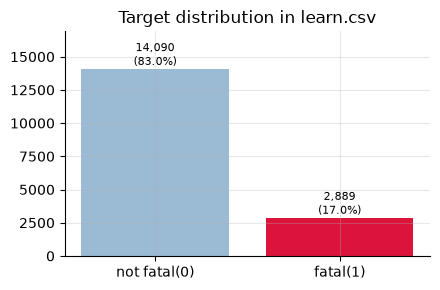

'always 0' → F1 = 0 (it never finds a fatal accident), accuracy = 83.0%
'always 1' → precision = 0.170, recall = 1, F1 = 0.291, accuracy = 17.0%


In [ ]:
counts = learn["fatal"].value_counts().sort_index()
print(pd.DataFrame({"n": counts, "share": (counts / counts.sum()).round(3)}))

fig, ax = plt.subplots(figsize=(4.5, 3))
ax.bar(["not fatal(0)", "fatal(1)"], counts.values, color=["#9bbbd4", "crimson"])
for i, n in enumerate(counts.values):
    ax.text(i, n, f"{n:,}\n({n / counts.sum():.1%})", ha="center", va="bottom", fontsize=8)
ax.set_ylim(0, counts.max() * 1.2); ax.set_title("Target distribution in learn.csv")
plt.tight_layout(); plt.show()

# F1 of the two trivial strategies, to understand the metric
p = BASE
print(f"'always 0' → F1 = 0 (it never finds a fatal accident), accuracy = {1 - p:.1%}")
print(f"'always 1' → precision = {p:.3f}, recall = 1, F1 = {2 * p / (1 + p):.3f}, accuracy = {p:.1%}")

- The classes are **imbalanced**: about **1 accident in 6 is fatal** (≈17%), as the brief says.
- This is why **accuracy is the wrong metric**. Predicting "never fatal" gives ~83% accuracy and F1 = 0. Predicting "always fatal" gives F1 ≈ 0.29. **Any real model has to beat F1 ≈ 0.29.**
- F1 on class 1 balances precision and recall of the fatal class, so the **decision threshold** matters: 0.5 on predicted probabilities will probably not be optimal.

**→ NB1:** use **stratified** splits / cross-validation; evaluate with F1 (also report precision and recall); try class weights or resampling **inside** the CV only; tune the decision threshold on validation data, never on `predict`.

## 1.3 Missing values

23 of 40 features have missing values


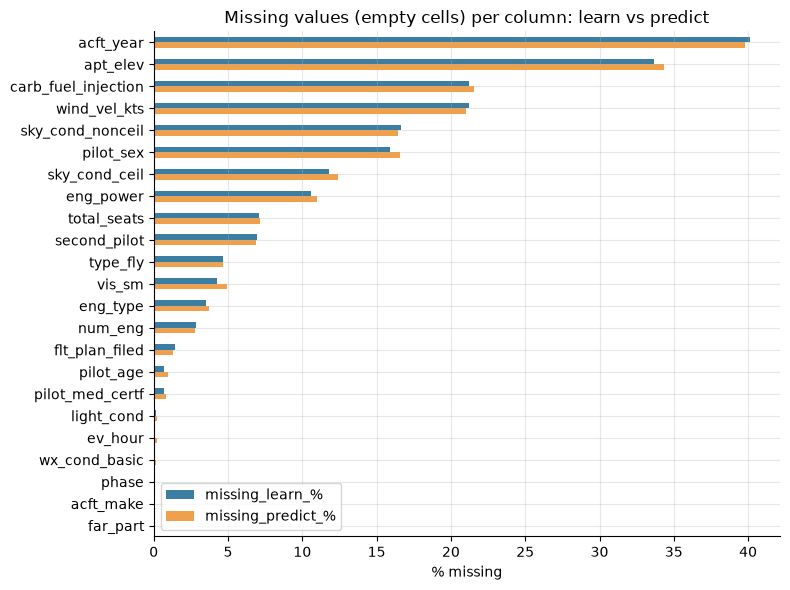

,missing_learn_%,missing_predict_%
acft_year,40.14,39.81
apt_elev,33.64,34.37
carb_fuel_injection,21.25,21.53
wind_vel_kts,21.22,21.04
sky_cond_nonceil,16.61,16.42
pilot_sex,15.88,16.58
sky_cond_ceil,11.79,12.39
eng_power,10.61,11.02
total_seats,7.10,7.18
second_pilot,6.97,6.86


In [ ]:
miss = pd.DataFrame({
    "missing_learn_%": learn.drop(columns="fatal").isna().mean() * 100,
    "missing_predict_%": predict.isna().mean() * 100,
}).round(2)
miss = miss[miss.max(axis=1) > 0].sort_values("missing_learn_%", ascending=False)
print(f"{len(miss)} of 40 features have missing values")

ax = miss.plot.barh(figsize=(8, 6), color=["#3b7ea1", "#f0a04b"])
ax.invert_yaxis(); ax.set_xlabel("% missing"); ax.set_title("Missing values (empty cells) per column: learn vs predict")
plt.tight_layout(); plt.show()
miss

- **23 of the 40 features** have empty cells, and 86% of the rows have at least one missing value, so dropping rows with NaN is not an option: we would lose almost all the data.
- Missingness comes in three levels:
  - **heavy:** `acft_year` (~40%), `apt_elev` (~34%), `wind_vel_kts`, `carb_fuel_injection` (~21%)
  - **medium:** `sky_cond_nonceil`, `pilot_sex`, `sky_cond_ceil`, `eng_power` (10–17%)
  - **light:** the rest (< 8%)
- learn and predict have almost the same missing rates, so the data was collected the same way. Whatever strategy we choose will behave the same on `predict`.
- As we will see later many columns have missing values as `0` instead of Nan, this is a problem that will be needed to take care of.

**→ NB1:** a strategy per column (median/mode imputation, a `"MISSING"` category for categoricals, or missing indicators), fitted on the training folds only.

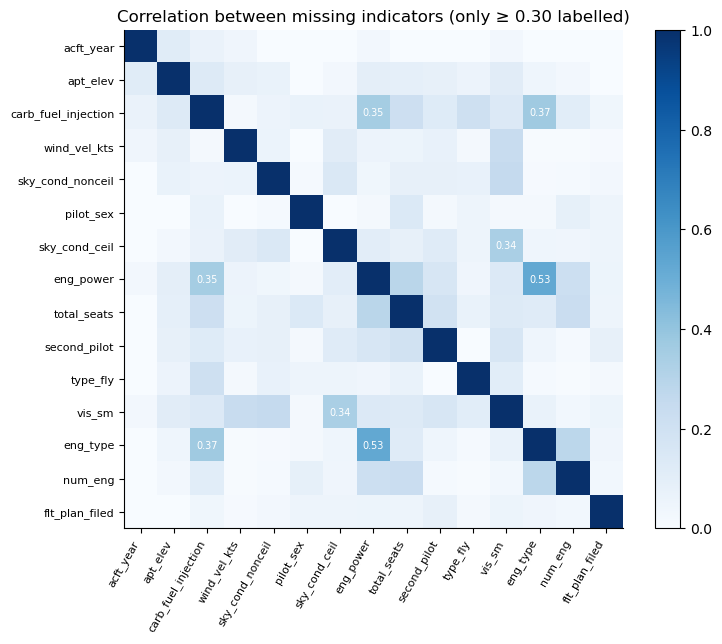

most related missing pairs:
 eng_power            eng_type       0.53
carb_fuel_injection  eng_type       0.37
                     eng_power      0.35
sky_cond_ceil        vis_sm         0.34
eng_power            total_seats    0.29
eng_type             num_eng        0.28
sky_cond_nonceil     vis_sm         0.25
wind_vel_kts         vis_sm         0.24


In [ ]:
# Do columns tend to be missing on the same rows? Correlation between missing indicators.
cols = miss.index[miss["missing_learn_%"] >= 1]
M = learn[cols].isna().astype(int).corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(M, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols, fontsize=8); ax.grid(False)
for i in range(len(cols)):
    for j in range(len(cols)):
        if i != j and M.iloc[i, j] >= 0.3:
            ax.text(j, i, f"{M.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white")
plt.colorbar(im); ax.set_title("Correlation between missing indicators (only ≥ 0.30 labelled)")
plt.tight_layout(); plt.show()

pairs = M.where(np.triu(np.ones(M.shape), 1).astype(bool)).stack().sort_values(ascending=False)
print("most related missing pairs:\n", pairs.head(8).round(2).to_string())

Missing values are not scattered at random: they come in blocks that share a source.
- **Engine block** (`eng_type`, `eng_power`, `carb_fuel_injection`, `num_eng`, and `total_seats` to a lesser extent): the clearest group (correlations 0.3–0.5), so the engine record tends to be missing as a whole.
- **Weather block:** `vis_sm` goes missing together with `sky_cond_ceil`, `sky_cond_nonceil` and `wind_vel_kts` (0.25–0.35): an incomplete weather report.
- The correlations are moderate, not 1: the blocks overlap without being all-or-nothing.
- `acft_year` is mostly missing for a different reason, the accident year (shown in Part 4).

**→ NB1:** impute related columns consistently (e.g. one `engine_info_missing` flag instead of four), and prefer models that handle missingness well (tree-based) or add indicators.

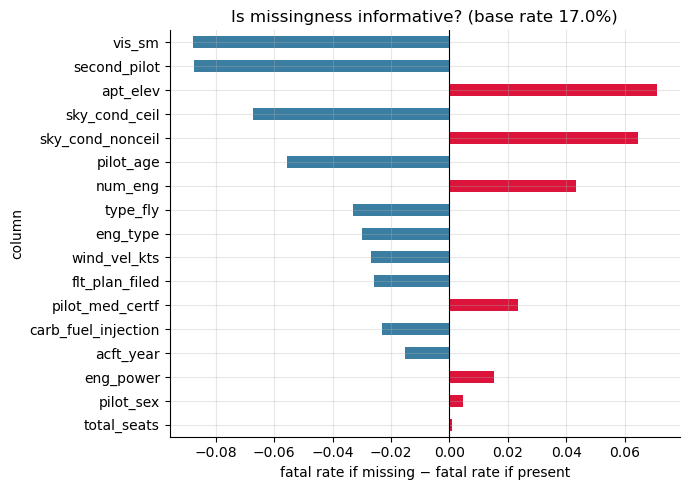

,n_missing,fatal_if_missing,fatal_if_present,difference
column,,,,
vis_sm,721,0.086,0.174,-0.088
second_pilot,1184,0.089,0.176,-0.088
apt_elev,5712,0.217,0.146,0.071
sky_cond_ceil,2002,0.111,0.178,-0.067
sky_cond_nonceil,2821,0.224,0.159,0.065
pilot_age,122,0.115,0.171,-0.056
num_eng,485,0.212,0.169,0.043
type_fly,787,0.139,0.172,-0.033
eng_type,602,0.141,0.171,-0.030


In [ ]:
# Is "missing" informative about the target? Fatal rate when the column is missing vs present (n >= 30 only).
rows = []
for c in miss.index:
    m = learn[c].isna()
    if m.sum() >= 30:
        rows.append((c, m.sum(), learn.loc[m, "fatal"].mean(), learn.loc[~m, "fatal"].mean()))
mt = pd.DataFrame(rows, columns=["column", "n_missing", "fatal_if_missing", "fatal_if_present"]).set_index("column")
mt["difference"] = mt.fatal_if_missing - mt.fatal_if_present
mt = mt.sort_values("difference", key=abs, ascending=False)

ax = mt["difference"].plot.barh(figsize=(7, 5), color=np.where(mt["difference"] > 0, "crimson", "#3b7ea1"))
ax.invert_yaxis(); ax.axvline(0, color="k", lw=.8)
ax.set_xlabel("fatal rate if missing − fatal rate if present"); ax.set_title(f"Is missingness informative? (base rate {BASE:.1%})")
plt.tight_layout(); plt.show()
mt.round(3)

We decided to only analyze rows with at least 30 missing values, as less than this can be considered noise, the rows are split into two groups:
    rows where the column is empty
    rows where it has a value

Then it computes the fatal rate in each group and plots the difference: fatal rate if missing − fatal rate if present.
- Red bar (positive): accidents where this column is missing are more often fatal than the others.
- Blue bar (negative): accidents where it's missing are less often fatal.
- Bar near 0: missing or not makes no difference. The value is "missing at random" with respect to the target.

For several columns the fact that a value is missing is itself a signal:
  - When `apt_elev` or `sky_cond_nonceil` is missing, the fatal rate is higher (~22% vs ~15%). A plausible story: crashes far from an airport, or with poorly documented conditions.


If we just impute the media this information will be lost, for **NB1** we should add a missing indicator feature, next to the imputed values.

## 1.4 Hidden missing values and inconsistent codes
The brief warns about *"odd codes, impossible values, inconsistent spellings"*. Here we look for **zeros that really mean "not recorded"**, and for categories spelled in more than one way. The details are studied in each part; this is the overview.

First lets check which columns have zeros, and from those we will only evaluate the ones where the 0 is an actual integer, as in some it is used as a true or false.

In [ ]:
has0 = learn.loc[:, (learn == 0).any(axis=0)]
has0

,ev_hour,sky_ceil_ht,vis_sm,wx_temp,wx_temp_c,wx_dew_pt,wind_dir_deg,wind_vel_kts,gust_kts,altimeter,apt_dist,apt_elev,ifr_equipped_cert,num_eng,total_seats,acft_year,eng_power,pilot_age,fatal
0,19.0,0,10.0,59,15.0,49,38,7.0,0,30.06,0,NaN,0,1.0,2.0,1956.0,NaN,71.0,0
1,17.0,0,5.0,70,21.1,56,0,3.0,0,29.91,9,629.0,0,1.0,2.0,NaN,108.0,17.0,1
2,22.0,0,10.0,80,26.7,73,0,10.0,17,30.06,0,NaN,0,1.0,2.0,NaN,84.0,46.0,0
3,0.0,10208,10.0,80,26.7,33,261,6.0,0,30.07,0,NaN,1,1.0,4.0,1976.0,150.0,31.0,1
4,1.0,0,10.0,62,16.7,36,261,13.0,18,29.90,0,3092.0,0,1.0,4.0,NaN,174.0,68.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16974,18.0,7055,10.0,67,19.4,36,251,14.0,20,29.93,0,1141.0,0,1.0,2.0,2008.0,119.0,65.0,0
16975,21.0,7987,10.0,36,2.2,27,309,18.0,30,29.67,1,1454.0,1,2.0,8.0,1984.0,422.0,63.0,0
16976,20.0,879,NaN,17,-8.3,11,117,5.0,0,30.27,0,1630.0,1,2.0,6.0,1972.0,370.0,68.0,0
16977,2.0,14178,10.0,57,13.9,0,304,NaN,0,0.00,0,NaN,0,1.0,4.0,NaN,268.0,44.0,0


In [ ]:
zero_cols = ["wx_temp", "wx_dew_pt", "altimeter", "wind_dir_deg", "sky_ceil_ht", "gust_kts",
             "apt_dist", "eng_power", "total_seats", "pilot_age", "acft_year"]
plausible = {  # is 0 a physically possible value?
    "wx_temp": "rare (0 °F) but possible", "wx_dew_pt": "rare but possible", "altimeter": "IMPOSSIBLE",
    "wind_dir_deg": "possible only with calm wind", "sky_ceil_ht": "means 'no ceiling'?",
    "gust_kts": "yes, no gusts", "apt_dist": "yes, at the airport", "eng_power": "IMPOSSIBLE (powered)",
    "total_seats": "only gliders/balloons?", "pilot_age": "IMPOSSIBLE", "acft_year": "IMPOSSIBLE"}
z = pd.DataFrame({
    "zeros_learn": [(learn[c] == 0).sum() for c in zero_cols],
    "zeros_%": [round((learn[c] == 0).mean() * 100, 1) for c in zero_cols],
    "zeros_predict_%": [round((predict[c] == 0).mean() * 100, 1) for c in zero_cols],
    "fatal_if_0": [learn.loc[learn[c] == 0, "fatal"].mean() for c in zero_cols],
    "fatal_if_not_0": [learn.loc[learn[c] != 0, "fatal"].mean() for c in zero_cols],
    "is 0 plausible?": [plausible[c] for c in zero_cols],
}, index=zero_cols).round(3)
z

,zeros_learn,zeros_%,zeros_predict_%,fatal_if_0,fatal_if_not_0,is 0 plausible?
wx_temp,855,5.0,5.0,0.067,0.176,rare (0 °F) but possible
wx_dew_pt,1639,9.7,9.9,0.057,0.182,rare but possible
altimeter,1510,8.9,8.7,0.056,0.181,IMPOSSIBLE
wind_dir_deg,4387,25.8,26.1,0.148,0.178,possible only with calm wind
sky_ceil_ht,12834,75.6,76.0,0.145,0.247,means 'no ceiling'?
gust_kts,14358,84.6,84.0,0.171,0.163,"yes, no gusts"
apt_dist,13119,77.3,77.6,0.141,0.268,"yes, at the airport"
eng_power,171,1.0,0.8,0.129,0.171,IMPOSSIBLE (powered)
total_seats,37,0.2,0.1,0.027,0.170,only gliders/balloons?
pilot_age,4,0.0,0.0,0.000,0.170,IMPOSSIBLE


In [ ]:
# The weather zeros come together: is it one missing weather observation?
w0 = (learn.wx_temp == 0) & (learn.wx_dew_pt == 0) & (learn.altimeter == 0)
print(f"rows with temp = dew point = altimeter = 0: {w0.sum()} ({w0.mean():.1%}) · in predict: {((predict.wx_temp == 0) & (predict.wx_dew_pt == 0) & (predict.altimeter == 0)).mean():.1%}")
print(f"fatal rate in those rows: {learn.loc[w0, 'fatal'].mean():.1%} vs {learn.loc[~w0, 'fatal'].mean():.1%} elsewhere")
print(f"wind_dir_deg = 0 and wind_vel_kts empty: {((learn.wind_dir_deg == 0) & learn.wind_vel_kts.isna()).sum()} of {(learn.wind_dir_deg == 0).sum()} zero directions")

print("\ngust_ind vs gust_kts > 0 (does the indicator agree with the speed?):")
print(pd.crosstab(learn.gust_ind, learn.gust_kts > 0, rownames=["gust_ind"], colnames=["gust_kts > 0"]))

rows with temp = dew point = altimeter = 0: 771 (4.5%) · in predict: 4.5%
fatal rate in those rows: 6.1% vs 17.5% elsewhere
wind_dir_deg = 0 and wind_vel_kts empty: 3543 of 4387 zero directions

gust_ind vs gust_kts > 0 (does the indicator agree with the speed?):
gust_kts > 0  False  True 
gust_ind                  
F              3429   2616
T             10929      5


- Weather. In 771 rows (4.5%, the same share in `predict`) temperature, dew point and altimeter are all 0. An altimeter of 0 inHg is impossible, so these rows are a whole missing weather observation coded as zeros. Their fatal rate is very different from the others (~6% vs ~18%), so the missingness is informative. Likewise, almost every `wind_dir_deg = 0` comes with an empty `wind_vel_kts`: it is "not recorded", not "north".
- `gust_ind` seems to be inverted: `T` almost never comes with a gust speed > 0, while `F` often does. Either the code means the opposite of what we expect, or it is broken. 

**→ NB1:** replace the impossible zeros with NaN **before** imputation (otherwise medians and means are biased); add a `weather_obs_missing` flag; decide `gust_ind` together with Part 3.

In [ ]:
# Categories spelled in more than one way (same value, different case or spaces)
rows = []
for c in learn.select_dtypes("object").columns.drop("row_id"):
    s = pd.concat([learn[c], predict[c]]).dropna().astype(str)
    raw, norm = s.nunique(), s.str.strip().str.upper().nunique()
    if raw != norm:
        rows.append((c, raw, norm, (s != s.str.strip().str.upper()).mean() * 100))
pd.DataFrame(rows, columns=["column", "distinct_raw", "distinct_after_upper_strip", "% rows affected"]).round(1)

,column,distinct_raw,distinct_after_upper_strip,% rows affected
0,acft_category,20,11,24.8
1,homebuilt,4,2,25.2
2,second_pilot,4,2,25.2


A few text columns contain the same category written in different cases (e.g. `AIR`/`air`, `Y`/`y`, `N`/`n`), in about a quarter of their rows and in both files. A model would see them as different levels and split the information. Part 4 shows that lowercase carries no information (same fatal rate). `acft_make` also has spelling variants beyond case (Part 4).

**→ NB1:** one cleaning function (strip + upper) applied to every text column of `learn` and `predict`.

## 1.5 learn vs predict: do they come from the same distribution?
If `predict` looked very different from `learn` (other years, other kinds of aircraft), a model validated on `learn` would perform worse on Kaggle than expected.

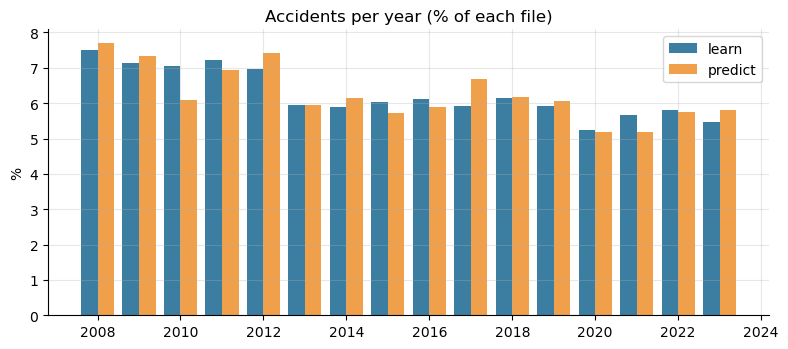

share of accidents in 2008-2013 · learn: 41.8% · predict: 41.4%


In [ ]:
# ev_year in both files (Part 4 needs this: is the missing acft_year of 2008-2013 also in predict?)
yl = learn.ev_year.value_counts(normalize=True).sort_index()
yp = predict.ev_year.value_counts(normalize=True).sort_index()
fig, ax = plt.subplots(figsize=(8, 3.6))
w = .4
ax.bar(yl.index - w / 2, yl.values * 100, w, label="learn", color="#3b7ea1")
ax.bar(yp.index + w / 2, yp.values * 100, w, label="predict", color="#f0a04b")
ax.set_title("Accidents per year (% of each file)"); ax.set_ylabel("%"); ax.legend()
plt.tight_layout(); plt.show()
print(f"share of accidents in 2008-2013 · learn: {(learn.ev_year <= 2013).mean():.1%} · predict: {(predict.ev_year <= 2013).mean():.1%}")

In [ ]:
# Numeric columns: compare mean and median; standardised mean difference (SMD) = |mean_l - mean_p| / std_l
num = learn.select_dtypes("number").columns.drop("fatal")
cmp_num = pd.DataFrame({
    "mean_learn": learn[num].mean(), "mean_predict": predict[num].mean(),
    "median_learn": learn[num].median(), "median_predict": predict[num].median(),
})
cmp_num["SMD"] = ((cmp_num.mean_learn - cmp_num.mean_predict).abs() / learn[num].std())
display(cmp_num.sort_values("SMD", ascending=False).round(3))

# Categorical columns: total variation distance between the two frequency distributions (0 = identical, 1 = disjoint)
cat = learn.select_dtypes("object").columns.drop("row_id")
tvd = {c: 0.5 * (learn[c].value_counts(normalize=True, dropna=False)
                 .sub(predict[c].value_counts(normalize=True, dropna=False), fill_value=0).abs().sum()) for c in cat}
pd.Series(tvd, name="TVD learn vs predict").sort_values(ascending=False).round(3).to_frame()

,mean_learn,mean_predict,median_learn,median_predict,SMD
eng_power,695.357,521.758,189.00,189.0,0.038
sky_ceil_ht,1575.381,1441.016,0.00,0.0,0.030
gust_kts,3.152,3.417,0.00,0.0,0.024
total_seats,6.633,4.974,4.00,4.0,0.021
wx_temp,63.992,63.339,69.00,69.0,0.020
wx_temp_c,17.772,17.410,20.60,20.6,0.020
ifr_equipped_cert,0.170,0.178,0.00,0.0,0.020
wind_dir_deg,142.211,140.130,146.00,145.0,0.018
ev_hour,15.687,15.608,17.00,17.0,0.012
vis_sm,10.698,10.063,10.00,10.0,0.012


,TVD learn vs predict
acft_make,0.217
phase,0.021
carb_fuel_injection,0.015
type_fly,0.014
acft_category,0.013
sky_cond_ceil,0.012
ev_dow,0.012
light_cond,0.010
flt_plan_filed,0.010
homebuilt,0.009



- **Years:** `predict` covers the same 2008–2023 period with the same proportions, including the early years where `acft_year` is almost always missing. So an `acft_year_missing` indicator behaves the same in `predict`(answer to Part 4's question).
- **Numeric columns:** every standardised mean difference is below 0.04 (0.1 is a common threshold for a meaningful shift). The means of `eng_power` and `total_seats` differ a bit because of a few huge outliers (Part 4); the medians are identical.
- **Categorical columns:** every distance is ≤ 0.02 except `acft_make` (0.22), which is expected with ~2,900 rare values: many makes appear in only one of the files (Part 4: ~13% of `predict` rows have a make never seen in `learn`).
- **Conclusion:** `predict` looks like a random sample from the same population as `learn`. A stratified cross-validation on `learn` should give a fair estimate of the Kaggle score.

**→ NB1:** use stratified K-fold CV as the main evaluation; handle categories unseen in training (`handle_unknown`).

## 1.6 Correlations between numeric features
Spearman (rank) correlation, because many columns are skewed and full of outliers. Note: this uses the raw data, so hidden zeros (1.4) still distort some values.

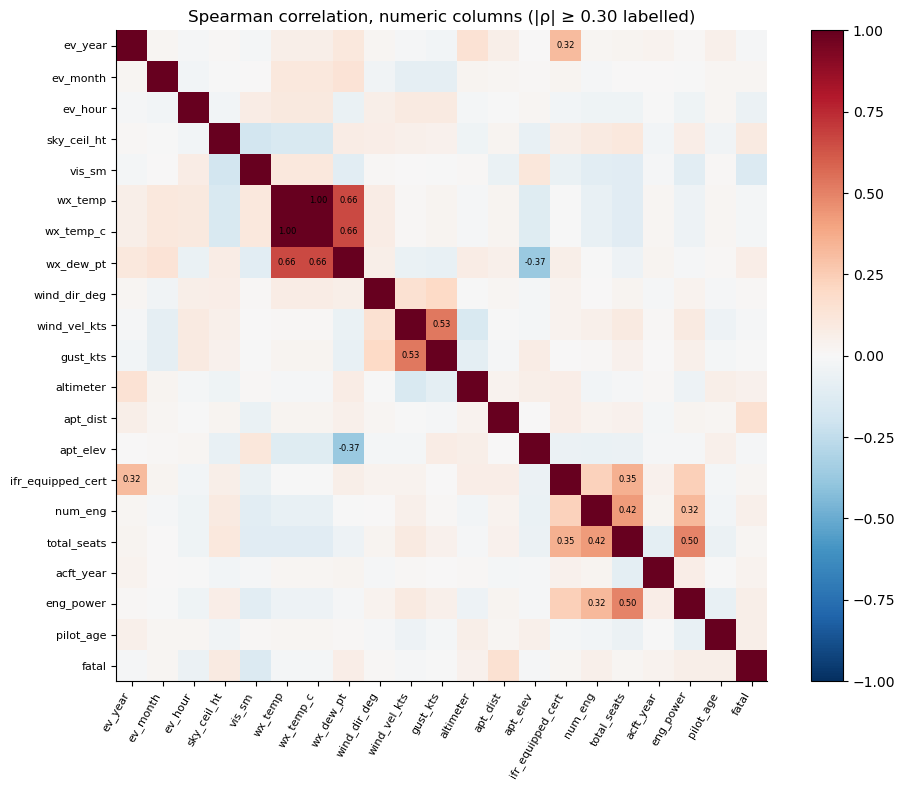

strongest pairs between features:
 wx_temp            wx_temp_c      1.000
wx_temp_c          wx_dew_pt      0.661
wx_temp            wx_dew_pt      0.661
wind_vel_kts       gust_kts       0.526
total_seats        eng_power      0.495
num_eng            total_seats    0.422
wx_dew_pt          apt_elev      -0.370
ifr_equipped_cert  total_seats    0.352

strongest correlations with fatal:
 apt_dist       0.149
vis_sm        -0.135
sky_ceil_ht    0.090
wx_dew_pt      0.066
pilot_age      0.059
eng_power      0.056
ev_hour       -0.055
num_eng        0.052


In [ ]:
num_all = learn.select_dtypes("number").columns
C = learn[num_all].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(C))); ax.set_xticklabels(C.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(C))); ax.set_yticklabels(C.columns, fontsize=8); ax.grid(False)
for i in range(len(C)):
    for j in range(len(C)):
        if i != j and abs(C.iloc[i, j]) >= 0.3:
            ax.text(j, i, f"{C.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6)
plt.colorbar(im); ax.set_title("Spearman correlation, numeric columns (|ρ| ≥ 0.30 labelled)")
plt.tight_layout(); plt.show()

pairs = C.where(np.triu(np.ones(C.shape), 1).astype(bool)).stack()
print("strongest pairs between features:\n", pairs.drop(index="fatal", level=1, errors="ignore")
      .sort_values(key=abs, ascending=False).head(8).round(3).to_string())
print("\nstrongest correlations with fatal:\n", C["fatal"].drop("fatal").sort_values(key=abs, ascending=False).head(8).round(3).to_string())


**Redundant pairs:**
  - `wx_temp` / `wx_temp_c` (ρ = 1, already known).
  - `wx_temp` and `wx_dew_pt` (~0.66): partly physics, partly the shared zeros.
  - `wind_vel_kts` and `gust_kts` (~0.53).
  - The aircraft-size group `total_seats`, `eng_power`, `num_eng`, `ifr_equipped_cert` (0.2–0.5), consistent with Part 4.

**With the target, every single numeric correlation is weak** (|ρ| ≤ ~0.15). The strongest are `apt_dist` (further from an airport → more fatal), `vis_sm` (lower visibility → more fatal) and `sky_ceil_ht`.
  - No single numeric feature separates the classes. Performance will come from **combining** features, including categoricals such as `phase` and `light_cond`, which this matrix does not show.
  - Non-linear models (trees, boosting) are likely to do better than a plain linear model.

**→ NB1:** drop `wx_temp_c`; watch multicollinearity if a linear model is used.

# ━━━━━━━━━━ PART 2 · When and where (Person 2) ━━━━━━━━━━

Columns covered (7): `ev_year`, `ev_month`, `ev_dow`, `ev_hour`, `light_cond`, `apt_dist`, `apt_elev`.

NB0 does not change the data and does not train models. Any temporary grouping or cleaning needed to inspect a pattern is done on a throw-away copy `T`, and all real transformations are recorded as decisions for NB1 at the end of this part.


In [2]:
GROUP_P2 = ["ev_year", "ev_month", "ev_dow", "ev_hour", "light_cond", "apt_dist", "apt_elev"]
T = learn.copy()  

## Part 2 · 1. Overview of the group

**What we do:** data types, missing values and cardinality of the 7 columns, in `learn` and in `predict`.

In [3]:
ov_p2 = pd.DataFrame({
    "dtype": learn[GROUP_P2].dtypes.astype(str),
    "missing_learn_%": (learn[GROUP_P2].isna().mean() * 100).round(2),
    "missing_predict_%": (predict[GROUP_P2].isna().mean() * 100).round(2),
    "n_unique": learn[GROUP_P2].nunique(),
})
ov_p2

,dtype,missing_learn_%,missing_predict_%,n_unique
ev_year,int64,0.00,0.00,16
ev_month,int64,0.00,0.00,12
ev_dow,str,0.00,0.00,7
ev_hour,float64,0.11,0.24,24
light_cond,str,0.15,0.21,7
apt_dist,int64,0.00,0.00,142
apt_elev,float64,33.64,34.37,3579


**Interpretation.**
- Almost all columns are complete or nearly complete (`ev_hour` ~0.1%, `light_cond` ~0.2% missing), except **`apt_elev`**, which is missing in **33.6%** of `learn` and **34.4%** of `predict`.
- Missing rates match closely between `learn` and `predict`, indicating no collection shift between splits.
- `apt_dist` has 0% missing values on paper, which is suspicious given `apt_elev`'s 33.6% missingness (investigated in section 4).

**→ NB1:** `ev_hour` and `light_cond` only need simple missing handling; `apt_elev` and `apt_dist` require joint treatment (see sections 4 and 5).

## Part 2 · 2. Fatal rate over time: year, month, weekday and hour

**What we do:** inspect the accident volume and fatal rate across `ev_year`, `ev_month`, `ev_dow` and `ev_hour`. We also compare the `ev_year` distribution between `learn` and `predict` (important for checking temporal split vs random split, and for Person 4's `acft_year` missingness question).

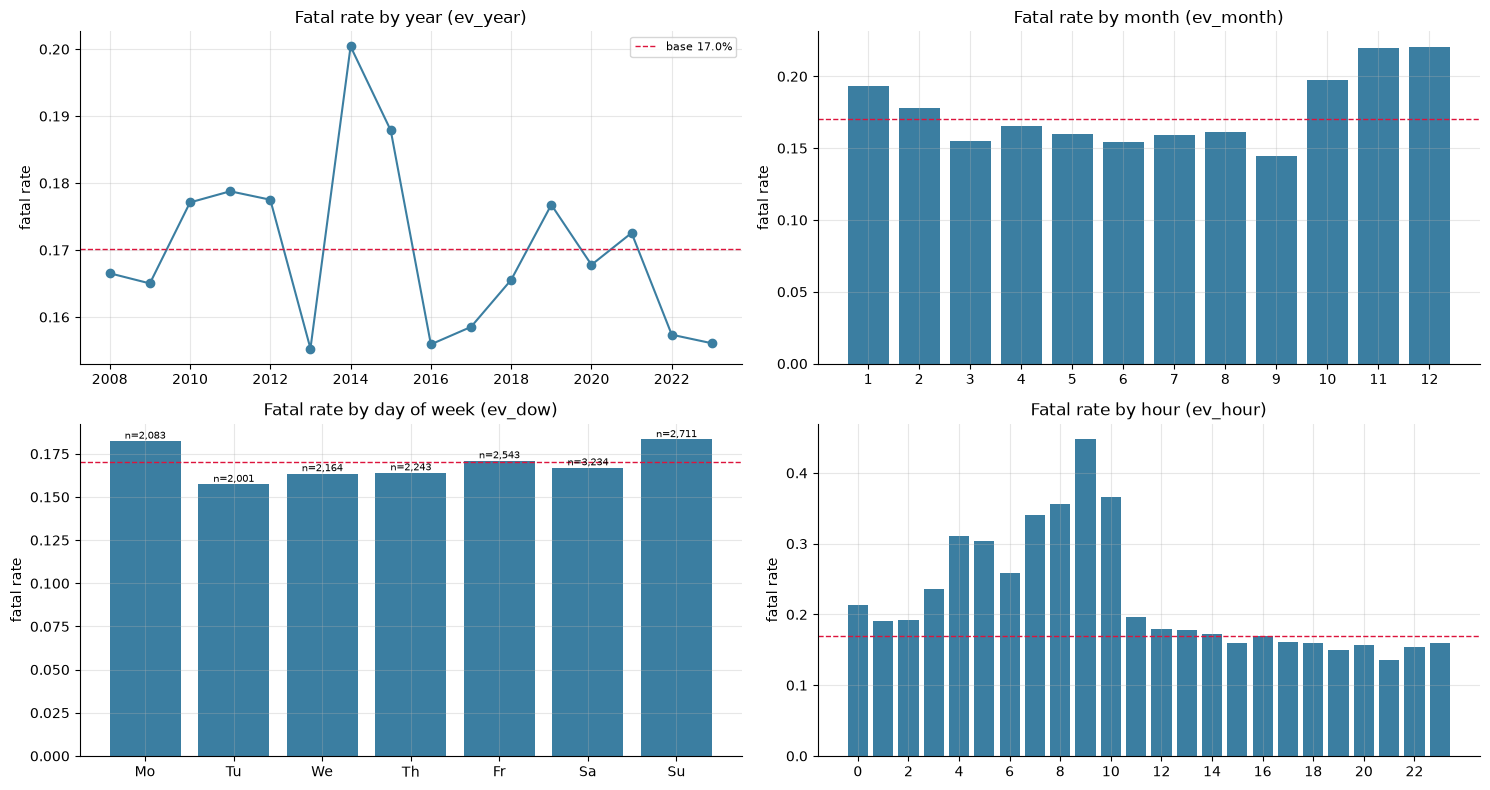

ev_year share (%) in learn vs predict (max abs diff: 0.97 pp):
ev_year    2008  2009  2010  2011  2012  2013  2014  2015  2016  2017  2018  2019  2020  2021  2022  2023
learn_%     7.5  7.14  7.05  7.21  6.97  5.95  5.88  6.02  6.12  5.91  6.15  5.93  5.23  5.67  5.80  5.47
predict_%   7.7  7.33  6.08  6.95  7.42  5.94  6.15  5.72  5.89  6.69  6.17  6.05  5.18  5.18  5.75  5.80

Rows with missing ev_hour: 19 · fatal rate: 0.684


In [4]:
dow_order = ["Mo", "Tu", "We", "Th", "Fr", "Sa", "Su"]

fig, ax = plt.subplots(2, 2, figsize=(15, 8))

# Year
yr = T.groupby("ev_year")["fatal"].agg(rate="mean", n="size")
ax[0, 0].plot(yr.index, yr["rate"], marker="o", color="#3b7ea1")
ax[0, 0].axhline(BASE, color="crimson", ls="--", lw=1, label=f"base {BASE:.1%}")
ax[0, 0].set_title("Fatal rate by year (ev_year)"); ax[0, 0].set_ylabel("fatal rate"); ax[0, 0].legend(fontsize=8)

# Month
mo = T.groupby("ev_month")["fatal"].agg(rate="mean", n="size")
ax[0, 1].bar(mo.index, mo["rate"], color="#3b7ea1")
ax[0, 1].axhline(BASE, color="crimson", ls="--", lw=1)
ax[0, 1].set_xticks(range(1, 13)); ax[0, 1].set_title("Fatal rate by month (ev_month)"); ax[0, 1].set_ylabel("fatal rate")

# Day of week
dw = T.groupby("ev_dow")["fatal"].agg(rate="mean", n="size").loc[dow_order]
ax[1, 0].bar(dw.index, dw["rate"], color="#3b7ea1")
ax[1, 0].axhline(BASE, color="crimson", ls="--", lw=1)
for i, (r, n) in enumerate(zip(dw["rate"], dw["n"])):
    ax[1, 0].text(i, r, f"n={n:,}", ha="center", va="bottom", fontsize=7)
ax[1, 0].set_title("Fatal rate by day of week (ev_dow)"); ax[1, 0].set_ylabel("fatal rate")

# Hour
hr = T.groupby("ev_hour")["fatal"].agg(rate="mean", n="size")
ax[1, 1].bar(hr.index, hr["rate"], color="#3b7ea1")
ax[1, 1].axhline(BASE, color="crimson", ls="--", lw=1)
ax[1, 1].set_xticks(range(0, 24, 2)); ax[1, 1].set_title("Fatal rate by hour (ev_hour)"); ax[1, 1].set_ylabel("fatal rate")

plt.tight_layout(); plt.show()

# Check ev_year stability between learn and predict
yr_cmp = pd.DataFrame({
    "learn_%": (learn["ev_year"].value_counts(normalize=True) * 100).round(2),
    "predict_%": (predict["ev_year"].value_counts(normalize=True) * 100).round(2),
}).sort_index()
print("ev_year share (%) in learn vs predict (max abs diff:",
      f"{(yr_cmp['learn_%'] - yr_cmp['predict_%']).abs().max():.2f} pp):")
print(yr_cmp.T)
print("\nRows with missing ev_hour:", T["ev_hour"].isna().sum(),
      "· fatal rate:", round(T.loc[T["ev_hour"].isna(), "fatal"].mean(), 3))

**Interpretation.**
- **`ev_year`:** fatal rate is fairly stable across 2008–2023 (15.5%–20.0%, no strong trend). Importantly, **`learn` and `predict` have almost identical year distributions** (max difference < 1 percentage point), confirming a random (non-temporal) split across 2008–2023.
- **`ev_month`:** clear seasonal pattern. Summer months (Jun–Sep) have the highest accident volume (~1,700–2,160/month) but lower fatal rates (**14.5%–16.2%**), whereas late autumn and winter (Oct–Jan) have fewer accidents (~880–1,350/month) and noticeably higher fatal rates (**19.3%–22.0%**, peaking in Nov–Dec), likely tied to worse weather and shorter daylight.
- **`ev_dow`:** weak signal. Volume peaks on weekends (Saturday 3,234, Sunday 2,711), while fatal rate barely moves (15.7% on Tuesday to 18.3% on Sunday).
- **`ev_hour`:** strong signal — **and a major surprise**. Fatal rate surges to **26%–45% between hours 04 and 10** (where volume is lowest: 38–145 rows/hour) and stays around **14%–17% between hours 14 and 23** (where volume peaks at ~1,200–1,500/hour). That is inverted relative to US local daytime, which points directly to a timezone issue (checked next). Also, the 19 rows with missing `ev_hour` have a **68.4%** fatal rate.

**→ NB1:** encode `ev_month` and `ev_hour` cyclically (`sin`/`cos`) or let tree models split on them; add an `ev_hour_missing` flag; `ev_year` and `ev_dow` are weak standalone features (keep or test in feature selection).

## Part 2 · 3. Light vs time: does `light_cond` agree with `ev_hour`?

**What we do:** check `light_cond` against `fatal` and cross-tabulate `ev_hour` against `light_cond` to test whether `ev_hour` is truly local time as stated in `data_dictionary.md`.

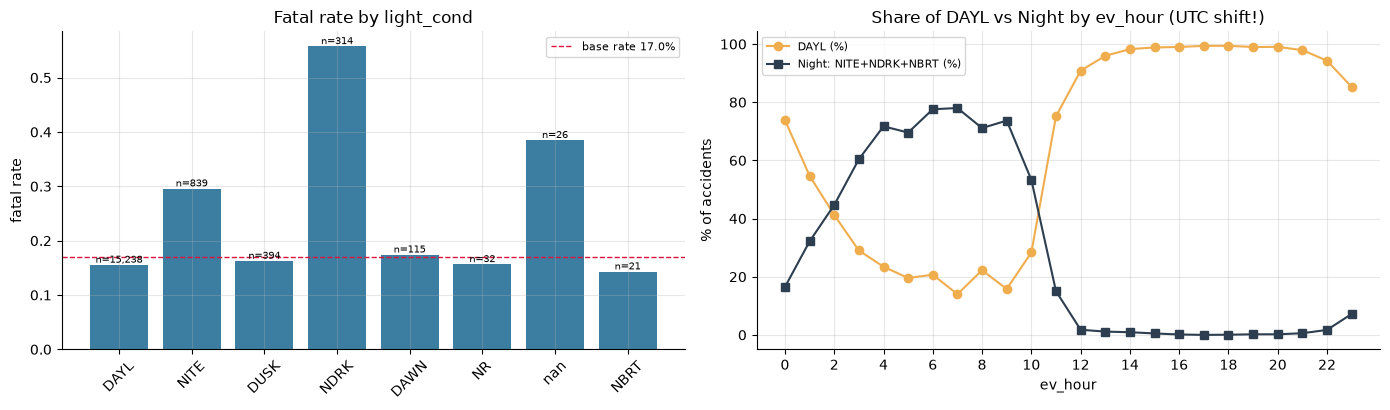

DAWN peak hours: {12: 22, 11: 17, 13: 15, 10: 8}
DUSK peak hours: {23: 85, 0: 75, 1: 72, 2: 48}


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
plot_cat_vs_target(T, "light_cond", min_n=1, ax=ax[0], title="Fatal rate by light_cond")

ct = pd.crosstab(T["ev_hour"].dropna().astype(int), T["light_cond"].fillna("NaN"))
night_cols = [c for c in ["NITE", "NDRK", "NBRT"] if c in ct.columns]
day_share = ct["DAYL"] / ct.sum(axis=1) * 100
night_share = ct[night_cols].sum(axis=1) / ct.sum(axis=1) * 100

ax[1].plot(ct.index, day_share, marker="o", label="DAYL (%)", color="#f0ad4e")
ax[1].plot(ct.index, night_share, marker="s", label="Night: NITE+NDRK+NBRT (%)", color="#2c3e50")
ax[1].set_xticks(range(0, 24, 2)); ax[1].set_xlabel("ev_hour"); ax[1].set_ylabel("% of accidents")
ax[1].set_title("Share of DAYL vs Night by ev_hour (UTC shift!)"); ax[1].legend(fontsize=8)

plt.tight_layout(); plt.show()

print("DAWN peak hours:", ct["DAWN"].sort_values(ascending=False).head(4).to_dict())
print("DUSK peak hours:", ct["DUSK"].sort_values(ascending=False).head(4).to_dict())

**Interpretation.**
- **`light_cond` is a very strong predictor:** `DAYL` (90% of rows) has a **15.5%** fatal rate, `NITE` jumps to **29.6%**, and **`NDRK` (night, dark) reaches 55.7%** (more than 3× the base rate). Missing `light_cond` (26 rows) is also high at **38.5%**.
- **`ev_hour` does NOT match US local time — it is in UTC** (shifted ~5–8 hours ahead of US time zones, contradicting `data_dictionary.md`):
  - `DAYL` accounts for **94%–99%** of accidents between `ev_hour` 13 and 22 (US daytime in UTC).
  - `DAWN` peaks at hours **11–13** (~6–8 AM US local).
  - `DUSK` peaks at hours **23–01** (~6–8 PM US local).
  - Night (`NITE`/`NDRK`/`NBRT`) dominates between hours **03 and 10**, explaining why those hours had the 30%–45% fatal rates in section 2.
- Because the US spans multiple time zones (UTC-5 to UTC-8, plus Alaska/Hawaii) and daylight saving time changes through the year, `ev_hour` is a noisy proxy for actual darkness, whereas `light_cond` measures it directly.

**→ NB1:** treat `light_cond` as a key feature (keep `NDRK` separate from `NITE`/`NBRT` — do not collapse all night codes into one, since `NDRK` is 55.7% vs `NITE` 29.6%); keep `NaN`/`NR` explicit. For `ev_hour`, remember it is UTC (cyclic encoding still works fine for models, and `ev_hour` + `light_cond` together capture both time-of-day traffic patterns and true lighting).

## Part 2 · 4. Distance to airport: is `apt_dist = 0` real or a missing-value code?

**What we do:** 77.3% of `learn` (and 77.6% of `predict`) have `apt_dist == 0`. We test whether zero means "at the airport" or "missing" by crossing `apt_dist == 0` with `phase`, `apt_elev.isna()` and `fatal`, and by checking extreme values.

apt_dist == 0: 77.3% in learn · 77.6% in predict
apt_dist > 100 in learn: 70 · max: 7208 · max in predict: 7654

4 quadrants (apt_dist == 0 x apt_elev missing):
                              group  rate    n
 dist=0 & elev present (on-airport) 0.085 7533
   dist=0 & elev NaN (missing code) 0.217 5586
dist>0 & elev present (off-airport) 0.269 3734
                  dist>0 & elev NaN 0.246  126

% of apt_dist == 0 by top flight phases:
               pct_zero     n
phase                        
Landing            88.7  5435
Enroute            75.7  2751
Maneuvering        79.3  2243
Takeoff            81.8  2027
Approach           55.0  1925
Initial climb      57.0  1716
Taxi               87.1   394
Standing           90.1   202


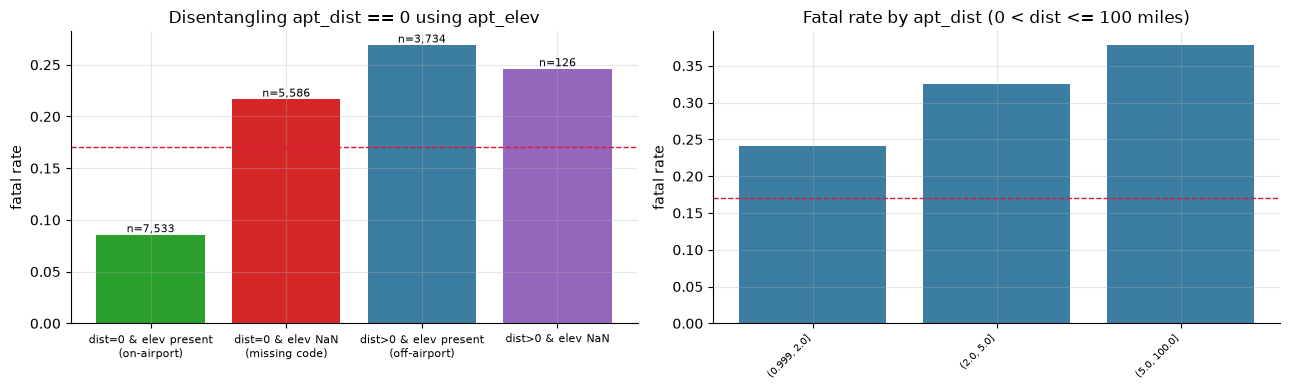

In [6]:
print(f"apt_dist == 0: {(T.apt_dist == 0).mean():.1%} in learn · {(predict.apt_dist == 0).mean():.1%} in predict")
print("apt_dist > 100 in learn:", (T.apt_dist > 100).sum(), "· max:", T.apt_dist.max(),
      "· max in predict:", predict.apt_dist.max())

# 4-way breakdown: apt_dist == 0 vs apt_elev missing
g1 = T[(T["apt_dist"] == 0) & (T["apt_elev"].notna())]
g2 = T[(T["apt_dist"] == 0) & (T["apt_elev"].isna())]
g3 = T[(T["apt_dist"] > 0) & (T["apt_elev"].notna())]
g4 = T[(T["apt_dist"] > 0) & (T["apt_elev"].isna())]

groups = [g1, g2, g3, g4]
labels = ["dist=0 & elev present\n(on-airport)", "dist=0 & elev NaN\n(missing code)",
          "dist>0 & elev present\n(off-airport)", "dist>0 & elev NaN"]
rates = [g["fatal"].mean() for g in groups]
ns = [len(g) for g in groups]

q4 = pd.DataFrame({"group": [l.replace("\n", " ") for l in labels],
                   "rate": [round(r, 3) for r in rates], "n": ns})
print("\n4 quadrants (apt_dist == 0 x apt_elev missing):")
print(q4.to_string(index=False))

# Phase breakdown for apt_dist == 0
ph = (T.groupby("phase")["apt_dist"]
        .agg(pct_zero=lambda s: (s == 0).mean() * 100, n="size")
        .sort_values("n", ascending=False).head(8))
print("\n% of apt_dist == 0 by top flight phases:")
print(ph.round(1))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(range(4), rates, color=["#2ca02c", "#d62728", "#3b7ea1", "#9467bd"])
ax[0].axhline(BASE, color="crimson", ls="--", lw=1)
ax[0].set_xticks(range(4)); ax[0].set_xticklabels(labels, fontsize=8)
for i, (r, n) in enumerate(zip(rates, ns)):
    ax[0].text(i, r, f"n={n:,}", ha="center", va="bottom", fontsize=8)
ax[0].set_ylabel("fatal rate"); ax[0].set_title("Disentangling apt_dist == 0 using apt_elev")

plot_num_vs_target(T[(T.apt_dist > 0) & (T.apt_dist <= 100)], "apt_dist", q=6, ax=ax[1],
                   title="Fatal rate by apt_dist (0 < dist <= 100 miles)")
plt.tight_layout(); plt.show()

**Interpretation.**
- **`apt_dist = 0` is BOTH real AND a missing-value code — mixed together:**
  - **Real on-airport accidents (`apt_dist == 0` & `apt_elev` present, n = 7,533):** fatal rate is only **8.5%** (half the base rate). Consistent with `Landing` (88.7% zero), `Takeoff` (81.8%) and `Taxi` (87.1%).
  - **Disguised missing values (`apt_dist == 0` & `apt_elev` is `NaN`, n = 5,586):** fatal rate jumps to **21.7%**. Notably, **75.7% of `Enroute`** and **79.3% of `Maneuvering`** accidents have `apt_dist == 0`, and **97.8%** of all rows with missing `apt_elev` have `apt_dist == 0`. When no airport was linked to the record, `apt_dist` was stored as `0` instead of `NaN`.
  - **Known off-airport accidents (`apt_dist > 0`, n = 3,860):** fatal rate is **26.8%**.
- **Extreme outliers:** 70 rows in `learn` (and 18 in `predict`) have `apt_dist > 100` statute miles, going up to **7,208** (and 7,654 in `predict`) — physically impossible in the USA and clearly coordinate/entry errors.

**→ NB1:** (1) separate true zeros from disguised missing values by setting `apt_dist = NaN` when `apt_dist == 0` and `apt_elev` is `NaN`, or create an explicit 3-level categorical feature (`on_airport`, `off_airport`, `no_airport_recorded`); (2) cap/winsorise or set `apt_dist > 100` (or > 50) to `NaN` and consider `log1p(apt_dist)`.

## Part 2 · 5. Airport elevation: why is `apt_elev` missing, and is it related to `fatal`?

**What we do:** check `apt_elev` missingness across `ev_year` and `phase`, test its relationship with `fatal`, and inspect impossible/extreme elevation values.

**Interpretation.**
- **`apt_dist = 0` is BOTH real AND a missing-value code — mixed together:**
  - **Real on-airport accidents (`apt_dist == 0` & `apt_elev` present, n = 7,533):** fatal rate is only **8.5%** (half the base rate). Consistent with `Landing` (88.7% zero), `Takeoff` (81.8%) and `Taxi` (87.1%).
  - **Disguised missing values (`apt_dist == 0` & `apt_elev` is `NaN`, n = 5,586):** fatal rate jumps to **21.7%**. Notably, **75.7% of `Enroute`** and **79.3% of `Maneuvering`** accidents have `apt_dist == 0`, and **97.8%** of all rows with missing `apt_elev` have `apt_dist == 0`. When no airport was linked to the record, `apt_dist` was stored as `0` instead of `NaN`.
  - **Known off-airport accidents (`apt_dist > 0`, n = 3,860):** fatal rate is **26.8%**.
- **Extreme outliers:** 70 rows in `learn` (and 18 in `predict`) have `apt_dist > 100` statute miles, going up to **7,208** (and 7,654 in `predict`) — physically impossible in the USA and clearly coordinate/entry errors.

**→ NB1:** (1) separate true zeros from disguised missing values by setting `apt_dist = NaN` when `apt_dist == 0` and `apt_elev` is `NaN`, or create an explicit 3-level categorical feature (`on_airport`, `off_airport`, `no_airport_recorded`); (2) cap/winsorise or set `apt_dist > 100` (or > 50) to `NaN` and consider `log1p(apt_dist)`.

apt_elev summary:
{'count': 11267.0, 'mean': 1350.5, 'std': 1782.1, 'min': -224.0, '25%': 158.0, '50%': 697.0, '75%': 1457.0, 'max': 33333.0}
apt_elev < 0: 18 · min: -224.0 · > 10,000 ft: 1 · max: 33333.0

Fatal rate, apt_elev missing vs present:
           rate      n
apt_elev              
False     0.146  11267
True      0.217   5712


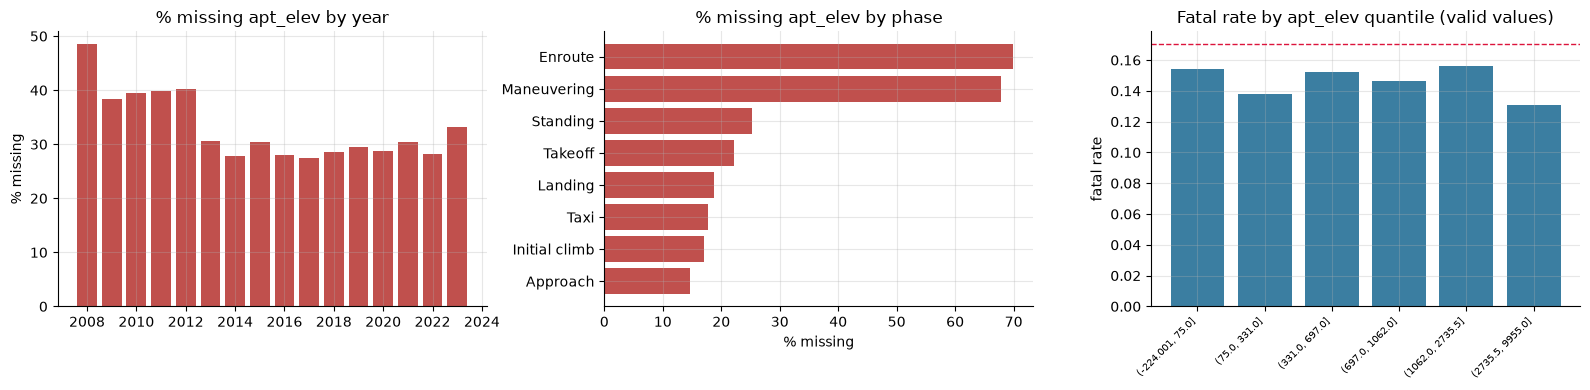

In [7]:
print("apt_elev summary:")
print(T["apt_elev"].describe().round(1).to_dict())
print("apt_elev < 0:", (T.apt_elev < 0).sum(), "· min:", T.apt_elev.min(),
      "· > 10,000 ft:", (T.apt_elev > 10000).sum(), "· max:", T.apt_elev.max())
print("\nFatal rate, apt_elev missing vs present:")
print(T.groupby(T["apt_elev"].isna())["fatal"].agg(rate="mean", n="size").round(3))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))

# Missingness by year
miss_yr = T.groupby("ev_year")["apt_elev"].apply(lambda s: s.isna().mean() * 100)
ax[0].bar(miss_yr.index, miss_yr.values, color="#c0504d")
ax[0].set_title("% missing apt_elev by year"); ax[0].set_ylabel("% missing")

# Missingness by top flight phases
top_ph = T["phase"].value_counts().head(8).index
miss_ph = T[T["phase"].isin(top_ph)].groupby("phase")["apt_elev"].apply(lambda s: s.isna().mean() * 100).sort_values()
ax[1].barh(miss_ph.index, miss_ph.values, color="#c0504d")
ax[1].set_title("% missing apt_elev by phase"); ax[1].set_xlabel("% missing")

# Fatal rate by valid apt_elev quantile
plot_num_vs_target(T[T["apt_elev"].between(-300, 10000)], "apt_elev", q=6, ax=ax[2],
                   title="Fatal rate by apt_elev quantile (valid values)")

plt.tight_layout(); plt.show()

**Interpretation.**
- **Why is `apt_elev` missing (33.6%)?** Primarily because **the accident did not happen at/near a registered airport**: missingness is **69.9% in `Enroute`** and **67.8% in `Maneuvering`**, versus only **15%–22%** in `Approach`, `Initial climb`, `Landing` and `Takeoff`. There is also a mild reporting-era effect (38%–49% missing in 2008–2012 vs ~28%–33% from 2013 onward).
- **Strong link to `fatal`:** rows with missing `apt_elev` have a **21.7%** fatal rate versus **14.6%** when present. Missingness is **not random (MNAR/MAR)** — it is a strong proxy for off-airport accidents.
- **Data quality:** 18 rows have slightly negative elevations down to `-224` ft, which are **real** (e.g., airports below sea level in California such as Death Valley / Salton Sea). However, `max = 33,333` ft (1 row) is impossible (the highest US airport is < 10,000 ft) and is a typo/sentinel value.

**→ NB1:** **definitely add an `apt_elev_missing` binary indicator** before imputing (it carries strong signal); replace `apt_elev > 10,000` ft with `NaN`; keep small negative values (down to ~`-300` ft) as valid.

## Part 2 · 6. Findings and decisions for NB1 (input for Person 1's final table)

In [8]:
findings_p2 = pd.DataFrame([
    ("ev_year", "Fatal rate stable (15.5%-20.0%); identical year distribution in learn and predict (random split)", "Weak standalone feature; safe to use year-related missingness flags (e.g. acft_year)"),
    ("ev_month", "Seasonal pattern: higher fatal rate in Oct-Jan (19%-22%) vs Jun-Sep (15%-16%)", "Keep; consider cyclical sin/cos encoding or winter indicator"),
    ("ev_dow", "Higher volume on weekends, very weak fatal-rate variation (15.7%-18.3%)", "Low priority; test in feature selection"),
    ("ev_hour", "Stored in UTC, NOT local time (DAYL peaks at 13-22h, Night at 03-10h); 19 NaNs have 68.4% fatal rate", "Keep with cyclic encoding; add ev_hour_missing flag; do not assume 0-23 is local time"),
    ("light_cond", "Strong predictor: DAYL 15.5%, NITE 29.6%, NDRK 55.7%, NaN 38.5%", "Keep NDRK separate from NITE/NBRT; keep NaN/NR as explicit category"),
    ("apt_dist", "77.3% zeros are a mix: on-airport (elev present, 8.5% fatal) vs disguised missing (elev NaN, 21.7% fatal); 70 outliers > 100 mi (up to 7,208)", "Convert dist==0 & elev NaN -> NaN (or build 3-way airport-status feature); cap/NaN values > 100 mi; consider log1p"),
    ("apt_elev", "33.6% missing, mainly off-airport (Enroute 70%, Maneuvering 68%); missing = 21.7% fatal vs 14.6% present; 1 typo at 33,333 ft (-224 ft is valid)", "Add apt_elev_missing indicator before imputation; set > 10,000 ft to NaN; keep negative values"),
], columns=["Column(s)", "Finding", "Decision / question for NB1"])

pd.set_option("display.max_colwidth", 140)
findings_p2

,Column(s),Finding,Decision / question for NB1
0,ev_year,Fatal rate stable (15.5%-20.0%); identical year distribution in learn and predict (random split),Weak standalone feature; safe to use year-related missingness flags (e.g. acft_year)
1,ev_month,Seasonal pattern: higher fatal rate in Oct-Jan (19%-22%) vs Jun-Sep (15%-16%),Keep; consider cyclical sin/cos encoding or winter indicator
2,ev_dow,"Higher volume on weekends, very weak fatal-rate variation (15.7%-18.3%)",Low priority; test in feature selection
3,ev_hour,"Stored in UTC, NOT local time (DAYL peaks at 13-22h, Night at 03-10h); 19 NaNs have 68.4% fatal rate",Keep with cyclic encoding; add ev_hour_missing flag; do not assume 0-23 is local time
4,light_cond,"Strong predictor: DAYL 15.5%, NITE 29.6%, NDRK 55.7%, NaN 38.5%",Keep NDRK separate from NITE/NBRT; keep NaN/NR as explicit category
5,apt_dist,"77.3% zeros are a mix: on-airport (elev present, 8.5% fatal) vs disguised missing (elev NaN, 21.7% fatal); 70 outliers > 100 mi (up to 7...",Convert dist==0 & elev NaN -> NaN (or build 3-way airport-status feature); cap/NaN values > 100 mi; consider log1p
6,apt_elev,"33.6% missing, mainly off-airport (Enroute 70%, Maneuvering 68%); missing = 21.7% fatal vs 14.6% present; 1 typo at 33,333 ft (-224 ft i...","Add apt_elev_missing indicator before imputation; set > 10,000 ft to NaN; keep negative values"


# ━━━━━━━━━━ PART 3 · Weather (Person 3) ━━━━━━━━━━

Columns covered (13): `wx_cond_basic`, `sky_cond_ceil`, `sky_cond_nonceil`, `sky_ceil_ht`, `vis_sm`, `wx_temp`, `wx_temp_c`, `wx_dew_pt`, `wind_dir_deg`, `wind_vel_kts`, `gust_ind`, `gust_kts`, `altimeter`.

All 13 columns come from the **nearest weather observation**, not from the exact accident site, so they are an approximation of the real conditions (a limitation we keep in mind throughout). In this part we look for: (i) zeros that are really missing values, (ii) internal contradictions between columns, (iii) impossible values, (iv) redundant columns and (v) the relation of each column with `fatal`.

NB0 does not change the data and does not train models. Any temporary cleaning needed to inspect a pattern is done on a throw-away copy `W` (or on boolean masks), and all real transformations are recorded as decisions for NB1 at the end of this part.

In [ ]:
GROUP_W = ["wx_cond_basic", "sky_cond_ceil", "sky_cond_nonceil", "sky_ceil_ht", "vis_sm",
           "wx_temp", "wx_temp_c", "wx_dew_pt", "wind_dir_deg", "wind_vel_kts",
           "gust_ind", "gust_kts", "altimeter"]
CAT_W = ["wx_cond_basic", "sky_cond_ceil", "sky_cond_nonceil", "gust_ind"]
NUM_W = [c for c in GROUP_W if c not in CAT_W]
W = learn.copy()   # throw-away copy: `learn` is never modified

## Part 3 · 1. Overview of the group

**What we do:** data types, missing values, cardinality and number of zeros of the 13 columns, in `learn` and in `predict`, plus the summary statistics of the numeric ones.

In [ ]:
ov_p3 = pd.DataFrame({
    "dtype": learn[GROUP_W].dtypes.astype(str),
    "missing_learn_%": (learn[GROUP_W].isna().mean() * 100).round(2),
    "missing_predict_%": (predict[GROUP_W].isna().mean() * 100).round(2),
    "n_unique": learn[GROUP_W].nunique(),
    "zeros_learn": learn[NUM_W].eq(0).sum(),
    "zeros_learn_%": (learn[NUM_W].eq(0).mean() * 100).round(1),
}).reindex(GROUP_W)
display(ov_p3)
print("Summary statistics of the numeric columns (learn):")
learn[NUM_W].describe().round(2).T

,dtype,missing_learn_%,missing_predict_%,n_unique,zeros_learn,zeros_learn_%
wx_cond_basic,str,0.11,0.16,3,NaN,NaN
sky_cond_ceil,str,11.79,12.39,5,NaN,NaN
sky_cond_nonceil,str,16.61,16.42,5,NaN,NaN
sky_ceil_ht,int64,0.00,0.00,3497,12834.0,75.6
vis_sm,float64,4.25,4.90,43,39.0,0.2
wx_temp,int64,0.00,0.00,161,855.0,5.0
wx_temp_c,float64,0.00,0.00,161,62.0,0.4
wx_dew_pt,int64,0.00,0.00,139,1639.0,9.7
wind_dir_deg,int64,0.00,0.00,361,4387.0,25.8
wind_vel_kts,float64,21.22,21.04,49,51.0,0.3


Summary statistics of the numeric columns (learn):


,count,mean,std,min,25%,50%,75%,max
sky_ceil_ht,16979.0,1575.38,4524.77,0.0,0.00,0.00,0.00,241340.00
vis_sm,16258.0,10.70,52.88,0.0,10.00,10.00,10.00,5000.00
wx_temp,16979.0,63.99,32.48,-55.0,54.00,69.00,80.00,3005.00
wx_temp_c,16979.0,17.77,18.05,-48.3,12.20,20.60,26.70,1651.70
wx_dew_pt,16979.0,43.66,50.58,-39.0,29.00,46.00,61.00,3027.00
wind_dir_deg,16979.0,142.21,118.82,0.0,0.00,146.00,244.00,360.00
wind_vel_kts,13376.0,7.90,4.93,0.0,5.00,7.00,10.00,185.00
gust_kts,16979.0,3.15,11.24,0.0,0.00,0.00,0.00,1077.00
altimeter,16979.0,36.92,168.26,0.0,29.87,30.01,30.12,3052.98


**Interpretation.**
- Only 5 columns have real NaNs: **`wind_vel_kts` 21.2%**, `sky_cond_nonceil` 16.6%, `sky_cond_ceil` 11.8%, `vis_sm` 4.3% and `wx_cond_basic` 0.1%. The other 8 columns show **0% missing, which is misleading**: they hide missing observations behind zeros (sections 3 and 4).
- Missing rates in `predict` are almost identical to `learn` (e.g. 21.0% vs 21.2% for `wind_vel_kts`), so there is no collection shift between the two files.
- The summary statistics already show **impossible values**: `wx_temp` max 3,005 °F, `altimeter` max 3,052.98 inHg, `vis_sm` max 5,000 miles, `gust_kts` max 1,077 kt, `wind_vel_kts` max 185 kt, `sky_ceil_ht` max 241,340 ft. Medians also hide the zeros: the median of `sky_ceil_ht` is 0 and the 25% quantile of `wind_dir_deg` is 0.

**→ NB1:** treat zeros and impossible values explicitly (sections 3 to 9) before any imputation; the same rules must be applied to `learn` and `predict`.

## Part 3 · 2. Categorical codes: spelling variants and "unknown" values

**What we do:** check whether the four categorical columns have spelling variants (case, spaces), compare the codes between `learn` and `predict`, and check how the two ways of saying "unknown" (the code `Unk`/`UNK` and an empty cell) behave against `fatal`.

In [ ]:
for c in CAT_W:
    raw = learn[c].dropna().unique()
    norm = pd.Series(raw).str.strip().str.upper().nunique()
    print(f"{c}: {len(raw)} raw codes, {norm} after strip + upper ->",
          "no spelling variants" if len(raw) == norm else "SPELLING VARIANTS")
print("OBSC (in the data dictionary) present in sky_cond_ceil:", (learn["sky_cond_ceil"] == "OBSC").sum(), "rows")

cmp_codes = pd.concat({c: pd.concat({"learn": learn[c].value_counts(dropna=False),
                                      "predict": predict[c].value_counts(dropna=False)}, axis=1)
                       for c in CAT_W}).fillna(0).astype(int)
display(cmp_codes)

unk = []
for c, code_ in [("wx_cond_basic", "Unk"), ("sky_cond_ceil", "UNK"), ("sky_cond_nonceil", "UNK")]:
    for lab, m in [(code_, W[c] == code_), ("NaN (empty)", W[c].isna())]:
        unk.append((c, lab, int(m.sum()), round(W.loc[m, "fatal"].mean(), 3)))
print("Two ways of 'unknown' vs fatal rate:")
pd.DataFrame(unk, columns=["column", "value", "n", "fatal_rate"])

wx_cond_basic: 3 raw codes, 3 after strip + upper -> no spelling variants
sky_cond_ceil: 5 raw codes, 5 after strip + upper -> no spelling variants
sky_cond_nonceil: 5 raw codes, 5 after strip + upper -> no spelling variants
gust_ind: 2 raw codes, 2 after strip + upper -> no spelling variants
OBSC (in the data dictionary) present in sky_cond_ceil: 0 rows


learn  predict
wx_cond_basic    VMC   16121     3999
                 IMC     771      214
                 Unk      68       25
                 nan      19        7
sky_cond_ceil    NONE  10662     2660
                 BKN    2574      604
                 nan    2002      526
                 OVC    1597      417
                 UNK      95       32
                 VV       49        6
sky_cond_nonceil CLER   9371     2362
                 nan    2821      697
                 FEW    2284      558
                 SCAT   2206      544
                 UNK     157       52
                 OVCT    140       32
gust_ind         T     10934     2704
                 F      6045     1541

Two ways of 'unknown' vs fatal rate:


,column,value,n,fatal_rate
0,wx_cond_basic,Unk,68,0.412
1,wx_cond_basic,NaN (empty),19,0.421
2,sky_cond_ceil,UNK,95,0.147
3,sky_cond_ceil,NaN (empty),2002,0.111
4,sky_cond_nonceil,UNK,157,0.306
5,sky_cond_nonceil,NaN (empty),2821,0.224


**Interpretation.**
- There are **no spelling variants** in these columns (no `vmc`/`VMC` type duplicates), and the codes in `predict` are the same as in `learn`. `OBSC` is documented in the data dictionary but **never appears** in `sky_cond_ceil`.
- "Unknown" is written in **two ways**: the code `Unk`/`UNK` and an empty cell. Their fatal rates differ in the ceiling and cloud columns (`sky_cond_ceil`: `UNK` 14.7% vs NaN 11.1%; `sky_cond_nonceil`: `UNK` 30.6% vs NaN 22.4%), so they are not the same thing. In `wx_cond_basic` they behave the same (41.2% and 42.1%), but both groups are small (68 and 19 rows).
- `gust_ind` is complete and has only `T` and `F` (its meaning is analysed in section 6).

**→ NB1:** keep NaN and `Unk`/`UNK` as explicit categories (or merge them into one `UNKNOWN` only after checking that this does not lose signal); do not impute the categorical columns.

## Part 3 · 3. Zeros that probably are missing values

**What we do:** for `altimeter`, `wx_temp`, `wx_dew_pt`, `wind_dir_deg` and `sky_ceil_ht`, count the zeros (in `learn` and `predict`), compare the fatal rate of zero vs non-zero rows, and look at the distributions without the zeros. Zeros are not removed: we only use masks and the copy `W`.

,column,zeros_learn,zeros_%,zeros_predict,fatal_if_zero,fatal_if_not_zero
0,altimeter,1510,8.9,370,0.056,0.181
1,wx_temp,855,5.0,213,0.067,0.176
2,wx_dew_pt,1639,9.7,421,0.057,0.182
3,wind_dir_deg,4387,25.8,1106,0.148,0.178
4,sky_ceil_ht,12834,75.6,3227,0.145,0.247


wx_temp values around zero: {-2: 1, -1: 1, 0: 855, 1: 4, 2: 1, 3: 4}
wx_temp == 0 in Jun-Aug: 336 of 855 · median valid temperature in Jun-Aug: 80.0 F
altimeter (non-zero) outside 28-31 inHg: 77 of 15469


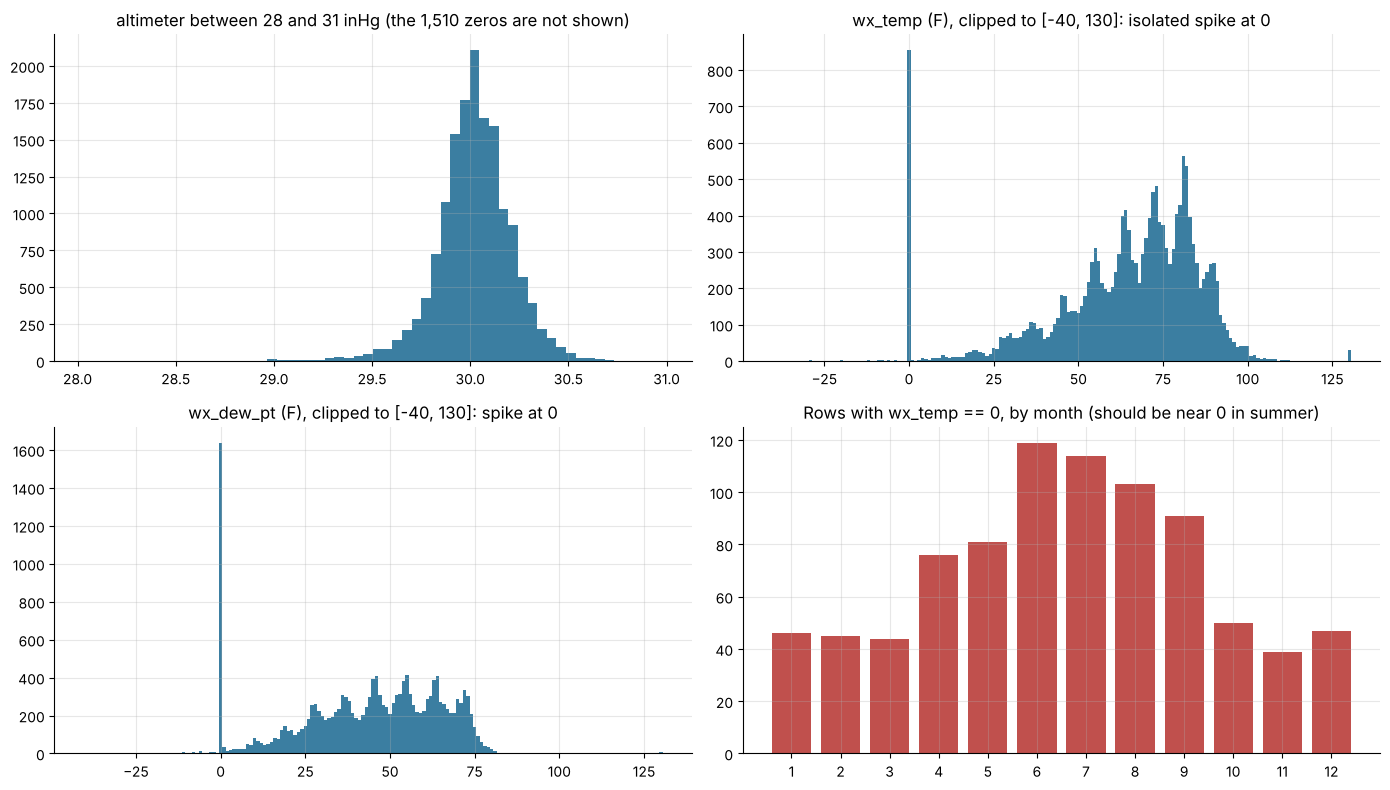

In [ ]:
zero_rows = []
for c in ["altimeter", "wx_temp", "wx_dew_pt", "wind_dir_deg", "sky_ceil_ht"]:
    z = W[c] == 0
    zero_rows.append((c, int(z.sum()), round(z.mean() * 100, 1), int((predict[c] == 0).sum()),
                      round(W.loc[z, "fatal"].mean(), 3), round(W.loc[~z, "fatal"].mean(), 3)))
zero_df = pd.DataFrame(zero_rows, columns=["column", "zeros_learn", "zeros_%", "zeros_predict",
                                           "fatal_if_zero", "fatal_if_not_zero"])
display(zero_df)

temp_ok = W["wx_temp"].between(-40, 130) & (W["wx_temp"] != 0)     # plausible temperature (F)
print("wx_temp values around zero:", {k: int((W.wx_temp == k).sum()) for k in [-2, -1, 0, 1, 2, 3]})
summer = W["ev_month"].isin([6, 7, 8])
print("wx_temp == 0 in Jun-Aug:", int(((W.wx_temp == 0) & summer).sum()),
      "of", int((W.wx_temp == 0).sum()),
      "· median valid temperature in Jun-Aug:", W.loc[temp_ok & summer, "wx_temp"].median(), "F")
print("altimeter (non-zero) outside 28-31 inHg:", int(((W.altimeter > 0) & ~W.altimeter.between(28, 31)).sum()),
      "of", int((W.altimeter > 0).sum()))

fig, ax = plt.subplots(2, 2, figsize=(14, 8))
ax[0, 0].hist(W.loc[W.altimeter.between(28, 31), "altimeter"], bins=60, color="#3b7ea1")
ax[0, 0].set_title("altimeter between 28 and 31 inHg (the 1,510 zeros are not shown)")
ax[0, 1].hist(W["wx_temp"].clip(-40, 130), bins=np.arange(-40.5, 131.5, 1), color="#3b7ea1")
ax[0, 1].set_title("wx_temp (F), clipped to [-40, 130]: isolated spike at 0")
ax[1, 0].hist(W["wx_dew_pt"].clip(-40, 130), bins=np.arange(-40.5, 131.5, 1), color="#3b7ea1")
ax[1, 0].set_title("wx_dew_pt (F), clipped to [-40, 130]: spike at 0")
m0 = W.loc[W.wx_temp == 0, "ev_month"].value_counts().sort_index()
ax[1, 1].bar(m0.index, m0.values, color="#c0504d")
ax[1, 1].set_xticks(range(1, 13)); ax[1, 1].set_title("Rows with wx_temp == 0, by month (should be near 0 in summer)")
plt.tight_layout(); plt.show()

**Interpretation.**
- **`altimeter == 0` (1,510 rows, 8.9%)** is physically impossible. The non-zero values concentrate around 29.9-30.1 inHg. **`wx_temp == 0` (855 rows, 5.0%)** is an isolated spike (the neighbours -2, -1, 1, 2 have 1 to 4 rows each, the value 0 has 855) and **336 of those rows (39%) happen in June-August**, when the median valid temperature is 80 °F, so they are not real freezing days. In `wx_temp_c` they show up as -17.8 °C. **`wx_dew_pt == 0` (1,639 rows, 9.7%)** has the same spike.
- In all three, the zero rows have a **much lower fatal rate** (5.6%, 6.7% and 5.7%) than the non-zero rows (18.1%, 17.6% and 18.2%): the missingness carries signal.
- **`wind_dir_deg == 0` (4,387 rows, 25.8%)** is only partly missing, see section 5. **`sky_ceil_ht == 0` (75.6%)** mostly means "no ceiling", see section 7.
- `predict` has the same proportions (370 zeros in `altimeter`, 213 in `wx_temp`, 1,106 in `wind_dir_deg`, 3,227 in `sky_ceil_ht`), so the same problem must be fixed there.

**→ NB1:** convert `altimeter == 0`, `wx_temp == 0` and `wx_dew_pt == 0` to NaN **and** keep a missing flag (they carry signal); impute afterwards, with statistics learned only on the training folds.

## Part 3 · 4. Do the missing observations happen on the same rows?

**What we do:** check whether the zeros in `altimeter`, `wx_temp` and `wx_dew_pt` come from the same rows (a missing weather observation), how this relates to `fatal`, and whether it changes over time or with the airport information.

{'altimeter0': 1510, 'temp0': 855, 'dew0': 1639}
temp0       False  True    All
altimeter0                    
False       15385    84  15469
True          739   771   1510
All         16124   855  16979
all three zero: 771 · altimeter0 only (temp != 0): 739 · temp0 only (altimeter != 0): 84
dew == 0 with temp != 0: 807 · of which temp between 40 and 130 F: 674

any of the three is zero: 1874 rows · fatal 0.064 vs 0.183 for the rest (base 0.170)

% rows with altimeter==0 or wx_temp==0, by apt_elev missing: {False: 5.7, True: 16.6}


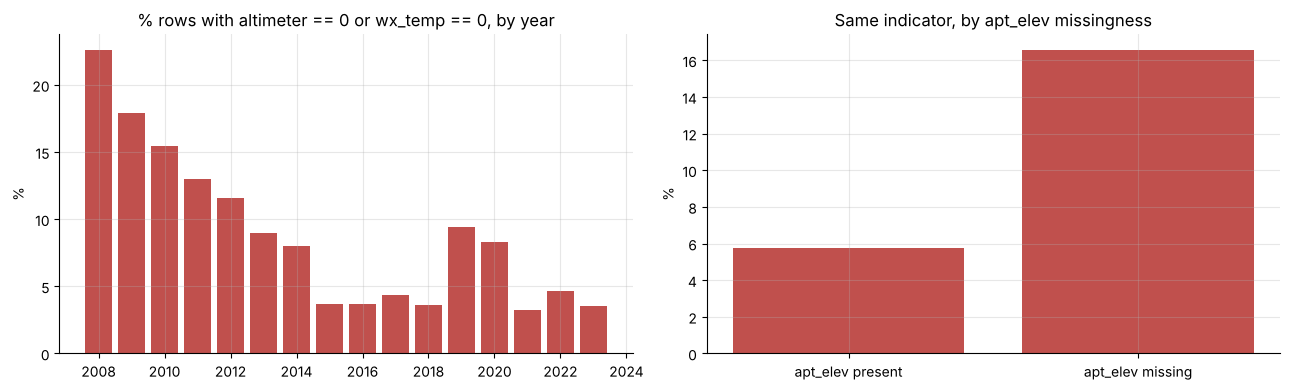

In [ ]:
Z = pd.DataFrame({"altimeter0": W.altimeter == 0, "temp0": W.wx_temp == 0, "dew0": W.wx_dew_pt == 0})
print(Z.sum().to_dict())
print(pd.crosstab(Z.altimeter0, Z.temp0, margins=True))
print("all three zero:", int(Z.all(axis=1).sum()),
      "· altimeter0 only (temp != 0):", int((Z.altimeter0 & ~Z.temp0).sum()),
      "· temp0 only (altimeter != 0):", int((Z.temp0 & ~Z.altimeter0).sum()))
print("dew == 0 with temp != 0:", int((Z.dew0 & ~Z.temp0).sum()),
      "· of which temp between 40 and 130 F:", int((Z.dew0 & ~Z.temp0 & W.wx_temp.between(40, 130)).sum()))

wx_obs_missing = Z.any(axis=1)
print(f"\nany of the three is zero: {wx_obs_missing.sum()} rows · fatal {W.loc[wx_obs_missing, 'fatal'].mean():.3f}"
      f" vs {W.loc[~wx_obs_missing, 'fatal'].mean():.3f} for the rest (base {BASE:.3f})")

m2 = Z.altimeter0 | Z.temp0
by_year = m2.groupby(W.ev_year).mean() * 100
by_elev = m2.groupby(W.apt_elev.isna()).mean() * 100
print("\n% rows with altimeter==0 or wx_temp==0, by apt_elev missing:", by_elev.round(1).to_dict())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(by_year.index, by_year.values, color="#c0504d")
ax[0].set_title("% rows with altimeter == 0 or wx_temp == 0, by year"); ax[0].set_ylabel("%")
ax[1].bar(["apt_elev present", "apt_elev missing"], by_elev.values, color="#c0504d")
ax[1].set_title("Same indicator, by apt_elev missingness"); ax[1].set_ylabel("%")
plt.tight_layout(); plt.show()

**Interpretation.**
- **771 rows have the three zeros at the same time** (`altimeter`, `wx_temp` and `wx_dew_pt`): there is no weather observation at all for them. Besides these, 739 rows have only `altimeter == 0` and 84 only `wx_temp == 0`.
- `wx_dew_pt == 0` also appears on its own in 807 rows with a valid temperature, and in 674 of them the temperature is between 40 and 130 °F, where a 0 °F dew point is not credible. We therefore treat it as missing too.
- **1,874 rows have at least one of the three zeros and a fatal rate of about 6.4%** (against the 17.0% base). A single flag `wx_obs_missing` summarises this.
- It is a **time effect**: the share of rows with `altimeter == 0` or `wx_temp == 0` is **23% in 2008 and drops to about 4% from 2015 on**. It is also more frequent when the airport elevation is missing (**16.6% vs 5.7%**), which suggests accidents far from airports, where no station is near. The lower fatal rate of these rows may be confounded with aircraft type or operation, so we do not interpret it causally.

**→ NB1:** build `wx_obs_missing` (and/or one flag per column); consider an interaction with `apt_elev_missing` (Part 2); check the `ev_year` effect before choosing the imputation.

## Part 3 · 5. Wind: direction 0, speed NaN and extreme speeds

**What we do:** split the 4,387 rows with `wind_dir_deg == 0` according to `wind_vel_kts` (calm wind, not observed, or speed > 0), and look at the extreme values of the wind speed.

,n,fatal_rate
dir != 0,12592,0.178
dir 0 & calm (speed = 0),51,0.235
dir 0 & speed > 0 (suspicious),793,0.131
dir 0 & speed NaN (not observed),3543,0.150


wind_vel_kts NaN: 3603 · of which dir == 0: 3543
wind_vel_kts == 0: 51 · of which dir == 0: 51
wind_dir_deg == 360 (north): 35
% wind_vel_kts NaN by year (min / max): {'min': 16.0, 'max': 25.0}
wind_vel_kts > 50: [65.0, 75.0, 76.0, 79.0, 98.0, 100.0, 115.0, 185.0]


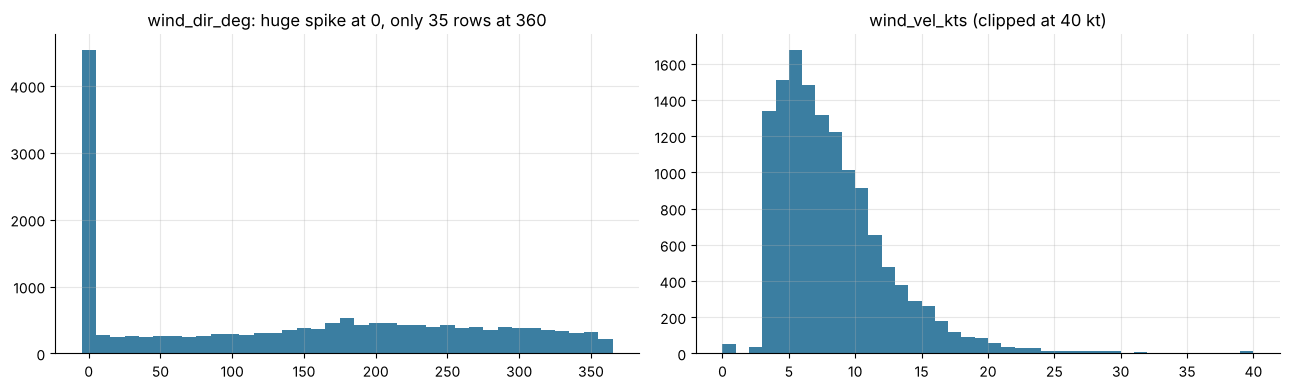

In [ ]:
d0 = W.wind_dir_deg == 0
grp = pd.Series(np.select([d0 & (W.wind_vel_kts == 0), d0 & W.wind_vel_kts.isna(), d0 & (W.wind_vel_kts > 0)],
                          ["dir 0 & calm (speed = 0)", "dir 0 & speed NaN (not observed)", "dir 0 & speed > 0 (suspicious)"],
                          default="dir != 0"), index=W.index)
display(W.groupby(grp)["fatal"].agg(n="size", fatal_rate="mean").round(3))

print("wind_vel_kts NaN:", int(W.wind_vel_kts.isna().sum()), "· of which dir == 0:", int((W.wind_vel_kts.isna() & d0).sum()))
print("wind_vel_kts == 0:", int((W.wind_vel_kts == 0).sum()), "· of which dir == 0:", int(((W.wind_vel_kts == 0) & d0).sum()))
print("wind_dir_deg == 360 (north):", int((W.wind_dir_deg == 360).sum()))
print("% wind_vel_kts NaN by year (min / max):", (W.wind_vel_kts.isna().groupby(W.ev_year).mean() * 100).round(0).agg(["min", "max"]).to_dict())
print("wind_vel_kts > 50:", sorted(W.wind_vel_kts[W.wind_vel_kts > 50].tolist()))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(W.wind_dir_deg, bins=np.arange(-5, 370, 10), color="#3b7ea1")
ax[0].set_title("wind_dir_deg: huge spike at 0, only 35 rows at 360")
ax[1].hist(W.wind_vel_kts.clip(upper=40), bins=40, color="#3b7ea1")
ax[1].set_title("wind_vel_kts (clipped at 40 kt)")
plt.tight_layout(); plt.show()

**Interpretation.**
- The 4,387 rows with `wind_dir_deg == 0` split into three groups: **51 calm-wind rows** (`wind_vel_kts == 0`, a real zero: every calm row has direction 0), **3,543 rows with `wind_vel_kts` NaN** (wind not observed; the direction 0 is a code for "no data") and **793 rows with speed > 0** (suspicious: a direction of 0 with real wind, although some of them may be genuine north winds; only 35 rows use 360).
- `wind_vel_kts` is NaN in 21.2% of the rows, and the NaN share stays between roughly 16% and 25% every year, so, unlike the temperature/altimeter zeros, it is **not a time effect**.
- The speed has extreme values (8 rows above 50 kt, up to 185 kt), which need a cap.

**→ NB1:** `wind_dir_deg == 0` with `wind_vel_kts` NaN → NaN (keep 0 only when speed is 0); keep a `wind_missing` flag; treat the 793 suspicious rows as NaN or test both options; cap or NaN-out `wind_vel_kts` > 100.

## Part 3 · 6. Gusts: `gust_ind` against `gust_kts`

**What we do:** cross `gust_ind` (T/F) with `gust_kts > 0`, look at the F rows with no gust speed, and check the physical rule "a gust is faster than the mean wind".

gust_kts  gust_kts == 0  gust_kts > 0    All
gust_ind                                    
F                  3429          2616   6045
T                 10929             5  10934
All               14358          2621  16979

gust_ind == T: 64.4% of the rows · gust_kts == 0: 84.6% of the rows
gust_ind F & gust_kts == 0: 3429 · of which wind_vel_kts NaN: 2747
gust_kts > 0: 2621 · median 19.0 · max 1077
gust_kts < wind_vel_kts: 24 · <=: 36

Fatal rate by gust_ind:
           rate      n
gust_ind              
F         0.166   6045
T         0.172  10934


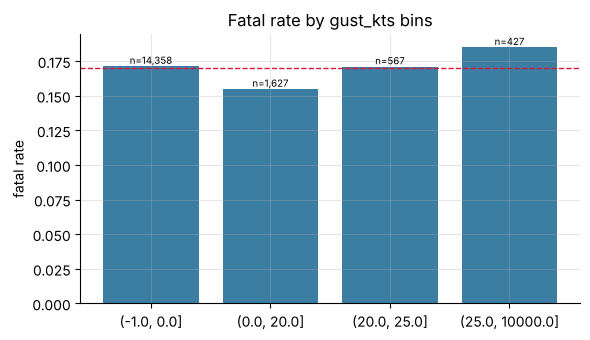

In [ ]:
print(pd.crosstab(W.gust_ind, W.gust_kts > 0, margins=True).rename(columns={False: "gust_kts == 0", True: "gust_kts > 0"}))
print(f"\ngust_ind == T: {(W.gust_ind == 'T').mean():.1%} of the rows · gust_kts == 0: {(W.gust_kts == 0).mean():.1%} of the rows")
print("gust_ind F & gust_kts == 0:", int(((W.gust_ind == 'F') & (W.gust_kts == 0)).sum()),
      "· of which wind_vel_kts NaN:", int(((W.gust_ind == 'F') & (W.gust_kts == 0) & W.wind_vel_kts.isna()).sum()))
g = W[W.gust_kts > 0]
print("gust_kts > 0:", len(g), "· median", g.gust_kts.median(), "· max", g.gust_kts.max())
print("gust_kts < wind_vel_kts:", int((g.gust_kts < g.wind_vel_kts).sum()), "· <=:", int((g.gust_kts <= g.wind_vel_kts).sum()))
print("\nFatal rate by gust_ind:"); print(W.groupby("gust_ind")["fatal"].agg(rate="mean", n="size").round(3))

edges = [-1, 0, 20, 25, 1e4]
gb = W.groupby(pd.cut(W.gust_kts, edges), observed=True)["fatal"].agg(rate="mean", n="size")
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(range(len(gb)), gb["rate"], color="#3b7ea1"); ax.axhline(BASE, color="crimson", ls="--", lw=1)
ax.set_xticks(range(len(gb))); ax.set_xticklabels([str(i) for i in gb.index])
for i, (r, n) in enumerate(zip(gb["rate"], gb["n"])): ax.text(i, r, f"n={n:,}", ha="center", va="bottom", fontsize=7)
ax.set_title("Fatal rate by gust_kts bins"); ax.set_ylabel("fatal rate"); plt.tight_layout(); plt.show()

**Interpretation.**
- `gust_ind` is **practically inverted**: of 10,934 rows with `T`, only 5 have `gust_kts > 0`, and 2,616 of the 2,621 rows with a gust speed have `F`. This explains the oddity of `T` in 64% of the rows while `gust_kts` is 0 in 85%: the indicator does **not** mean "there was a gust".
- Of the 3,429 `F` rows with no gust speed, 2,747 also have `wind_vel_kts` NaN, i.e. the wind was not observed. So `F` looks like "gust present **or** wind not observed".
- `gust_kts == 0` is a legitimate "no gust" in most rows (not missing). Only 24 rows have a gust slower than the mean wind (36 if equality is included), and one row has an impossible 1,077 kt.
- Weak relation with `fatal`: `gust_ind` T 17.2% vs F 16.6%; by `gust_kts` bins 15.5% to 18.5%.

**→ NB1:** do not use `gust_ind` as is; build `gust_present = gust_kts > 0` (and drop or test `gust_ind`); cap `gust_kts` (NaN above ~200 kt); low priority in feature selection.

## Part 3 · 7. Cloud ceiling: `sky_cond_ceil` against `sky_ceil_ht`

**What we do:** cross the ceiling condition with the ceiling height, to understand what the 75.6% zeros in `sky_ceil_ht` mean, and check the contradictions (a ceiling with height 0, a "no ceiling" with a height).

sky_ceil_ht,height > 0,height == 0,All
sky_cond_ceil,,,
BKN,2508,66,2574
NONE,21,10641,10662
NaN,15,1987,2002
OVC,1567,30,1597
UNK,3,92,95
VV,31,18,49
All,4145,12834,16979


Height statistics by ceiling condition:


,count,mean,std,min,25%,50%,75%,max
sky_cond_ceil,,,,,,,,
BKN,2574.0,7567.0,8257.0,0.0,2890.0,5191.0,9562.0,241340.0
NONE,10662.0,20.0,579.0,0.0,0.0,0.0,0.0,27138.0
NaN,2002.0,36.0,696.0,0.0,0.0,0.0,0.0,23162.0
OVC,1597.0,4351.0,4453.0,0.0,1033.0,3033.0,6353.0,27677.0
UNK,95.0,322.0,2260.0,0.0,0.0,0.0,0.0,20081.0
VV,49.0,215.0,434.0,0.0,0.0,114.0,204.0,2899.0


NONE with height > 0: 21 · BKN/OVC with height == 0: 96
sky_ceil_ht > 20,000: 289 · max: 241340
Fatal rate, height == 0 vs > 0: {False: 0.247, True: 0.145}


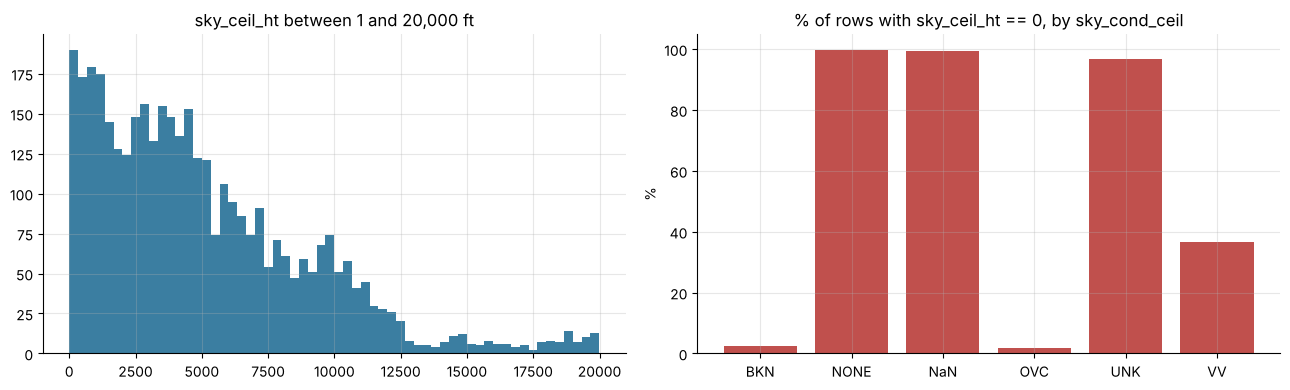

In [ ]:
cc = W.sky_cond_ceil.fillna("NaN")
display(pd.crosstab(cc, W.sky_ceil_ht == 0, margins=True).rename(columns={False: "height > 0", True: "height == 0"}))
print("Height statistics by ceiling condition:")
display(W.groupby(cc)["sky_ceil_ht"].describe().round(0))

print("NONE with height > 0:", int(((cc == "NONE") & (W.sky_ceil_ht > 0)).sum()),
      "· BKN/OVC with height == 0:", int((cc.isin(["BKN", "OVC"]) & (W.sky_ceil_ht == 0)).sum()))
print("sky_ceil_ht > 20,000:", int((W.sky_ceil_ht > 20000).sum()), "· max:", int(W.sky_ceil_ht.max()))
print("Fatal rate, height == 0 vs > 0:", W.groupby(W.sky_ceil_ht == 0)["fatal"].mean().round(3).to_dict())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
h = W.loc[W.sky_ceil_ht.between(1, 20000), "sky_ceil_ht"]
ax[0].hist(h, bins=60, color="#3b7ea1"); ax[0].set_title("sky_ceil_ht between 1 and 20,000 ft")
ct = pd.crosstab(cc, W.sky_ceil_ht == 0, normalize="index") * 100
ax[1].bar(ct.index, ct[True], color="#c0504d"); ax[1].set_title("% of rows with sky_ceil_ht == 0, by sky_cond_ceil"); ax[1].set_ylabel("%")
plt.tight_layout(); plt.show()

**Interpretation.**
- The zero in `sky_ceil_ht` is mostly **"there is no ceiling" or "no data"**, not "a ceiling at 0 ft": it appears in 10,641 of the 10,662 `NONE` rows, in 1,987 of the 2,002 rows where `sky_cond_ceil` is NaN and in 92 of the 95 `UNK` rows.
- The real contradictions are few: **96 rows** with `BKN`/`OVC` and height 0 (66 + 30), and **21 rows** with `NONE` and a height above 0. `VV` (vertical visibility) has 18 of 49 rows with height 0, which is plausible for an obscured sky.
- Outliers: 289 rows above 20,000 ft and one at 241,340 ft.
- The fatal rate is clearly higher when there is a real ceiling (24.7%) than when the height is 0 (14.5%).

**→ NB1:** split the column in two: `has_ceiling` (from `sky_cond_ceil` and height > 0) and the real height (NaN when there is no ceiling); treat the 96 + 21 contradictory rows as NaN; cap the height; keep the NaN of `sky_cond_ceil` as its own category.

## Part 3 · 8. Temperature and dew point: redundancy and physical rule

**What we do:** check whether `wx_temp_c` is just a conversion of `wx_temp` (the project statement says one column changes unit from row to row, so we test whether it is this one), and check the rule "dew point <= temperature" on the rows where both values are plausible.

max |wx_temp_c - (wx_temp - 32) * 5/9|: 0.044 · rows with difference > 0.1: 0
rows where wx_temp_c == wx_temp: 0 · correlation on plausible rows: 1.0

dew point > temperature, all rows: 268
plausible rows: 15298 · dew > temp: 245 · dew == temp (saturation): 182 · dew > temp + 2 F: 62 · dew > temp + 5 F: 39
temp == 0 rows with dew > temp: 9 of 855


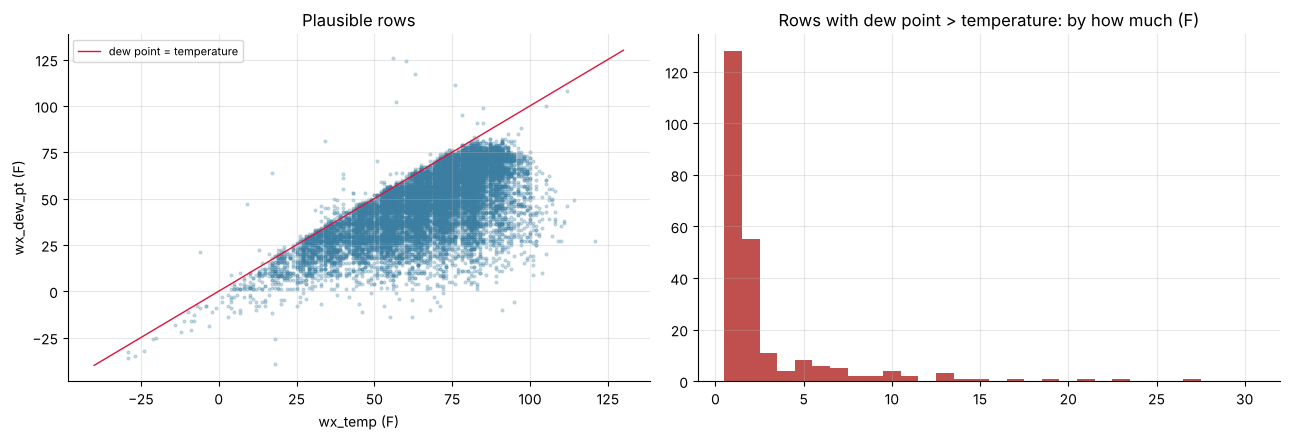

In [ ]:
conv_diff = (W.wx_temp_c - (W.wx_temp - 32) * 5 / 9).abs()
print("max |wx_temp_c - (wx_temp - 32) * 5/9|:", round(conv_diff.max(), 3), "· rows with difference > 0.1:", int((conv_diff > 0.1).sum()))
print("rows where wx_temp_c == wx_temp:", int((W.wx_temp_c == W.wx_temp).sum()),
      "· correlation on plausible rows:", round(np.corrcoef(W.loc[temp_ok, "wx_temp"], W.loc[temp_ok, "wx_temp_c"])[0, 1], 4))

clean = temp_ok & (W.wx_dew_pt != 0) & (W.wx_dew_pt <= 130)
diff = W.wx_dew_pt - W.wx_temp
viol = clean & (diff > 0)
print("\ndew point > temperature, all rows:", int((W.wx_dew_pt > W.wx_temp).sum()))
print("plausible rows:", int(clean.sum()), "· dew > temp:", int(viol.sum()),
      "· dew == temp (saturation):", int((clean & (diff == 0)).sum()),
      "· dew > temp + 2 F:", int((clean & (diff > 2)).sum()), "· dew > temp + 5 F:", int((clean & (diff > 5)).sum()))
print("temp == 0 rows with dew > temp:", int(((W.wx_temp == 0) & (W.wx_dew_pt > 0)).sum()), "of", int((W.wx_temp == 0).sum()))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(W.loc[clean, "wx_temp"], W.loc[clean, "wx_dew_pt"], s=4, alpha=.25, color="#3b7ea1")
ax[0].plot([-40, 130], [-40, 130], color="crimson", lw=1, label="dew point = temperature")
ax[0].set_xlabel("wx_temp (F)"); ax[0].set_ylabel("wx_dew_pt (F)"); ax[0].set_title("Plausible rows"); ax[0].legend(fontsize=8)
ax[1].hist(diff[viol], bins=np.arange(0.5, 31.5, 1), color="#c0504d")
ax[1].set_title("Rows with dew point > temperature: by how much (F)")
plt.tight_layout(); plt.show()

**Interpretation.**
- **`wx_temp_c` is exactly `(wx_temp - 32) * 5/9`** (maximum difference 0.044, no row with a mismatch, correlation 1.00). It is a **redundant column, not the column that changes unit**: the mixed-unit column of the project is `eng_power` (Part 4). It also inherits every error of `wx_temp` (the zeros become -17.8 °C, the 3,005 becomes 1,651.7 °C).
- Dew point above temperature happens in 268 rows. On the 15,298 plausible rows it happens in **245 (1.6%)**, but **182 of them are equality** (saturated air, legitimate) and most of the others are 1-2 °F (rounding between sensors): only **62 exceed 2 °F and 39 exceed 5 °F**. So this rule is a minor problem, and the zeros of `wx_temp` and `wx_dew_pt` are not its cause (only 9 of the 855 `wx_temp == 0` rows have a larger dew point).

**→ NB1:** drop `wx_temp_c` (redundant); keep `wx_temp` (after fixing the zeros) and create `temp_dew_spread = wx_temp - wx_dew_pt` (a proxy for fog/saturation), computed only where both are valid; the 39 rows with dew point > temperature + 5 °F can be set to NaN.

## Part 3 · 9. Impossible values and outliers

**What we do:** list the rows outside the physically possible range, in `learn` and in `predict`, and look at the "altimeter in hundredths" case (values like 2997 instead of 29.97).

In [ ]:
rules = [
    ("altimeter", "> 100 inHg", lambda d: d.altimeter > 100),
    ("altimeter", "2,800 to 3,200 (looks like value x 100)", lambda d: d.altimeter.between(2800, 3200)),
    ("altimeter", "between 0 and 28 (exclusive)", lambda d: (d.altimeter > 0) & (d.altimeter < 28)),
    ("altimeter", "between 31 and 100", lambda d: (d.altimeter > 31) & (d.altimeter <= 100)),
    ("wx_temp", "> 130 F", lambda d: d.wx_temp > 130),
    ("wx_temp", "< -40 F", lambda d: d.wx_temp < -40),
    ("wx_dew_pt", "> 130 F", lambda d: d.wx_dew_pt > 130),
    ("vis_sm", "> 10 sm", lambda d: d.vis_sm > 10),
    ("vis_sm", "> 30 sm", lambda d: d.vis_sm > 30),
    ("vis_sm", "> 100 sm", lambda d: d.vis_sm > 100),
    ("wind_vel_kts", "> 50 kt", lambda d: d.wind_vel_kts > 50),
    ("gust_kts", "> 60 kt", lambda d: d.gust_kts > 60),
    ("sky_ceil_ht", "> 20,000 ft", lambda d: d.sky_ceil_ht > 20000),
    ("sky_ceil_ht", "> 50,000 ft", lambda d: d.sky_ceil_ht > 50000),
]
out_tbl = pd.DataFrame([(c, r, int(f(learn).sum()), int(f(predict).sum())) for c, r, f in rules],
                       columns=["column", "rule", "rows_learn", "rows_predict"])
display(out_tbl)
print("altimeter values > 100:", sorted(learn.loc[learn.altimeter > 100, "altimeter"].round(2).tolist())[:4], "...",
      sorted(learn.loc[learn.altimeter > 100, "altimeter"].round(2).tolist())[-3:])
print("wx_dew_pt values > 130:", sorted(learn.loc[learn.wx_dew_pt > 130, "wx_dew_pt"].tolist()))
print("wx_temp values > 130 (smallest 5 / largest 3):", sorted(learn.loc[learn.wx_temp > 130, "wx_temp"].tolist())[:5],
      sorted(learn.loc[learn.wx_temp > 130, "wx_temp"].tolist())[-3:])

,column,rule,rows_learn,rows_predict
0,altimeter,> 100 inHg,56,12
1,altimeter,"2,800 to 3,200 (looks like value x 100)",54,12
2,altimeter,between 0 and 28 (exclusive),18,3
3,altimeter,between 31 and 100,3,1
4,wx_temp,> 130 F,31,5
5,wx_temp,< -40 F,1,0
6,wx_dew_pt,> 130 F,10,2
7,vis_sm,> 10 sm,445,110
8,vis_sm,> 30 sm,138,30
9,vis_sm,> 100 sm,2,0


altimeter values > 100: [230.16, 1974.02, 2937.02, 2965.0] ... [3025.0, 3035.05, 3052.98]
wx_dew_pt values > 130: [132, 152, 153, 159, 161, 191, 2969, 3000, 3001, 3027]
wx_temp values > 130 (smallest 5 / largest 3): [133, 134, 137, 139, 139] [187, 203, 3005]


**Interpretation.**
- **`altimeter`:** of the 56 values above 100, **54 are between 2,800 and 3,200**, i.e. the pressure written in hundredths (2997 = 29.97 inHg); the other two (230.16 and 1,974.02) are not recoverable. There are also 18 values between 16 and 28 and 3 between 31 and 100, which are implausible.
- **`wx_temp` / `wx_dew_pt`:** 31 temperatures above 130 °F (from 133 to 3,005) and 1 below -40 °F (-55); 10 dew points above 130 °F (132 to 3,027, some of them 2,969-3,027, also looking like a x100 format).
- **`vis_sm`:** 87% of the rows with known visibility (83% of all rows) are exactly 10 (the usual top of the scale), but 445 rows are above 10 sm and two are above 100 (up to 5,000). **`gust_kts`** has one row with 1,077 kt. **`wind_vel_kts`** has 8 rows above 50 kt (up to 185). **`sky_ceil_ht`** has 289 rows above 20,000 ft.
- `predict` has the same kinds of values (e.g. 5 temperatures above 130 °F, 12 altimeters above 100, 30 visibilities above 30 sm), so every rule must also be applied to `predict`.

**→ NB1:** NaN for `altimeter` outside 28-31 inHg after dividing by 100 the 54 values in 2,800-3,200 (confirm the choice); NaN for `wx_temp` outside [-40, 130] and `wx_dew_pt` > 130; cap `wind_vel_kts`, `gust_kts` and `sky_ceil_ht`; decide how to treat `vis_sm` > 10 (question: is it a special code?).

## Part 3 · 10. Visibility and instrument/visual conditions: do they agree?

**What we do:** compare `wx_cond_basic` (VMC/IMC) with the visibility and the cloud ceiling of the nearest station, looking for contradictions.

vis_sm value counts: {10.0: 14147, 7.0: 339, 9.0: 242, 8.0: 200, 5.0: 186, 6.0: 171}
vis_sm == 10: 83.3% · vis_sm NaN: 721 · fatal rate of vis NaN rows: 0.086


sky_cond_ceil,BKN,NONE,NaN,OVC,UNK,VV
wx_cond_basic,,,,,,
IMC,239,28,48,409,12,35
NaN,3,2,12,2,0,0
Unk,20,7,20,14,7,0
VMC,2312,10625,1922,1172,76,14


IMC rows: 771 · with known visibility: 715
IMC & vis_sm >= 5: 363 · IMC & vis_sm == 10: 193 · IMC & ceiling NONE: 28
VMC rows: 16121 · VMC & vis_sm < 3: 50 · VMC & vis_sm < 1: 11
rows with ceiling < 1,000 ft (BKN/OVC/VV): 528 · of which VMC: 110 · IMC: 412


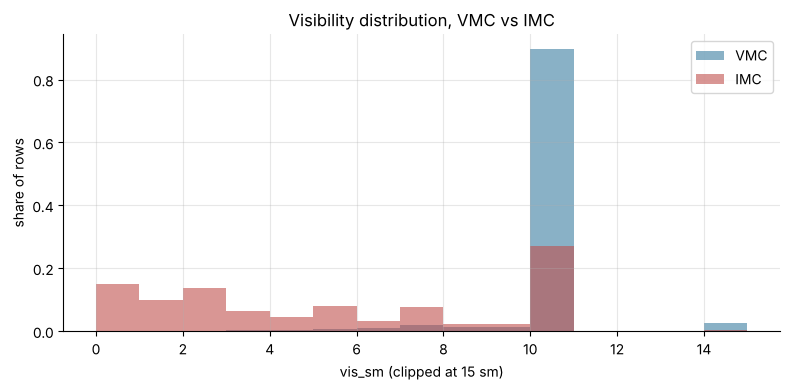

In [ ]:
print("vis_sm value counts:", W.vis_sm.value_counts().head(6).to_dict())
print("vis_sm == 10:", f"{(W.vis_sm == 10).mean():.1%}", "· vis_sm NaN:", int(W.vis_sm.isna().sum()),
      "· fatal rate of vis NaN rows:", round(W.loc[W.vis_sm.isna(), "fatal"].mean(), 3))
display(pd.crosstab(W.wx_cond_basic.fillna("NaN"), W.sky_cond_ceil.fillna("NaN")))

imc, vmc = W.wx_cond_basic == "IMC", W.wx_cond_basic == "VMC"
low_ceil = W.sky_cond_ceil.isin(["BKN", "OVC", "VV", "OBSC"]) & W.sky_ceil_ht.between(1, 999)
print("IMC rows:", int(imc.sum()), "· with known visibility:", int(W.loc[imc, "vis_sm"].notna().sum()))
print("IMC & vis_sm >= 5:", int((imc & (W.vis_sm >= 5)).sum()), "· IMC & vis_sm == 10:", int((imc & (W.vis_sm == 10)).sum()),
      "· IMC & ceiling NONE:", int((imc & (W.sky_cond_ceil == "NONE")).sum()))
print("VMC rows:", int(vmc.sum()), "· VMC & vis_sm < 3:", int((vmc & (W.vis_sm < 3)).sum()), "· VMC & vis_sm < 1:", int((vmc & (W.vis_sm < 1)).sum()))
print("rows with ceiling < 1,000 ft (BKN/OVC/VV):", int(low_ceil.sum()), "· of which VMC:", int((low_ceil & vmc).sum()), "· IMC:", int((low_ceil & imc).sum()))

fig, ax = plt.subplots(figsize=(8, 4))
for lab, m, col in [("VMC", vmc, "#3b7ea1"), ("IMC", imc, "#c0504d")]:
    ax.hist(W.loc[m, "vis_sm"].clip(upper=15).dropna(), bins=np.arange(0, 16, 1), alpha=.6, density=True, label=lab, color=col)
ax.set_xlabel("vis_sm (clipped at 15 sm)"); ax.set_ylabel("share of rows"); ax.set_title("Visibility distribution, VMC vs IMC"); ax.legend()
plt.tight_layout(); plt.show()

**Interpretation.**
- The classification is not a mechanical function of the station data: **363 of the 715 IMC rows with known visibility have 5 sm or more** (193 of them exactly 10 sm), and 28 IMC rows have no ceiling. Conversely, 50 VMC rows have visibility below 3 sm and 110 VMC rows have a ceiling below 1,000 ft. This is expected: the weather values come from the **nearest station, not from the accident site**, and `wx_cond_basic` describes the conditions at the site.
- Therefore `wx_cond_basic` is **not redundant** with `vis_sm` and the ceiling: it adds information, and it should be kept together with them.
- `vis_sm` is NaN in 721 rows (4.3%), with a fatal rate of 8.6% (below the base rate).

**→ NB1:** keep `wx_cond_basic` and the visibility/ceiling variables together; keep a `vis_sm_missing` flag; no row should be removed for being "contradictory" here.

## Part 3 · 11. Relation with the target `fatal`

**What we do:** fatal rate by category (with the number of rows on top of each bar, because IMC is rare and a rate without `n` can mislead) and by bins of the numeric columns. For the numeric ones we use only plausible values (temperature, altimeter), and we test the weather condition with a chi-square test.

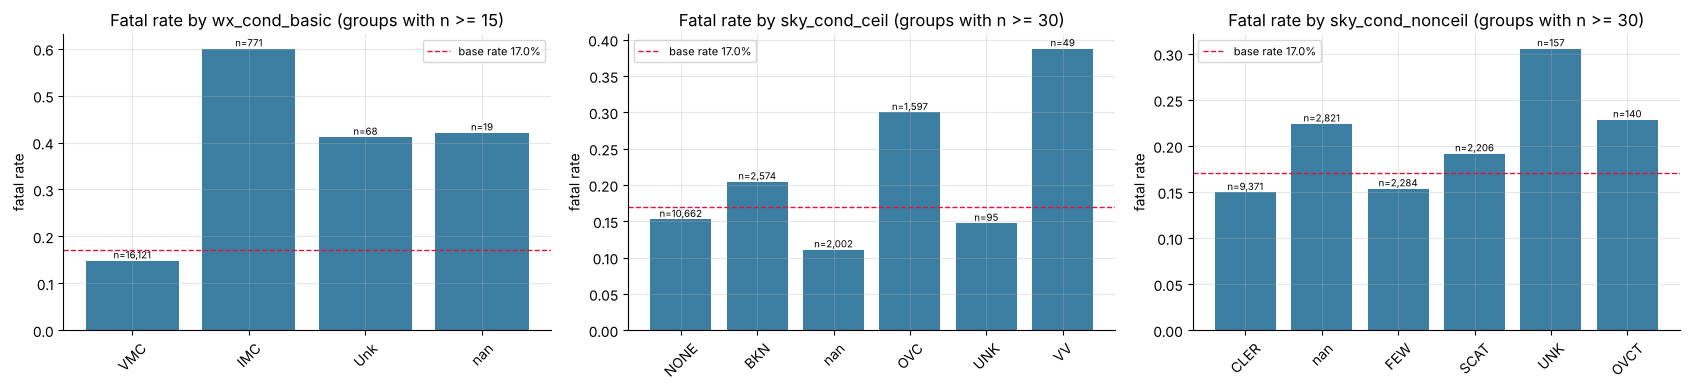

chi-square VMC / IMC / Unk: p = 1.2e-238
chi-square VMC vs IMC: p = 1.8e-234
IMC / VMC fatal-rate ratio: 4.05


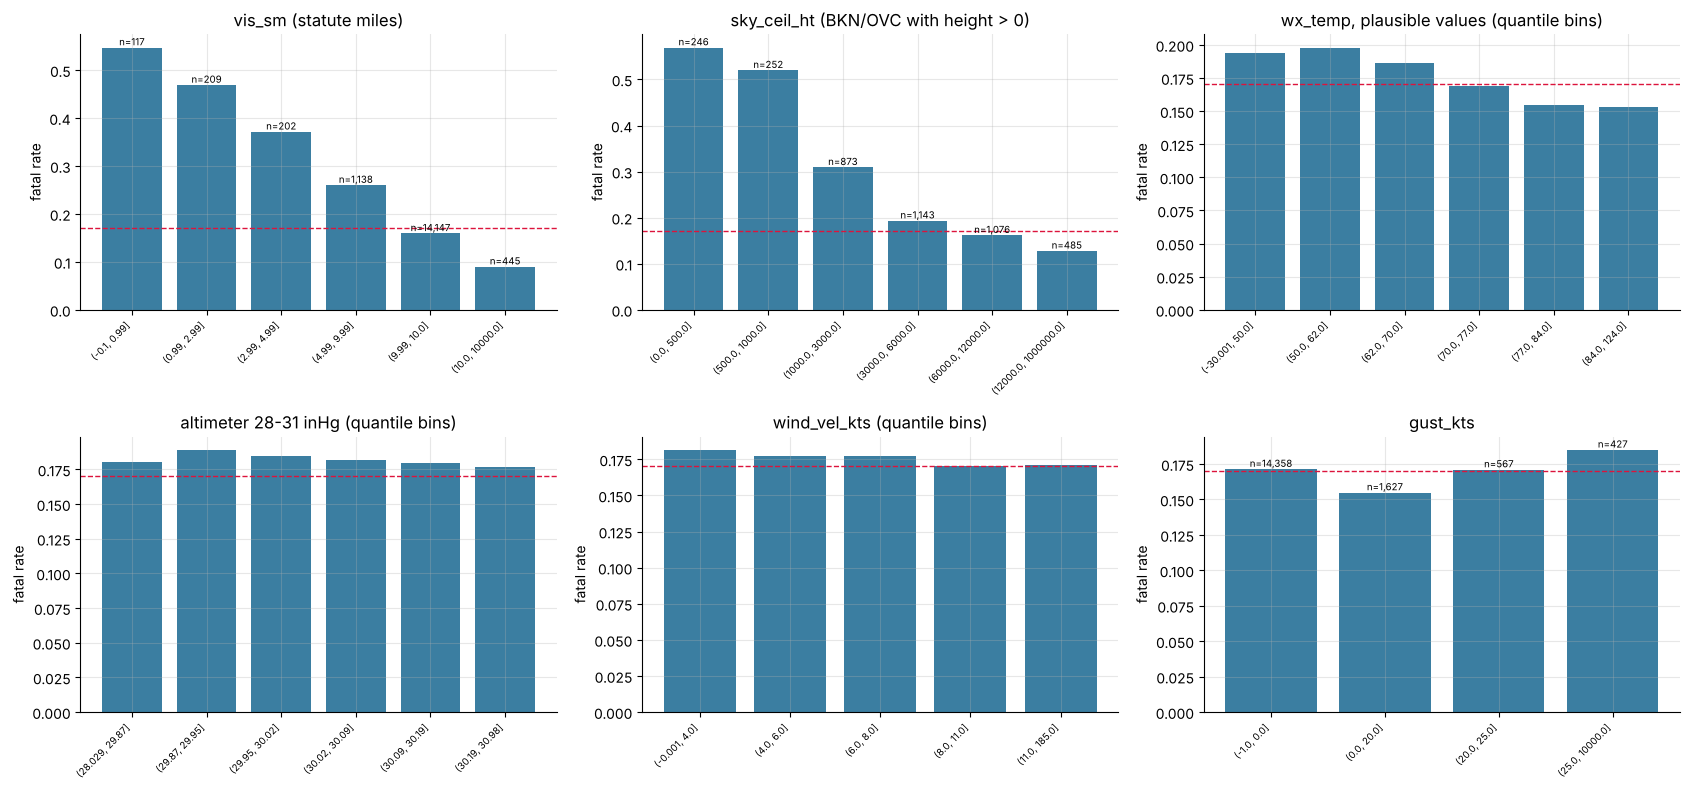

In [ ]:
from scipy.stats import chi2_contingency

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
plot_cat_vs_target(W, "wx_cond_basic", min_n=15, ax=ax[0])
plot_cat_vs_target(W, "sky_cond_ceil", min_n=30, ax=ax[1])
plot_cat_vs_target(W, "sky_cond_nonceil", min_n=30, ax=ax[2])
plt.tight_layout(); plt.show()

for lab, sub in [("VMC / IMC / Unk", W[W.wx_cond_basic.notna()]), ("VMC vs IMC", W[W.wx_cond_basic.isin(["VMC", "IMC"])])]:
    ct = pd.crosstab(sub.wx_cond_basic, sub.fatal)
    print(f"chi-square {lab}: p = {chi2_contingency(ct)[1]:.1e}")
r = W.groupby("wx_cond_basic")["fatal"].mean()
print("IMC / VMC fatal-rate ratio:", round(r["IMC"] / r["VMC"], 2))


def bar_bins(df, col, edges, ax, title):
    g = df.groupby(pd.cut(df[col], edges), observed=True)["fatal"].agg(rate="mean", n="size")
    ax.bar(range(len(g)), g["rate"], color="#3b7ea1")
    ax.set_xticks(range(len(g))); ax.set_xticklabels([str(i) for i in g.index], rotation=45, ha="right", fontsize=7)
    ax.axhline(BASE, color="crimson", ls="--", lw=1)
    for i, (rt, n) in enumerate(zip(g["rate"], g["n"])): ax.text(i, rt, f"n={n:,}", ha="center", va="bottom", fontsize=7)
    ax.set_ylabel("fatal rate"); ax.set_title(title); return g


fig, ax = plt.subplots(2, 3, figsize=(17, 8))
bar_bins(W, "vis_sm", [-0.1, 0.99, 2.99, 4.99, 9.99, 10, 1e4], ax[0, 0], "vis_sm (statute miles)")
ceil_m = W.sky_cond_ceil.isin(["BKN", "OVC"]) & (W.sky_ceil_ht > 0)
bar_bins(W[ceil_m], "sky_ceil_ht", [0, 500, 1000, 3000, 6000, 12000, 1e6], ax[0, 1], "sky_ceil_ht (BKN/OVC with height > 0)")
plot_num_vs_target(W[temp_ok], "wx_temp", q=6, ax=ax[0, 2], title="wx_temp, plausible values (quantile bins)")
plot_num_vs_target(W[W.altimeter.between(28, 31)], "altimeter", q=6, ax=ax[1, 0], title="altimeter 28-31 inHg (quantile bins)")
plot_num_vs_target(W[W.wind_vel_kts.notna()], "wind_vel_kts", q=5, ax=ax[1, 1], title="wind_vel_kts (quantile bins)")
bar_bins(W, "gust_kts", [-1, 0, 20, 25, 1e4], ax[1, 2], "gust_kts")
plt.tight_layout(); plt.show()

**Interpretation.**
- **`wx_cond_basic` is the strongest categorical weather variable**: IMC has a **60.1% fatal rate** (771 rows) against **14.8% for VMC**, a ratio of about 4 (chi-square p < 1e-200 for both tests). `Unk` (41.2%) and NaN (42.1%) are also high, but small (68 and 19 rows).
- **Ceiling:** `VV` 38.8% (only 49 rows), `OVC` 30.0%, `BKN` 20.4%, `NONE` 15.3%; the NaN group is low (11.1%). **Cloud cover (non-ceiling):** `UNK` 30.6%, `OVCT` 22.9%, NaN 22.4%, `SCAT` 19.2%, `FEW` 15.4%, `CLER` 15.0%.
- **Visibility** has a clear gradient: 54.7% below 1 sm, 46.9% for 1-3 sm, 37.1% for 3-5 sm, 26.0% for 5-10 sm, 15.9% at exactly 10 sm. Rows with visibility above 10 sm have only 9.0% (445 rows), which deserves a question (see section 9).
- **Ceiling height** (only BKN/OVC with a real height): 56.9% below 500 ft and 52.0% for 500-1,000 ft, decreasing to 12.8% above 12,000 ft: a strong, monotonic signal.
- **Temperature** has a mild trend (19.4% up to 50 °F, 15.3% above 84 °F). **Altimeter, wind speed and gusts have almost no signal on their own** (about 17-18% in every bin).
- **Caution:** IMC can be confounded with the type of flight, the phase or the pilot (Parts 5 and 6), and an association is not a cause.

**→ NB1:** keep `wx_cond_basic`, `sky_cond_ceil`, `vis_sm` and the real ceiling height as the main weather features; consider interactions with flight plan, pilot rating or phase of flight; `altimeter`, `wind_vel_kts` and `gust_kts` are low priority in feature selection.

## Part 3 · 12. Relations inside the group (cleaned copy)

**What we do:** Spearman correlation between the numeric weather columns and `fatal`, using a **cleaned throw-away copy** `C` (impossible values and disguised zeros set to NaN), so the zeros do not distort the result. `learn` is not changed.

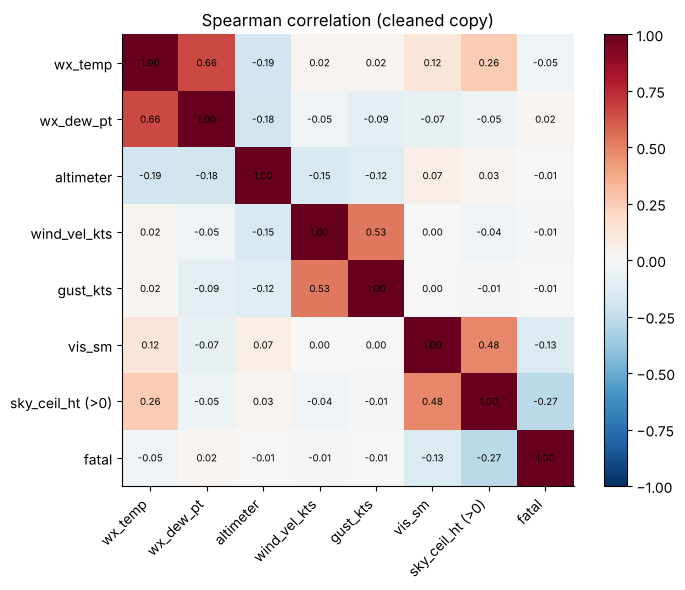

sky_ceil_ht (>0)   -0.270
vis_sm             -0.134
wx_temp            -0.045
wx_dew_pt           0.019
wind_vel_kts       -0.010
altimeter          -0.007
gust_kts           -0.006
Name: fatal, dtype: float64


In [ ]:
C = pd.DataFrame({
    "wx_temp": W.wx_temp.where(temp_ok),
    "wx_dew_pt": W.wx_dew_pt.where(clean),
    "altimeter": W.altimeter.where(W.altimeter.between(28, 31)),
    "wind_vel_kts": W.wind_vel_kts.where(W.wind_vel_kts <= 100),
    "gust_kts": W.gust_kts.where(W.gust_kts < 200),
    "vis_sm": W.vis_sm.where(W.vis_sm <= 30),
    "sky_ceil_ht (>0)": W.sky_ceil_ht.where(W.sky_ceil_ht > 0),
    "fatal": W.fatal,
})
corr = C.corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns); ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)): ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im); plt.title("Spearman correlation (cleaned copy)"); plt.tight_layout(); plt.show()
print(corr["fatal"].drop("fatal").sort_values(key=abs, ascending=False).round(3))

**Interpretation.**
- The expected physical relations appear: **temperature and dew point (0.66)**, **wind speed and gust speed (0.53)** and **visibility and ceiling height (0.48)**.
- With `fatal`, the largest values are for **`sky_ceil_ht` (-0.27)** and **`vis_sm` (-0.13)**: lower ceilings and lower visibility go with more fatal accidents. `wx_temp` is weak (-0.05) and the others are close to 0.
- Among themselves, temperature/dew point and wind/gust carry partly redundant information.

**→ NB1:** check redundancy (VIF or regularisation) if a linear model is used; consider `temp_dew_spread` instead of using both temperature columns; the weather signal comes mostly from visibility, ceiling and `wx_cond_basic`.

## Part 3 · 13. Findings and decisions for NB1 (input for Person 1's final table)

In [ ]:
findings_p3 = pd.DataFrame([
    ("wx_cond_basic", "IMC 60.1% fatal (n=771) vs VMC 14.8%; Unk 41.2% (n=68), NaN 42.1% (n=19); not a function of vis/ceiling (nearest station)", "Keep as a main feature; keep Unk/NaN as explicit categories; keep together with vis_sm and ceiling"),
    ("sky_cond_ceil, sky_cond_nonceil", "Unknown written two ways (UNK vs NaN) with different fatal rates; OBSC never appears; VV only 49 rows", "Keep NaN and UNK as categories (or test merging); group rare codes (VV, OVCT)"),
    ("altimeter", "1,510 zeros (fatal 5.6% vs 18.1%); 54 values look like x100 (2,997 = 29.97); 23 others outside 28-31 (2 above 100, 18 below 28, 3 between 31 and 100)", "0 -> NaN + flag; divide the 2,800-3,200 values by 100 (confirm); rest outside 28-31 -> NaN"),
    ("wx_temp", "855 zeros (isolated spike, 39% in Jun-Aug; fatal 6.7%); 31 values > 130 F (up to 3,005), 1 < -40 F", "0 -> NaN + flag; values outside [-40, 130] -> NaN"),
    ("wx_dew_pt", "1,639 zeros (674 with temperature 40-130 F, so not real); 10 values > 130 F", "0 -> NaN + flag; > 130 -> NaN"),
    ("altimeter, wx_temp, wx_dew_pt", "771 rows have the three zeros together; 1,874 rows with any zero have ~6.4% fatal; share drops from 23% (2008) to ~4% (2015+) and is higher when apt_elev is missing", "Build wx_obs_missing flag; check the ev_year effect before choosing the imputation"),
    ("wind_dir_deg, wind_vel_kts", "dir == 0 in 4,387 rows: 51 calm (real), 3,543 with speed NaN (no data), 793 with speed > 0 (suspicious); speed NaN 21.2% every year", "dir 0 with speed NaN -> NaN (keep 0 only when speed = 0); wind_missing flag; cap speed (> 100 kt)"),
    ("gust_ind", "Practically inverted: 10,929 of 10,934 T rows have gust_kts == 0; 2,616 of 2,621 gusts have F; no signal (17.2% vs 16.6%)", "Do not use as is; build gust_present = gust_kts > 0"),
    ("gust_kts", "0 is a real 'no gust' (84.6%); 24 gusts slower than the wind; one value 1,077 kt; weak signal (15.5%-18.5%)", "Cap / NaN above ~200 kt; low priority"),
    ("sky_ceil_ht", "75.6% zeros mean 'no ceiling / no data' (10,641 of 10,662 NONE); 96 BKN/OVC with height 0 and 21 NONE with height > 0; 289 values > 20,000 ft; strong signal (56.9% below 500 ft)", "Split into has_ceiling + real height (NaN when no ceiling); contradictions -> NaN; cap height"),
    ("wx_temp_c", "Exact conversion of wx_temp (max diff 0.044, corr 1.00): redundant, NOT the mixed-unit column (that one is eng_power)", "Drop wx_temp_c"),
    ("wx_temp, wx_dew_pt", "Dew point > temperature in 245 plausible rows, but 182 are equality; only 62 exceed 2 F and 39 exceed 5 F", "Create temp_dew_spread; set the 39 rows > 5 F to NaN (or keep)"),
    ("vis_sm", "NaN 4.3% (fatal 8.6%); 87% of known values are exactly 10; 445 rows > 10 sm (fatal 9.0%), 2 rows > 100 sm (up to 5,000); strong gradient (54.7% below 1 sm)", "vis_sm_missing flag; cap/NaN > 100; question: are values > 10 a special code?"),
    ("altimeter, wind_vel_kts, gust_kts", "Almost no relation with fatal (17-18% in every bin)", "Low priority in feature selection"),
    ("weather group", "Spearman: temp-dew 0.66, wind-gust 0.53, vis-ceiling 0.48; with fatal only ceiling height (-0.27) and visibility (-0.13) matter", "Check redundancy (VIF / regularisation); the signal comes from vis, ceiling and wx_cond_basic"),
    ("all", "predict has the same problems in the same proportions (370 altimeter zeros, 213 temp zeros, 5 temps > 130 F, 12 altimeters > 100...)", "Apply every rule to learn and predict, with parameters learned only on training data"),
], columns=["Column(s)", "Finding", "Decision / question for NB1"])

pd.set_option("display.max_colwidth", 140)
findings_p3

,Column(s),Finding,Decision / question for NB1
0,wx_cond_basic,"IMC 60.1% fatal (n=771) vs VMC 14.8%; Unk 41.2% (n=68), NaN 42.1% (n=19); not a function of vis/ceiling (nearest station)",Keep as a main feature; keep Unk/NaN as explicit categories; keep together with vis_sm and ceiling
1,"sky_cond_ceil, sky_cond_nonceil",Unknown written two ways (UNK vs NaN) with different fatal rates; OBSC never appears; VV only 49 rows,"Keep NaN and UNK as categories (or test merging); group rare codes (VV, OVCT)"
2,altimeter,"1,510 zeros (fatal 5.6% vs 18.1%); 54 values look like x100 (2,997 = 29.97); 23 others outside 28-31 (2 above 100, 18 below 28, 3 betwee...","0 -> NaN + flag; divide the 2,800-3,200 values by 100 (confirm); rest outside 28-31 -> NaN"
3,wx_temp,"855 zeros (isolated spike, 39% in Jun-Aug; fatal 6.7%); 31 values > 130 F (up to 3,005), 1 < -40 F","0 -> NaN + flag; values outside [-40, 130] -> NaN"
4,wx_dew_pt,"1,639 zeros (674 with temperature 40-130 F, so not real); 10 values > 130 F",0 -> NaN + flag; > 130 -> NaN
5,"altimeter, wx_temp, wx_dew_pt","771 rows have the three zeros together; 1,874 rows with any zero have ~6.4% fatal; share drops from 23% (2008) to ~4% (2015+) and is hig...",Build wx_obs_missing flag; check the ev_year effect before choosing the imputation
6,"wind_dir_deg, wind_vel_kts","dir == 0 in 4,387 rows: 51 calm (real), 3,543 with speed NaN (no data), 793 with speed > 0 (suspicious); speed NaN 21.2% every year",dir 0 with speed NaN -> NaN (keep 0 only when speed = 0); wind_missing flag; cap speed (> 100 kt)
7,gust_ind,"Practically inverted: 10,929 of 10,934 T rows have gust_kts == 0; 2,616 of 2,621 gusts have F; no signal (17.2% vs 16.6%)",Do not use as is; build gust_present = gust_kts > 0
8,gust_kts,"0 is a real 'no gust' (84.6%); 24 gusts slower than the wind; one value 1,077 kt; weak signal (15.5%-18.5%)",Cap / NaN above ~200 kt; low priority
9,sky_ceil_ht,"75.6% zeros mean 'no ceiling / no data' (10,641 of 10,662 NONE); 96 BKN/OVC with height 0 and 21 NONE with height > 0; 289 values > 20,0...",Split into has_ceiling + real height (NaN when no ceiling); contradictions -> NaN; cap height


# ━━━━━━━━━━ PART 4 · Aircraft and engine (Person 4) ━━━━━━━━━━

Columns covered (11): `acft_category`, `homebuilt`, `fixed_retractable`, `acft_make`, `ifr_equipped_cert`, `num_eng`, `total_seats`, `acft_year`, `eng_type`, `carb_fuel_injection`, `eng_power`.

NB0 does not change the data and does not train models. When a cleaning step is needed just to *look* at something (for example upper-casing a category), it is done on a throw-away copy, and the real cleaning is listed as a decision for NB1 at the end of this part.

In [9]:
# Only needed by Part 4
import re

GROUP = ["acft_category", "homebuilt", "fixed_retractable", "acft_make", "ifr_equipped_cert",
         "num_eng", "total_seats", "acft_year", "eng_type", "carb_fuel_injection", "eng_power"]

## Part 4 · 1. Overview of the group

**What we do:** data types, missing values and cardinality of the 11 columns, in `learn` and in `predict`.

In [10]:
ov = pd.DataFrame({
    "dtype": learn[GROUP].dtypes.astype(str),
    "missing_learn_%": (learn[GROUP].isna().mean() * 100).round(1),
    "missing_predict_%": (predict[GROUP].isna().mean() * 100).round(1),
    "n_unique": learn[GROUP].nunique(),
})
ov

,dtype,missing_learn_%,missing_predict_%,n_unique
acft_category,str,0.0,0.0,19
homebuilt,str,0.0,0.0,4
fixed_retractable,str,0.0,0.0,2
acft_make,str,0.0,0.0,2914
ifr_equipped_cert,int64,0.0,0.0,2
num_eng,float64,2.9,2.8,7
total_seats,float64,7.1,7.2,135
acft_year,float64,40.1,39.8,102
eng_type,str,3.5,3.7,11
carb_fuel_injection,str,21.2,21.5,2


**Interpretation.**
- Missingness is very uneven: `acft_year` (40%), `carb_fuel_injection` (21%), `eng_power` (11%), `total_seats` (7%), `eng_type` (3.5%), `num_eng` (2.9%). The other six columns are complete. `learn` and `predict` have similar missing rates, which is good (no shift in how the data was collected).
- `acft_make` has 2,914 distinct values: it is a free-text field, not a real category (section 3).
- `num_eng`, `total_seats`, `acft_year` and `eng_power` are floats only because of the NaNs.

**→ NB1:** missing values need an explicit strategy per column (imputation and/or a missing indicator). Section 6 shows that the 40% in `acft_year` is not random.

## Part 4 · 2. Inconsistent case: `acft_category` and `homebuilt`

**What we do:** the brief warns that `AIR`/`air`, `HELI`/`heli` and `Y`/`y` coexist. We check how widespread it is (also in `predict`) and whether the lowercase rows mean something different. We work on a copy `A`; `learn` is untouched.

In [11]:
for col in ["acft_category", "homebuilt"]:
    print(pd.concat({"learn": learn[col].value_counts(), "predict": predict[col].value_counts()}, axis=1)
            .fillna(0).astype(int).sort_values("learn", ascending=False), "\n")

print("rows with lowercase acft_category:", (learn.acft_category.str.islower()).sum(),
      f"({learn.acft_category.str.islower().mean():.1%})")
print("rows with lowercase homebuilt:    ", (learn.homebuilt.str.islower()).sum(),
      f"({learn.homebuilt.str.islower().mean():.1%})")

               learn  predict
acft_category                
AIR            10899     2746
air             3655      885
HELI            1285      325
heli             382       85
GLI              208       61
BALL             105       21
WSFT              98       25
GYRO              90       18
gli               64       30
PPAR              53       13
wsft              40       10
ball              31        9
gyro              29       10
ppar              19        3
ULTR              13        2
ultr               4        0
PLFT               2        1
RCKT               1        0
BLIM               1        0
plft               0        1 

           learn  predict
homebuilt                
N          10894     2760
n           3707      912
Y           1797      426
y            581      147 

rows with lowercase acft_category: 4224 (24.9%)
rows with lowercase homebuilt:     4288 (25.3%)


Fatal rate: uppercase vs lowercase spelling (same category?)
            mean   size
was_lower              
False      0.171  12755
True       0.168   4224 



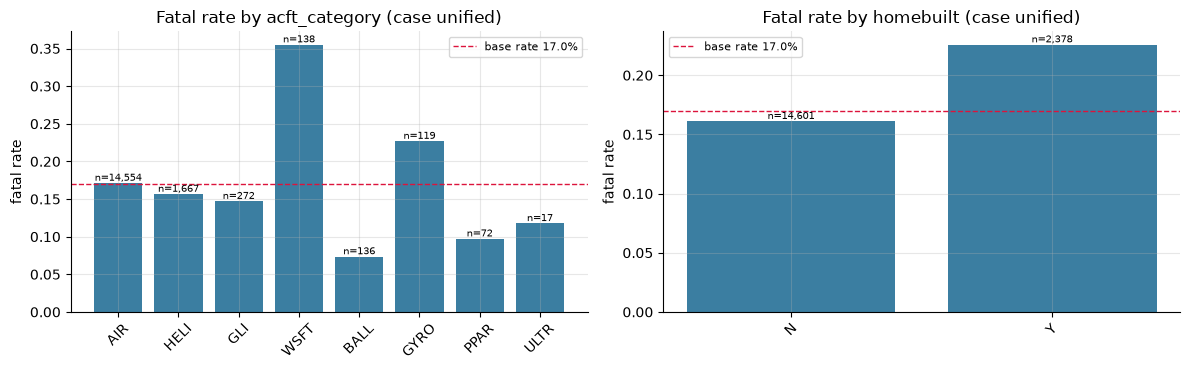

In [12]:
A = learn.copy()                                  # throw-away copy for analysis only
A["acft_category_u"] = A["acft_category"].str.upper()
A["homebuilt_u"] = A["homebuilt"].str.upper()
A["was_lower"] = A["acft_category"].str.islower()

print("Fatal rate: uppercase vs lowercase spelling (same category?)")
print(A.groupby("was_lower")["fatal"].agg(["mean", "size"]).round(3), "\n")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
plot_cat_vs_target(A, "acft_category_u", min_n=15, ax=ax[0], title="Fatal rate by acft_category (case unified)")
plot_cat_vs_target(A, "homebuilt_u", min_n=15, ax=ax[1], title="Fatal rate by homebuilt (case unified)")
plt.tight_layout(); plt.show()

**Interpretation.**
- About a quarter of the rows are lowercase (`air` 3,655 vs `AIR` 10,899, `n` 3,707 vs `N` 10,894...) and `predict` has the same pattern, so a model fed the raw strings would treat `AIR` and `air` as different levels.
- Lowercase is **noise in the spelling**, not information: the fatal rate is about the same in both groups. After unifying, the categories behave sensibly: airplanes and helicopters are close to the base rate (17%/16%), weight-shift (`WSFT`) is much riskier (36%), balloons and powered parachutes are safer (7–10%). Homebuilt aircraft are more fatal (23% vs 16%).
- Several categories are tiny (`PLFT` 2, `RCKT` 1, `BLIM` 1, `ULTR` 17): their rates are meaningless.

**→ NB1:** upper-case both columns (and apply the same function to `predict`); group categories with fewer than about 30 rows into `OTHER`.

## Part 4 · 3. Aircraft make: `acft_make`

**What we do:** study the cardinality, the spelling variants and the rare makes. Normalisation here (upper case, remove punctuation and company suffixes) is only used to *measure* how much of the 2,914 distinct values are really the same make.

In [13]:
def norm_make(s):
    s = str(s).upper()
    s = re.sub(r"[^A-Z0-9 ]", "", s)
    s = re.sub(r"\b(INC|CORP|CORPORATION|CO|COMPANY|LLC|LTD|THE)\b", "", s)
    return re.sub(r"\s+", " ", s).strip()

A["make_n"] = A["acft_make"].map(norm_make)
P = predict.copy(); P["make_n"] = P["acft_make"].map(norm_make)

vc = A["make_n"].value_counts()
print(f"distinct raw values: {learn.acft_make.nunique():,} · after light normalisation: {A.make_n.nunique():,}")
print(f"makes with >=100 rows: {(vc >= 100).sum()} · >=30 rows: {(vc >= 30).sum()} · <=5 rows: {(vc <= 5).sum():,} · exactly 1 row: {(vc == 1).sum():,}")
print(f"share of rows covered by top 10 / 50 / 200 makes: "
      f"{vc.head(10).sum()/len(A):.0%} / {vc.head(50).sum()/len(A):.0%} / {vc.head(200).sum()/len(A):.0%}")
print(f"share of rows that belong to makes with <=5 rows: {vc[vc <= 5].sum()/len(A):.1%}")
print(f"share of predict rows whose (normalised) make never appears in learn: {(~P.make_n.isin(A.make_n)).mean():.1%}")
print("\nSpelling variants, e.g. ROBINSON and CESSNA:")
print(learn[learn.acft_make.str.upper().str.contains("ROBINSON HELI|^ROBINSON$")].acft_make.value_counts().head(6).to_string())
print(learn[learn.acft_make.str.upper().str.contains("CESSNA")].acft_make.value_counts().head(5).to_string())

distinct raw values: 2,914 · after light normalisation: 2,803
makes with >=100 rows: 17 · >=30 rows: 50 · <=5 rows: 2,614 · exactly 1 row: 2,299
share of rows covered by top 10 / 50 / 200 makes: 56% / 71% / 82%
share of rows that belong to makes with <=5 rows: 18.6%
share of predict rows whose (normalised) make never appears in learn: 13.2%

Spelling variants, e.g. ROBINSON and CESSNA:
acft_make
ROBINSON HELICOPTER            194
ROBINSON HELICOPTER COMPANY    155
ROBINSON                       143
ROBINSON HELICOPTER CO          15
acft_make
CESSNA                   4248
CESSNA AIRCRAFT CO         21
CESSNA ECTOR                4
CESSNA/AIR REPAIR INC       2
POOL CESSNA                 1


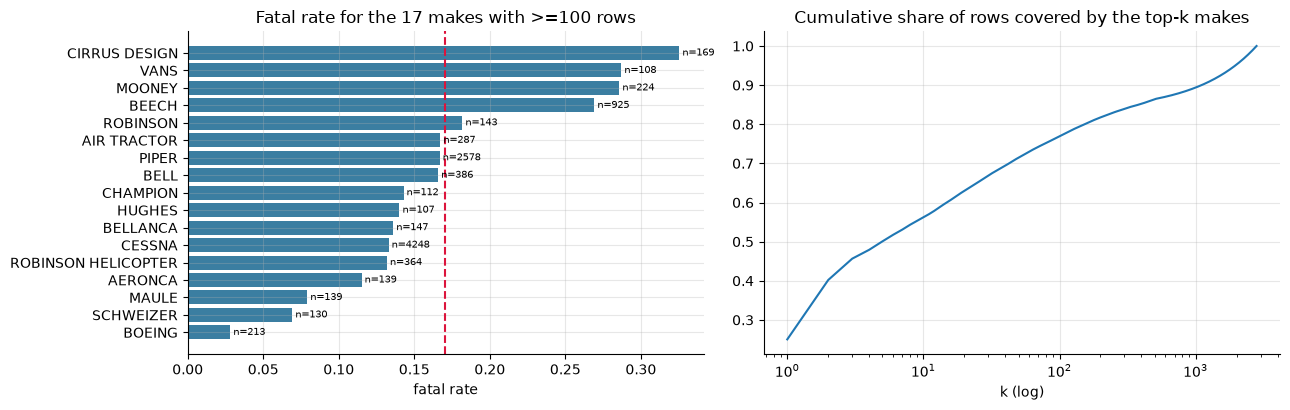

fatal rate, makes with <=5 rows vs the rest: 0.21 vs 0.161


In [14]:
top = vc[vc >= 100].index
g = (A[A.make_n.isin(top)].groupby("make_n")["fatal"].agg(rate="mean", n="size").sort_values("rate"))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].barh(g.index, g["rate"], color="#3b7ea1"); ax[0].axvline(BASE, color="crimson", ls="--")
for i, (r, n) in enumerate(zip(g["rate"], g["n"])): ax[0].text(r, i, f" n={n}", va="center", fontsize=7)
ax[0].set_title("Fatal rate for the 17 makes with >=100 rows"); ax[0].set_xlabel("fatal rate")

rank = np.arange(1, len(vc) + 1)
ax[1].plot(rank, vc.values.cumsum() / vc.sum()); ax[1].set_xscale("log")
ax[1].set_title("Cumulative share of rows covered by the top-k makes"); ax[1].set_xlabel("k (log)")
plt.tight_layout(); plt.show()

rare = A["make_n"].map(vc) <= 5
print("fatal rate, makes with <=5 rows vs the rest:", round(A[rare].fatal.mean(), 3), "vs", round(A[~rare].fatal.mean(), 3))

**Interpretation.**
- Light normalisation only reduces 2,914 values to ~2,800 and merges the big duplicates (`ROBINSON` vs `ROBINSON HELICOPTER`, `CESSNA` vs `CESSNA AIRCRAFT CO`). The remaining ones are mostly one-off names (homebuilders, individuals, old manufacturers): ~2,300 makes appear only once.
- It is a long-tail variable: only 17 makes have ≥ 100 rows (top 10 ≈ 56% of the rows, top 50 ≈ 71%) while ~19% of the rows belong to makes with ≤ 5 rows.
- About **13% of `predict` rows have a make that never appears in `learn`**, so the model will have to deal with unseen categories. A plain one-hot over all makes would be huge and mostly useless.
- There *is* signal in the big makes: Boeing 3%, Schweizer 7%, Maule 8% versus Cirrus 33%, Vans 29%, Mooney 29%, Beech 27% (base rate 17%). Rare makes are riskier than average (21% vs 16%), probably because they are homebuilt/experimental or old aircraft.

**→ NB1:** (1) normalise the text; (2) keep the top ~30–50 makes and group the rest as `OTHER` (or use frequency encoding / target encoding **inside** the cross-validation to avoid leakage); (3) add a `make_is_rare` flag; (4) make sure the encoding handles makes unseen in `learn`.

## Part 4 · 4. Other categorical columns versus the target

**What we do:** `fixed_retractable`, `ifr_equipped_cert`, `num_eng`, `eng_type` and `carb_fuel_injection` against `fatal`. Missing values are kept as their own group (`dropna=False`) so we can see if missing is informative.

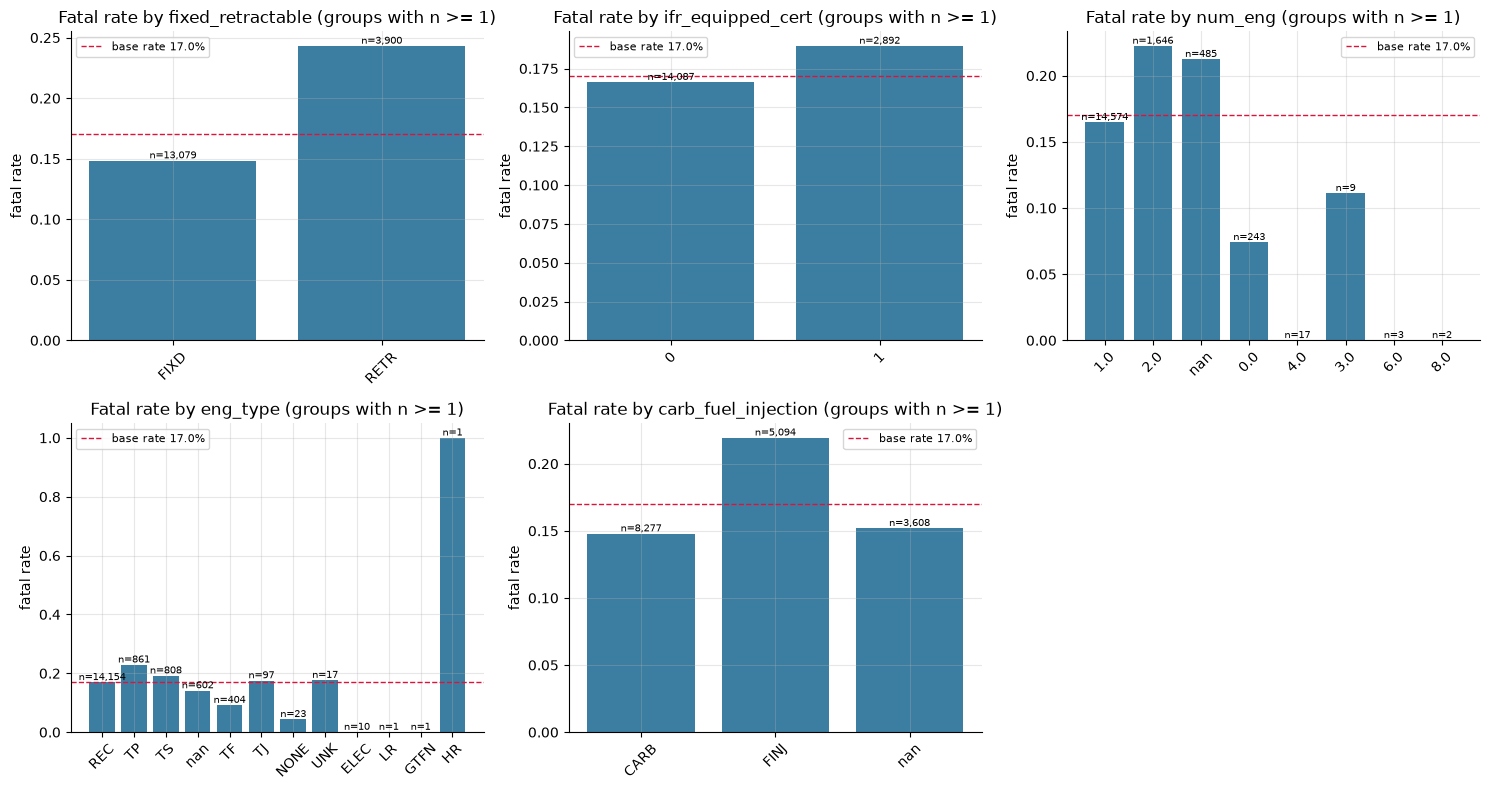

In [15]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
plot_cat_vs_target(A, "fixed_retractable", min_n=1, ax=ax[0, 0])
plot_cat_vs_target(A, "ifr_equipped_cert", min_n=1, ax=ax[0, 1])
plot_cat_vs_target(A, "num_eng", min_n=1, ax=ax[0, 2])
plot_cat_vs_target(A, "eng_type", min_n=1, ax=ax[1, 0])
plot_cat_vs_target(A, "carb_fuel_injection", min_n=1, ax=ax[1, 1])
ax[1, 2].axis("off")
plt.tight_layout(); plt.show()

In [16]:
print("eng_type vs carb_fuel_injection (counts):")
print(pd.crosstab(A.eng_type.fillna("NaN"), A.carb_fuel_injection.fillna("NaN")))
print("\nnum_eng == 0 by aircraft category:")
print(A[A.num_eng == 0].acft_category_u.value_counts())

eng_type vs carb_fuel_injection (counts):
carb_fuel_injection  CARB  FINJ   NaN
eng_type                             
ELEC                    0     0    10
GTFN                    0     0     1
HR                      0     0     1
LR                      0     0     1
NONE                    0     0    23
NaN                     1     0   601
REC                  8270  4595  1289
TF                      1    62   341
TJ                      0    22    75
TP                      0   199   662
TS                      2   213   593
UNK                     3     3    11

num_eng == 0 by aircraft category:
acft_category_u
GLI     168
BALL     73
AIR       2
Name: count, dtype: int64


**Interpretation.**
- **Retractable gear** is clearly riskier (24% vs 15%). Faster, more complex aircraft: a strong, simple feature.
- `num_eng`: twins (2) are riskier (22%) than singles (16.5%). `num_eng = 0` (243 rows, 7% fatal) are gliders and balloons, so it is a valid value, not an error. 3, 4, 6, 8 engines are almost never seen (≤ 17 rows).
- `eng_type`: `REC` (piston) is 83% of the data. `TP` turboprop has the highest rate (23%); `TF` turbofan is the lowest (9%, large airliners). Rare codes (`HR`, `GTFN`, `LR`, `ELEC`, `NONE`, `UNK`) have ≤ 23 rows.
- `carb_fuel_injection`: fuel-injected is riskier (22% vs 15%). But `NaN` is **structural**: it only makes sense for piston engines, and it is missing for 73–84% of turbine engines and 100% of electric/no-engine. That is "not applicable", not "unknown". Within `REC` it is missing for only 9%.
- `ifr_equipped_cert` has a weak effect (19% vs 17%).

**→ NB1:** keep `NaN` in `carb_fuel_injection` as an explicit category (`NOT_APPLICABLE`/`UNKNOWN`), group rare `eng_type` codes, cap `num_eng` at 3+ (or treat as category). Question: `retractable`, `eng_type` and `num_eng` are probably correlated (powerful complex aircraft): check redundancy during feature selection.

## Part 4 · 5. The column whose unit changes: `eng_power`

**What we do:** the dictionary says `eng_power` is horsepower for piston and turboprop engines and pounds of thrust for jets. We plot it split by `eng_type` and look at zeros and extremes.

            count     mean      std      min      25%      50%      75%       max
eng_type                                                                         
ELEC          4.0     27.0     18.0      5.0     20.0     27.0     34.0      50.0
GTFN          1.0   3399.0      NaN   3399.0   3399.0   3399.0   3399.0    3399.0
HR            1.0  59570.0      NaN  59570.0  59570.0  59570.0  59570.0   59570.0
REC       13217.0    202.0    154.0      0.0    132.0    179.0    252.0    3293.0
TF          334.0  17441.0  24197.0      0.0   3261.0   8926.0  23993.0  264190.0
TJ           87.0   9312.0  12840.0      0.0   2072.0   3424.0  10717.0   63837.0
TP          765.0    846.0    566.0      0.0    661.0    754.0    908.0   10378.0
TS          733.0    722.0   2797.0     91.0    413.0    519.0    707.0   75552.0
UNK           6.0    224.0     89.0    143.0    156.0    194.0    283.0     356.0


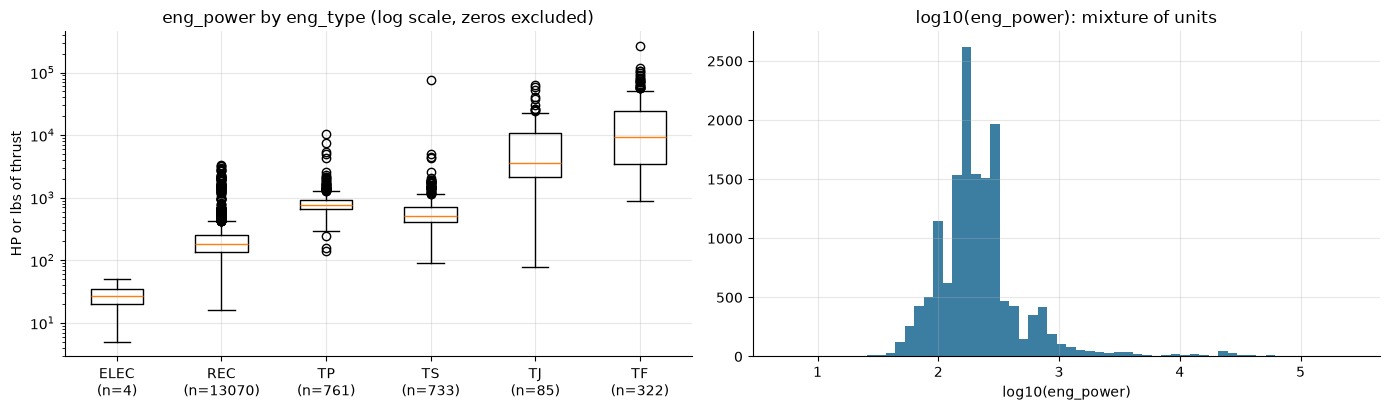


eng_power == 0: 171 rows · by eng_type:
eng_type
REC    147
TF      12
NaN      6
TP       4
TJ       2
Name: count, dtype: int64

lowest power among jets (lbs of thrust should be in the thousands):
[77.0, 82.0, 88.0, 93.0, 240.0]
piston (REC) engines above 1,500 HP: 39 → mostly large vintage aircraft

missing eng_power by eng_type (share):
eng_type
ELEC    0.60
LR      1.00
NONE    1.00
NaN     0.95
REC     0.07
TF      0.17
TJ      0.10
TP      0.11
TS      0.09
UNK     0.65
Name: eng_power, dtype: float64


In [17]:
order = ["ELEC", "REC", "TP", "TS", "TJ", "TF"]
print(A.groupby("eng_type")["eng_power"].describe().round(0).loc[lambda d: d["count"] > 0])

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
data = [A.loc[(A.eng_type == t) & (A.eng_power > 0), "eng_power"] for t in order]
ax[0].boxplot(data, tick_labels=[f"{t}\n(n={len(d)})" for t, d in zip(order, data)], showfliers=True)
ax[0].set_yscale("log"); ax[0].set_title("eng_power by eng_type (log scale, zeros excluded)"); ax[0].set_ylabel("HP or lbs of thrust")
ax[1].hist(np.log10(A.loc[A.eng_power > 0, "eng_power"]), bins=60, color="#3b7ea1")
ax[1].set_title("log10(eng_power): mixture of units"); ax[1].set_xlabel("log10(eng_power)")
plt.tight_layout(); plt.show()

print("\neng_power == 0:", (A.eng_power == 0).sum(), "rows · by eng_type:")
print(A[A.eng_power == 0].eng_type.value_counts(dropna=False).head())
print("\nlowest power among jets (lbs of thrust should be in the thousands):")
print(A[A.eng_type.isin(["TF", "TJ"]) & (A.eng_power > 0)].eng_power.nsmallest(5).tolist())
print("piston (REC) engines above 1,500 HP:", ((A.eng_type == "REC") & (A.eng_power > 1500)).sum(), "→ mostly large vintage aircraft")
print("\nmissing eng_power by eng_type (share):")
print(A.eng_power.isna().groupby(A.eng_type.fillna("NaN")).mean().round(2).loc[lambda s: s > 0])

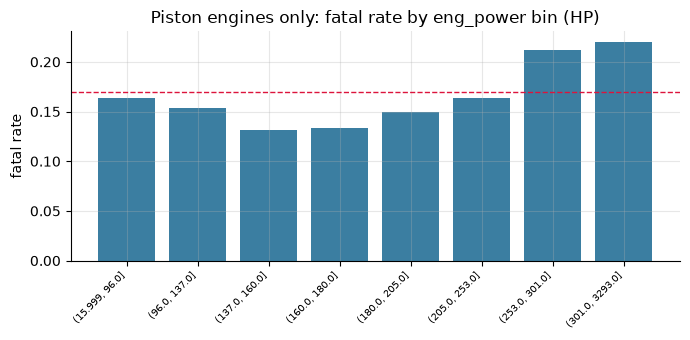

Fatal rate by eng_type, power==0 vs >0 (piston): {False: 0.169, True: 0.136}


In [18]:
# Does power matter inside each unit family? (fatal rate by quantile bin, piston only)
rec = A[(A.eng_type == "REC") & (A.eng_power > 0)]
plot_num_vs_target(rec, "eng_power", q=8, title="Piston engines only: fatal rate by eng_power bin (HP)")
plt.tight_layout(); plt.show()
print("Fatal rate by eng_type, power==0 vs >0 (piston):",
      A[A.eng_type == "REC"].groupby(A.eng_power.eq(0))["fatal"].mean().round(3).to_dict())

**Interpretation.**
- The unit problem is real and big: piston engines are around 100–300 (HP), turboprops ~750 HP, but turbofans have a median of ~8,900 and go up to 264,190 (lbs of thrust, with outliers that look like errors). The histogram in log scale is a mix of two populations. A single numeric `eng_power` makes a jet look 50× "more powerful" than a piston when it has nothing to do with it, and it would dominate any distance- or scale-based model (and the mean/std).
- `eng_power = 0` in 171 rows (147 of them piston): impossible, it is a missing-value code. A few jets have power < 1,000 (probably HP-style entries in the wrong unit).
- `eng_power` is missing together with `eng_type`: for rows where `eng_type` is `NaN` it is missing 95% of the time.
- Within piston engines, check the last plot: if the fatal rate changes across HP bins there is signal once the unit is homogeneous (this is the comparison that makes sense; mixing HP and lbs is not).

**→ NB1:** treat `eng_power = 0` as `NaN`; build `eng_power_hp` (piston/turboprop/turboshaft/electric) and `eng_thrust_lbs` (TF/TJ) as two separate features (or a log-transform *interacted* with engine family). Cap or winsorise extreme values. Question: impute power by median per `eng_type`, or only flag it?

## Part 4 · 6. Impossible values: `total_seats` and `acft_year`

**What we do:** look for values that cannot be true (`acft_year` after the accident year or absurdly old, odd seat counts) and understand why `acft_year` is missing 40% of the time.

In [19]:
print("=== total_seats ===")
print("seats == 0:", (A.total_seats == 0).sum(), " seats > 100:", (A.total_seats > 100).sum(), " max:", A.total_seats.max())
print(A.total_seats.describe().round(1).to_dict())
print("\nseats > 100: category / operation / fatal rate")
big = A[A.total_seats > 100]
print(big.acft_category_u.value_counts().to_dict(), big.far_part.value_counts().head(3).to_dict(), "fatal:", round(big.fatal.mean(), 3))
print("odd seat counts (3,5,7,9) vs even (2,4,6,8):", A.total_seats.isin([3, 5, 7, 9]).sum(), "vs", A.total_seats.isin([2, 4, 6, 8]).sum())
print("seats, median by category:", A.groupby("acft_category_u").total_seats.median().to_dict())

print("\n=== acft_year ===")
y = A["acft_year"]
print("acft_year == 0:", (y == 0).sum(), "· < 1900 (and > 0):", ((y > 0) & (y < 1900)).sum(), "· > ev_year:", (y > A.ev_year).sum(),
      "· max:", y.max(), "(accident years go up to", A.ev_year.max(), ")")
print("how far in the future (years):", (y - A.ev_year)[y > A.ev_year].value_counts().to_dict())
print("aircraft age at accident, valid rows:", (A.ev_year - y)[(y > 1900) & (y <= A.ev_year)].describe().round(1).to_dict())

=== total_seats ===
seats == 0: 37  seats > 100: 168  max: 8300.0
{'count': 15773.0, 'mean': 6.6, 'std': 78.1, 'min': 0.0, '25%': 2.0, '50%': 4.0, '75%': 4.0, 'max': 8300.0}

seats > 100: category / operation / fatal rate
{'AIR': 168} {'121': 158, '129': 5, '091': 4} fatal: 0.006
odd seat counts (3,5,7,9) vs even (2,4,6,8): 1166 vs 12762
seats, median by category: {'AIR': 4.0, 'BALL': 1.0, 'BLIM': 4.0, 'GLI': 1.0, 'GYRO': 2.0, 'HELI': 4.0, 'PLFT': 0.0, 'PPAR': 2.0, 'RCKT': nan, 'ULTR': 2.0, 'WSFT': 2.0}

=== acft_year ===
acft_year == 0: 1 · < 1900 (and > 0): 2 · > ev_year: 86 · max: 2025.0 (accident years go up to 2023 )
how far in the future (years): {1.0: 75, 2.0: 10, 3.0: 1}
aircraft age at accident, valid rows: {'count': 10074.0, 'mean': 34.8, 'std': 21.5, 'min': 0.0, '25%': 15.0, '50%': 38.0, '75%': 51.0, 'max': 105.0}


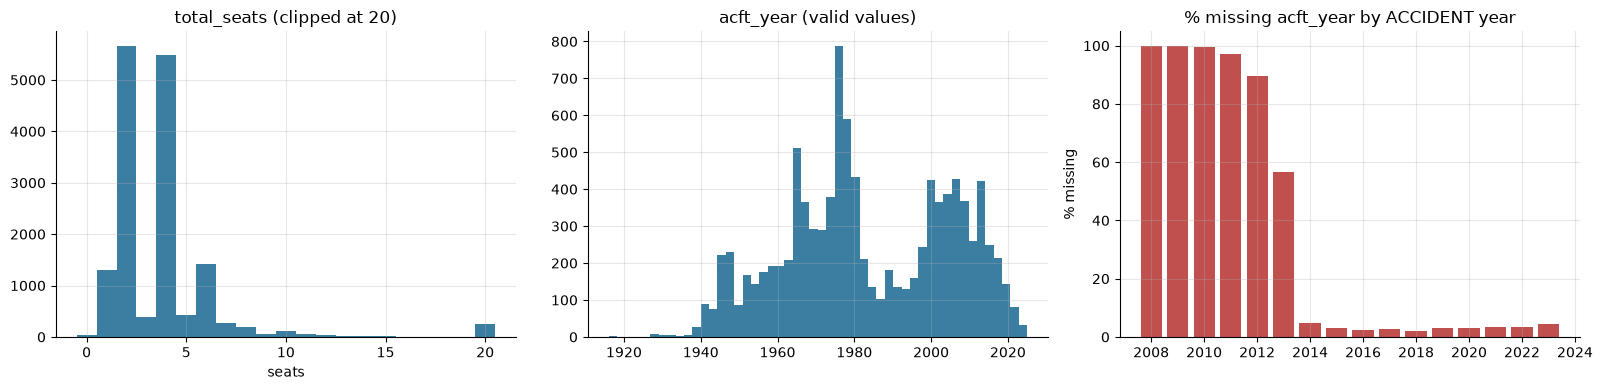

{2008: 100, 2009: 100, 2010: 99, 2011: 97, 2012: 89, 2013: 57, 2014: 5, 2015: 3, 2016: 2, 2017: 3, 2018: 2, 2019: 3, 2020: 3, 2021: 4, 2022: 3, 2023: 5}


In [20]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(A.total_seats.clip(upper=20).dropna(), bins=np.arange(-0.5, 21.5, 1), color="#3b7ea1")
ax[0].set_title("total_seats (clipped at 20)"); ax[0].set_xlabel("seats")
ax[1].hist(y[(y > 1900)].dropna(), bins=50, color="#3b7ea1"); ax[1].set_title("acft_year (valid values)")
miss = A.groupby("ev_year")["acft_year"].apply(lambda s: s.isna().mean())
ax[2].bar(miss.index, miss.values * 100, color="#c0504d"); ax[2].set_title("% missing acft_year by ACCIDENT year"); ax[2].set_ylabel("% missing")
plt.tight_layout(); plt.show()
print((miss * 100).round(0).astype(int).to_dict())

In [21]:
# Is missing acft_year informative?  Compare only the years where it is almost always present.
late = A[A.ev_year >= 2014]
print("ev_year >= 2014: share missing =", round(late.acft_year.isna().mean(), 3))
print("fatal rate, acft_year missing vs present (all years):", A.groupby(A.acft_year.isna())["fatal"].mean().round(3).to_dict())
print("fatal rate, acft_year missing vs present (2014+):    ", late.groupby(late.acft_year.isna())["fatal"].mean().round(3).to_dict())
print("fatal rate by aircraft-year band:")
print(A.groupby(pd.cut(A.acft_year, [1900, 1950, 1970, 1990, 2005, 2026]), observed=True)["fatal"].agg(["mean", "size"]).round(3))
print("\nfatal rate by seats band:")
print(A.groupby(pd.cut(A.total_seats, [-1, 1, 2, 4, 6, 10, 100, 1e5]), observed=True)["fatal"].agg(["mean", "size"]).round(3))

ev_year >= 2014: share missing = 0.032
fatal rate, acft_year missing vs present (all years): {False: 0.176, True: 0.161}
fatal rate, acft_year missing vs present (2014+):     {False: 0.169, True: 0.2}
fatal rate by aircraft-year band:
               mean  size
acft_year                
(1900, 1950]  0.124   756
(1950, 1970]  0.162  2253
(1970, 1990]  0.184  3110
(1990, 2005]  0.189  1847
(2005, 2026]  0.186  2194

fatal rate by seats band:
                    mean  size
total_seats                   
(-1.0, 1.0]        0.172  1332
(1.0, 2.0]         0.166  5663
(2.0, 4.0]         0.155  5879
(4.0, 6.0]         0.236  1849
(6.0, 10.0]        0.204   662
(10.0, 100.0]      0.141   220
(100.0, 100000.0]  0.006   168


**Interpretation.**
- **`total_seats`:** 37 rows with 0 seats (gliders and balloons mostly, so partly legitimate: pilot not counted) and **168 rows with > 100 seats, up to 8,300**. These are all airplanes, 158 of them `far_part 121` (airlines): large aircraft are real, but values like 1,979, 2,500, 3,300 or 8,300 are clearly typos (one is a year). Those 168 rows have a fatal rate of 0.6%, so "airliner" is a strong signal on its own. Odd/even counts are plausible.
- **`acft_year`:** 1 value of 0, 2 values below 1900 (163 and 1062) and **86 values later than the accident year** (almost always by 1 year, which may be a model-year convention rather than an error). Ages are otherwise plausible.
- **The 40% missing is not random: it is a time effect.** `acft_year` is missing in ~100% of 2008–2010, 89% in 2012, 57% in 2013 and only ~3% from 2014 on. So the missingness is a proxy for `ev_year` (probably a registration-data join that did not exist in the early years), not a property of the aircraft. Inside 2014+ the rows with missing `acft_year` have a fatal rate of 20% vs 17%: weak evidence.
- Fatal rate vs `acft_year` is mild (12% for pre-1950 up to ~19% for 1990+); vs seats, it peaks at 5–6 seats (24%) and collapses for > 100 (0.6%).

**→ NB1:** treat 0, <1900 and > `ev_year`+1 as `NaN`; for seats treat 0 as `NaN`, and either cap at a plausible maximum (e.g. 600) or create `is_large_aircraft` (> 20 seats). Add `acft_year_missing`; **check whether `ev_year` is stable between `learn` and `predict`** (Person 2 / Person 1): if the early years are in `predict` too, the indicator is safe, and imputing with the median/age is a reasonable choice. Consider using **aircraft age** (`ev_year − acft_year`) rather than the year.

## Part 4 · 7. The required feature `seat_vintage_ratio` (diagnostic only)

**What we do:** the project brief requires `seat_vintage_ratio = total_seats / acft_year` in every final model. NB0 must not create features, so here we only *compute it on a throw-away series* to see how it behaves, and flag questions for NB1.

> **Note for the group:** in the PDF, this requirement appears under section 3.3 (Target) but is numbered "5.2.1", which looks out of place (the document has no such subsection). Worth confirming with the teaching staff that it is intended before building on it.

inf values (acft_year == 0): 1 · NaN: 44.7%
{'count': 9392.0, 'mean': 0.00306, 'std': 0.01493, 'min': 0.0, '25%': 0.001, '50%': 0.00199, '75%': 0.00204, 'max': 1.0}

correlation(ratio, total_seats) on valid rows: 0.99994
share of rows where both inputs are present: 55.3%


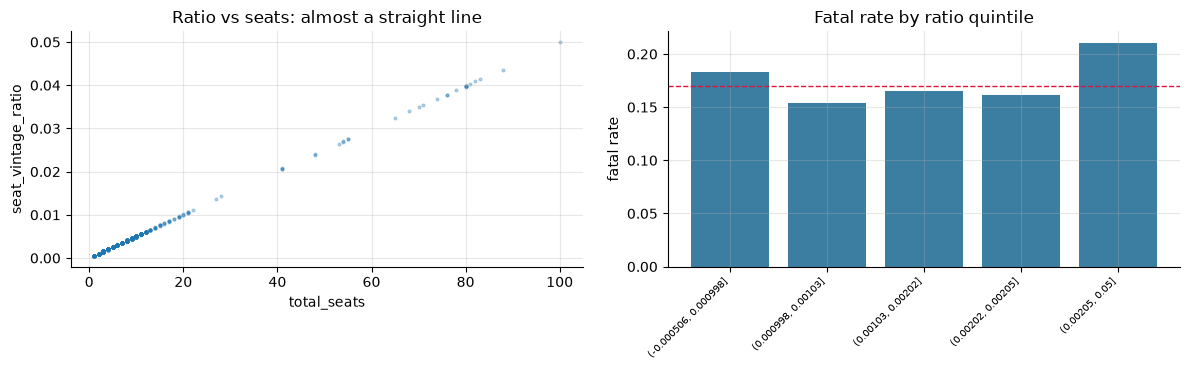

In [22]:
ratio = A["total_seats"] / A["acft_year"]          # throw-away series, not added to learn
print("inf values (acft_year == 0):", np.isinf(ratio).sum(), "· NaN:", f"{ratio.isna().mean():.1%}")
r = ratio.replace([np.inf, -np.inf], np.nan)
print(r.describe().round(5).to_dict())

ok = (A.acft_year > 1900) & A.total_seats.between(1, 100) & r.notna()
print("\ncorrelation(ratio, total_seats) on valid rows:", round(np.corrcoef(r[ok], A.total_seats[ok])[0, 1], 5))
print("share of rows where both inputs are present:", f"{(A.total_seats.notna() & A.acft_year.notna()).mean():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].scatter(A.total_seats[ok], r[ok], s=4, alpha=.3); ax[0].set_xlabel("total_seats"); ax[0].set_ylabel("seat_vintage_ratio")
ax[0].set_title("Ratio vs seats: almost a straight line")
plot_num_vs_target(A[ok].assign(ratio=r[ok]), "ratio", q=5, ax=ax[1], title="Fatal rate by ratio quintile")
plt.tight_layout(); plt.show()

**Interpretation.**
- The feature is **undefined for ~45% of the rows** (`acft_year` or `total_seats` missing), explodes to `inf` when `acft_year = 0`, and is polluted by the impossible seat counts (a few absurd seat counts give outlying ratios).
- On valid rows it is **almost perfectly correlated with `total_seats`** (r ≈ 1.00): since years only vary between ~1900 and 2025 (±3%), dividing by them barely changes anything. So the "vintage" part adds essentially no information, and the signal it carries is the seat count itself.
- The brief's claim (denser seating in newer aircraft, slower evacuation) cannot really be tested with this ratio on this data: most accidents are in 2–4 seat light aircraft.

**→ NB1:** build it **after** cleaning (`acft_year` and `total_seats` repaired), decide how to handle `NaN` (the rule must be explicit and applied identically in `predict`), and justify it honestly in the feature engineering section, including its collinearity with `total_seats` (keep one of them in linear models). Question for the group: `acft_year` imputation strategy matters a lot here.

## Part 4 · 8. Relations inside the group

**What we do:** Spearman correlation between the numeric columns of this group and with `fatal`. We use a cleaned *copy* (impossible values → NaN) only so that outliers don't dominate.

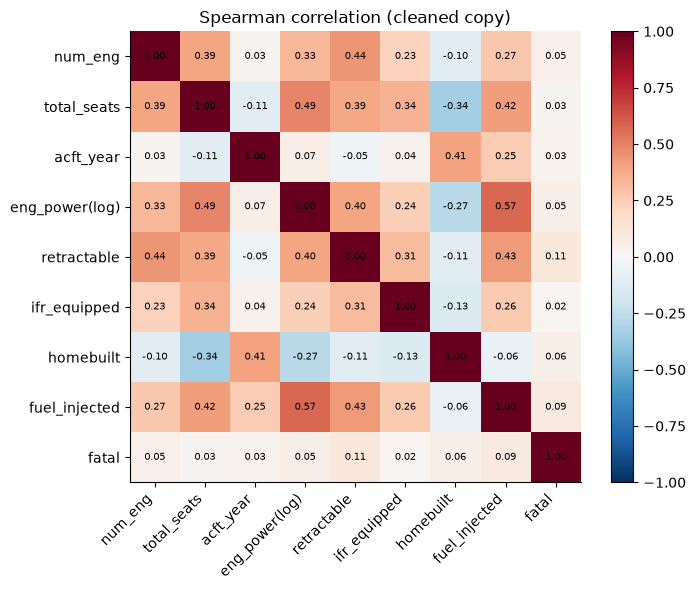

retractable       0.106
fuel_injected     0.091
homebuilt         0.060
eng_power(log)    0.055
num_eng           0.052
acft_year         0.034
total_seats       0.029
ifr_equipped      0.023
Name: fatal, dtype: float64


In [23]:
C = pd.DataFrame({
    "num_eng": A.num_eng,
    "total_seats": A.total_seats.where(A.total_seats.between(1, 100)),
    "acft_year": A.acft_year.where((A.acft_year > 1900) & (A.acft_year <= A.ev_year + 1)),
    "eng_power(log)": np.log10(A.eng_power.where(A.eng_power > 0)),
    "retractable": (A.fixed_retractable == "RETR").astype(int),
    "ifr_equipped": A.ifr_equipped_cert,
    "homebuilt": (A.homebuilt_u == "Y").astype(int),
    "fuel_injected": A.carb_fuel_injection.map({"FINJ": 1, "CARB": 0}),
    "fatal": A.fatal,
})
corr = C.corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns); ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)): ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im); plt.title("Spearman correlation (cleaned copy)"); plt.tight_layout(); plt.show()
print(corr["fatal"].drop("fatal").sort_values(key=abs, ascending=False).round(3))

**Interpretation.** The strongest links with `fatal` are modest (|ρ| of a few hundredths to ~0.1): `retractable`, `fuel_injected`, `homebuilt`, `num_eng`. No single aircraft variable is a silver bullet, so the value will come from combining them with flight-phase, pilot and weather information (interactions across groups, Person 5). Among themselves, `retractable`, `eng_power`, `num_eng`, `total_seats` and `fuel_injected` move together (bigger, more complex aircraft): redundancy to keep in mind for feature selection and for linear models.

**→ NB1:** consider a compound "aircraft complexity" feature or let tree-based models find the interactions; check VIF/regularisation if a linear model is used.

## Part 4 · 9. Findings and decisions for NB1 (input for Person 1's final table)

In [24]:
findings = pd.DataFrame([
    ("acft_category, homebuilt", "Mixed case (AIR/air, Y/y), ~25% lowercase, same in predict; lowercase carries no information", "Upper-case in both files; group categories with < 30 rows into OTHER"),
    ("acft_make", "2,914 raw values, long tail, ~2,300 appear once; 13% of predict rows have a make unseen in learn", "Normalise text; keep top 30-50 makes + OTHER; make_is_rare flag; encoding that handles unseen values and is fitted inside CV"),
    ("acft_make", "Big makes differ a lot (Boeing 3% ... Cirrus 33%) vs 17% base", "Keep as a feature (signal is real)"),
    ("carb_fuel_injection", "NaN is structural (not applicable to turbines/electric)", "Explicit category NOT_APPLICABLE vs UNKNOWN; do not impute"),
    ("eng_type", "Rare codes (HR, GTFN, LR, ELEC, NONE, UNK) with <= 23 rows", "Group rare codes into OTHER"),
    ("num_eng", "0 = gliders/balloons (valid); 3+ engines almost nonexistent", "Keep 0; cap at 3+"),
    ("eng_power", "Unit changes (HP vs lbs of thrust), 171 zeros, extreme outliers", "0 -> NaN; split into eng_power_hp and eng_thrust_lbs by eng_type; log/winsorise"),
    ("total_seats", "168 rows > 100 seats (some are typos, e.g. 8,300); 37 zeros", "0 -> NaN; cap or add is_large_aircraft; keep NaN indicator"),
    ("acft_year", "1 zero, 2 < 1900, 86 > ev_year (mostly by 1 year)", "Invalid -> NaN; use aircraft age (ev_year - acft_year)"),
    ("acft_year", "Missingness (40%) is a time effect: ~100% in 2008-2010, ~3% from 2014", "Add acft_year_missing; check ev_year distribution in learn vs predict; choose imputation consciously"),
    ("seat_vintage_ratio", "Required feature; NaN for ~45% of rows, inf when acft_year = 0, r ~ 1 with total_seats", "Build after cleaning; define NaN rule; justify honestly; confirm 5.2.1 with teachers"),
    ("fixed_retractable, num_eng, eng_power, total_seats", "Move together (aircraft complexity)", "Check redundancy in feature selection / VIF if linear model"),
], columns=["Column(s)", "Finding", "Decision / question for NB1"])
pd.set_option("display.max_colwidth", 120)
findings

,Column(s),Finding,Decision / question for NB1
0,"acft_category, homebuilt","Mixed case (AIR/air, Y/y), ~25% lowercase, same in predict; lowercase carries no information",Upper-case in both files; group categories with < 30 rows into OTHER
1,acft_make,"2,914 raw values, long tail, ~2,300 appear once; 13% of predict rows have a make unseen in learn",Normalise text; keep top 30-50 makes + OTHER; make_is_rare flag; encoding that handles unseen values and is fitted i...
2,acft_make,Big makes differ a lot (Boeing 3% ... Cirrus 33%) vs 17% base,Keep as a feature (signal is real)
3,carb_fuel_injection,NaN is structural (not applicable to turbines/electric),Explicit category NOT_APPLICABLE vs UNKNOWN; do not impute
4,eng_type,"Rare codes (HR, GTFN, LR, ELEC, NONE, UNK) with <= 23 rows",Group rare codes into OTHER
5,num_eng,0 = gliders/balloons (valid); 3+ engines almost nonexistent,Keep 0; cap at 3+
6,eng_power,"Unit changes (HP vs lbs of thrust), 171 zeros, extreme outliers",0 -> NaN; split into eng_power_hp and eng_thrust_lbs by eng_type; log/winsorise
7,total_seats,"168 rows > 100 seats (some are typos, e.g. 8,300); 37 zeros",0 -> NaN; cap or add is_large_aircraft; keep NaN indicator
8,acft_year,"1 zero, 2 < 1900, 86 > ev_year (mostly by 1 year)",Invalid -> NaN; use aircraft age (ev_year - acft_year)
9,acft_year,"Missingness (40%) is a time effect: ~100% in 2008-2010, ~3% from 2014",Add acft_year_missing; check ev_year distribution in learn vs predict; choose imputation consciously


# ━━━━━━━━━━ PART 5 · Pilot, flight and cross-group interactions (Person 5) ━━━━━━━━━━

Columns covered (8): `far_part`, `type_fly`, `flt_plan_filed`, `second_pilot`, `pilot_age`, `pilot_sex`, `pilot_med_certf`, `phase`, plus three cross-group interactions.

As in the other parts, NB0 does not change the data and does not train models: all checks use throw-away copies (`P5`, `P5_pred`), and the real cleaning is listed as a decision for NB1 at the end of this part.

In [61]:
GROUP_P5 = [
    "far_part", "type_fly", "flt_plan_filed", "second_pilot",
    "pilot_age", "pilot_sex", "pilot_med_certf", "phase"
]

P5 = learn.copy()
P5_pred = predict.copy()

## 5.1 Overview of Pilot and Flight Columns

### What we do:
Inspect data types, missing value percentages in learn and predict, and cardinality across the 8 pilot and flight columns.


In [62]:
ov_p5 = pd.DataFrame({
    "dtype": P5[GROUP_P5].dtypes.astype(str),
    "missing_learn_%": (P5[GROUP_P5].isna().mean() * 100).round(1),
    "missing_predict_%": (P5_pred[GROUP_P5].isna().mean() * 100).round(1),
    "n_unique_learn": P5[GROUP_P5].nunique(dropna=True),
})
print("=== 5.1 OVERVIEW ===")
print(ov_p5.to_string())

=== 5.1 OVERVIEW ===
                   dtype  missing_learn_%  missing_predict_%  n_unique_learn
far_part             str              0.0                0.0              15
type_fly             str              4.6                4.6              22
flt_plan_filed       str              1.4                1.3               7
second_pilot         str              7.0                6.9               4
pilot_age        float64              0.7                1.0              91
pilot_sex            str             15.9               16.6               2
pilot_med_certf      str              0.7                0.8               7
phase                str              0.1                0.0              12


### Interpretation:

Missingness rates are closely aligned between learn and predict (no distribution shift between train and test): pilot_sex is missing in 15.9% of learn rows (16.6% in predict), second_pilot in 7.0%, type_fly in 4.6%, and flt_plan_filed in 1.4%, while far_part, pilot_age, pilot_med_certf, and phase are almost complete (<1% missing).

pilot_age is stored as float64 only because of NaNs and contains 91 distinct values (potentially signalling out-of-range ages). The remaining 7 columns are categorical strings, some with long tails (type_fly has 22 levels, far_part has 15).

→ NB1: keep missingness explicit for pilot_sex, second_pilot, and type_fly rather than blind mode imputation, and clean impossible values in pilot_age before scaling or binning.

## 5.2 Rare Categories, `second_pilot` Casing, `pilot_age`, and `pilot_sex` Missingness

### What we do:
Check categorical frequency distributions, rare tails, mixed-case spelling in second_pilot, impossible values in pilot_age (< 14 or > 95), and why pilot_sex is missing in ~16% of accidents. All checks run on throw-away copies (P5, P5_pred).


In [63]:
for col in ["far_part", "type_fly", "flt_plan_filed", "second_pilot", "pilot_sex", "pilot_med_certf"]:
    vc = P5[col].value_counts(dropna=False)
    vals = [str(x) for x in P5[col].dropna().unique()]
    lower_map = {}
    for v in vals:
        lower_map.setdefault(v.lower(), []).append(v)
    mixed = {k: v for k, v in lower_map.items() if len(v) > 1}

    print(f"\n=== 5.2 {col} (learn) ===")
    if mixed:
        print("Mixed case variants:", mixed)
    tbl = pd.DataFrame({
        "n": vc,
        "share_%": (vc / len(P5) * 100).round(2),
        "fatal_rate": P5.groupby(col, dropna=False)["fatal"].mean().round(3),
    })
    print(tbl.sort_values("n", ascending=False).head(12).to_string())
    


=== 5.2 far_part (learn) ===
              n  share_%  fatal_rate
far_part                            
091       14964    88.13       0.175
137         841     4.95       0.119
135         547     3.22       0.197
121         299     1.76       0.010
PUBU        199     1.17       0.166
133          90     0.53       0.178
129          15     0.09       0.067
NUSN          5     0.03       0.200
UNK           4     0.02       0.000
NUSC          4     0.02       0.250
091K          4     0.02       0.000
103           2     0.01       0.000

=== 5.2 type_fly (learn) ===
              n  share_%  fatal_rate
type_fly                            
PERS      10923    64.33       0.188
INST       2319    13.66       0.092
AAPL        843     4.96       0.121
NaN         787     4.64       0.139
BUS         403     2.37       0.196
POSI        324     1.91       0.191
OWRK        254     1.50       0.173
AOBV        232     1.37       0.228
FLTS        203     1.20       0.192
FERY         93

=== 5.2 pilot_age checks ===
Summary: {'count': 16857.0, 'mean': 53.0, 'std': 16.1, 'min': 0.0, '25%': 42.0, '50%': 55.0, '75%': 65.0, 'max': 214.0}
Age < 14 (learn): 6 -> values: {0.0: 4, 7.0: 1, 1.0: 1}
Age > 95 (learn): 7 -> values: [97.0, 115.0, 116.0, 144.0, 181.0, 199.0, 214.0]
Age < 14 (predict): 1 | Age > 95 (predict): 1


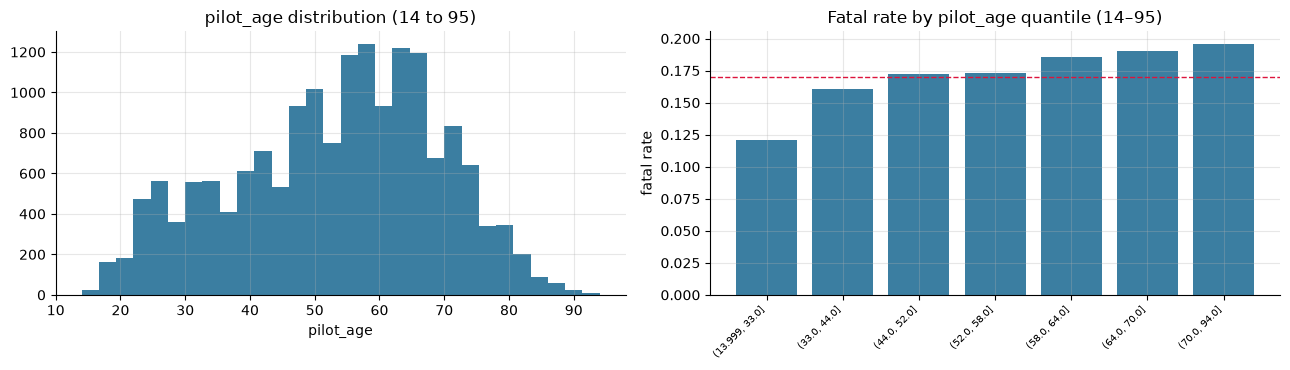

                 rate     n
pilot_age                  
(13.999, 33.0]  0.121  2524
(33.0, 44.0]    0.161  2361
(44.0, 52.0]    0.173  2611
(52.0, 58.0]    0.173  2369
(58.0, 64.0]    0.186  2570
(64.0, 70.0]    0.190  2193
(70.0, 94.0]    0.196  2216

=== 5.2 pilot_sex missingness (learn) ===
           count   mean
pilot_sex              
<NA>        2696  0.174
F            534  0.096
M          13749  0.172
Missing sex and missing age: 83 of 2696
ev_year
2008     2.0
2009     3.0
2010     4.0
2011     9.0
2012    22.0
2013    66.0
2014    79.0
2015    49.0
2016     3.0
2017     3.0
2018     2.0
2019     2.0
2020     4.0
2021     5.0
2022     3.0
2023     4.0
Name: sex_missing, dtype: float64


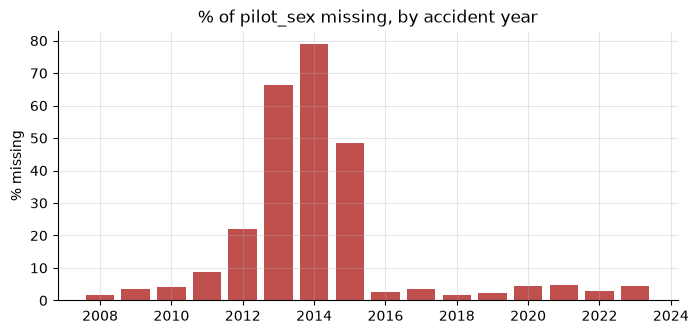

Missing in 2012-2015: 52.7 %
Missing in other years: 3.7 %
 predict, 2012-2015: 54.2 %
 predict, other years: 3.9 %


In [64]:
age = P5["pilot_age"]
print("=== 5.2 pilot_age checks ===")
print("Summary:", age.describe().round(1).to_dict())
print("Age < 14 (learn):", int((age < 14).sum()), "-> values:", age[age < 14].value_counts().to_dict())
print("Age > 95 (learn):", int((age > 95).sum()), "-> values:", age[age > 95].sort_values().tolist())
print("Age < 14 (predict):", int((P5_pred["pilot_age"] < 14).sum()),
      "| Age > 95 (predict):", int((P5_pred["pilot_age"] > 95).sum()))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].hist(age[(age >= 14) & (age <= 95)].dropna(), bins=30, color="#3b7ea1")
ax[0].set_title("pilot_age distribution (14 to 95)")
ax[0].set_xlabel("pilot_age")
g_age =plot_num_vs_target(P5[age.between(14, 95)], "pilot_age", q=7, ax=ax[1], title="Fatal rate by pilot_age quantile (14–95)")
plt.tight_layout()
plt.show()
print(g_age.round(3))

print("\n=== 5.2 pilot_sex missingness (learn) ===")
print(P5.groupby(P5["pilot_sex"].fillna("<NA>"))["fatal"].agg(["count", "mean"]).round(3))
print("Missing sex and missing age:", (P5["pilot_sex"].isna() & P5["pilot_age"].isna()).sum(), "of", P5["pilot_sex"].isna().sum())

P5["sex_missing"] = P5["pilot_sex"].isna()
by_year = P5.groupby("ev_year")["sex_missing"].mean() * 100
print(by_year.round(0))

plt.figure(figsize=(8, 3.5))
plt.bar(by_year.index, by_year.values, color="#c0504d")
plt.title("% of pilot_sex missing, by accident year")
plt.ylabel("% missing")
plt.show()

bloco = P5["ev_year"].between(2012, 2015)
print("Missing in 2012-2015:", round(P5[bloco]["sex_missing"].mean() * 100, 1), "%")
print("Missing in other years:", round(P5[~bloco]["sex_missing"].mean() * 100, 1), "%")

P5_pred["sex_missing"] = P5_pred["pilot_sex"].isna()
bloco_p = P5_pred["ev_year"].between(2012, 2015)
print(" predict, 2012-2015:", round(P5_pred[bloco_p]["sex_missing"].mean() * 100, 1), "%")
print(" predict, other years:", round(P5_pred[~bloco_p]["sex_missing"].mean() * 100, 1), "%")

### Interpretation:

second_pilot casing & missingness: Mixed case splits both levels (N 9,692 vs n 3,324; Y 2,124 vs y 655). Once unified, N and Y have virtually identical fatality rates (17.7% vs 17.3%, right at the 17.0% base rate), whereas missing (NaN, 6.97% of rows) drops to 8.9%. Missingness is informative, not random. 

far_part is dominated by Part 91 general aviation (88.13%, 17.5% fatal), while Part 121 commercial airlines (1.76%, n=299) have a 1.0% fatal rate and Part 137 agricultural 
(4.95%) is lower at 11.9%. Several codes (091K, 103, 107, 125, 437, NUSN, NUSC, UNK) have ≤ 5 rows.

type_fly: personal flights (PERS) dominates the data (n = 10,923, 64.33%) with a fatal rate of 0.188, close to the base rate. Instructional flights (INST, n = 2,319, 13.66%) are much safer (0.092) and agricultural flights (AAPL, n = 843, 4.96%) are also lower (0.121). BUS (403, 0.196) and AOBV (232, 0.228) are above the base rate. ASHO has the highest fatal rate (0.333) but only 66 rows, so this estimate is less reliable. The empty values (787 rows, 4.64%, 0.139) and the code UNK mean the same thing (unknown).

flt_plan_filed: flights with an IFR plan (9.49%) have a 26.3% fatal rate vs 10.2% for VFR (5.19%) and 16.6% for NONE (75.1%). Likely because IFR plans correlate with more complex cross-country flights, being more exigent, while NONE dominates because local, recreational, training, and short general-aviation flights typically operate without a filed flight plan.

pilot_med_certf: NONE (20.3% fatal) and CL3 (18.3%) are riskier than CL1 airline-level medicals (14.6%) which means that pilots without any certificates are the most associated with fatal accidents. We can also notice that with the increase of difficulty of the certificate, the fatal_rate decreases. SPRT (11.8%) is the main exception, despite lighter medical rules, sport pilots operate smaller aircraft restricted to daytime VFR conditions, lowering exposure to severe accidents.

pilot_age anomalies & risk curve: pilot_age (n = 16,857, mean 53.0, median 55.0) peaks around ages 45–70, while learn contains clear anomalies—6 rows < 14 (0.0: 4, 7.0: 1, 1.0: 1) and 7 rows > 95 (97.0 to 214.0), plus 1 < 14 and 1 > 95 in predict—and fatal rate rises steadily with age across 14–95 from ~0.121 in [13.999, 33.0] to ~0.196 in [70.0, 94.0], crossing the ~0.170 baseline around an age between 44 and 52 and requiring explicit outlier/missing handling in NB1

pilot_sex missingness (2,696 rows, 15.88%): Female pilots (F, 534 rows, 3.15%) show a lower fatal rate (0.096) than males (M, 13,749 rows, 80.98%, 0.172), while missing values sit right around the overall rate (0.174), so “missing” does not say anything about the target. The missing values are not linked to the age: only 83 of the 2,696 rows also have a missing pilot_age. They are linked to time: the missing share is only 2–9% in most years, but it jumps to 22% in 2012, 66% in 2013, 79% in 2014 and 49% in 2015, and goes back to about 3% in 2016. In 2012–2015 the share is 52.7%, against 3.7% in all other years, and predict has the same pattern (54.2% vs 3.9%). This looks like a data-collection problem in those years, not a property of the pilots. We can not make a fair comparison between F and M because F does not have a significant amount of rows (just 534 F against 13,749 M).

→ NB1: (1) uppercase second_pilot in both learn and predict and keep NaN as its own category (UNKNOWN); (2) group rare levels (< 30 rows) into OTHER for far_part, type_fly, flt_plan_filed, and pilot_med_certf; (3) replace pilot_age outlires (< 14 or > 95) with NaN, add an age_missing flag, and impute with median; (4) encode pilot_sex NaN as UNKNOWN and verify during feature selection whether pilot_sex_missing adds value beyond ev_year.

## 5.3 Phase of Flight vs. `fatal` (`learn`)
 
We designed a plot with the fatality rate across flight phases (phase) for categories with at least 15 observations.


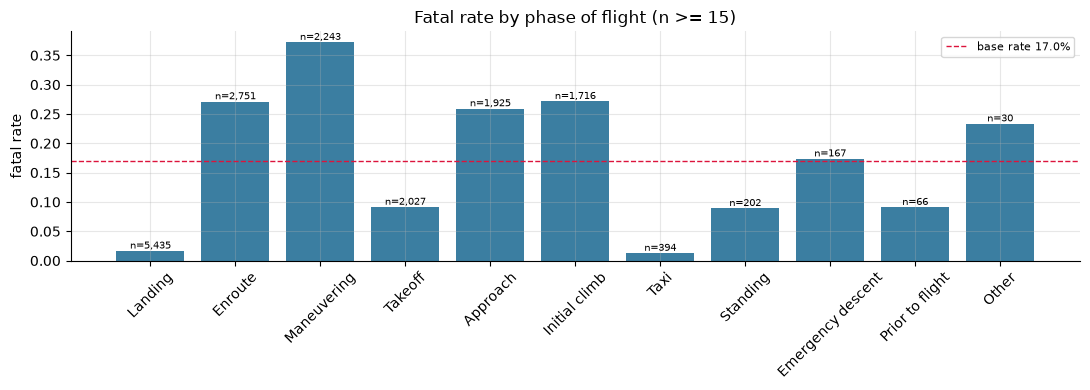

                    rate     n
phase                         
Maneuvering        0.372  2243
Initial climb      0.272  1716
Enroute            0.271  2751
Approach           0.259  1925
Other              0.233    30
Emergency descent  0.174   167
Takeoff            0.091  2027
Prior to flight    0.091    66
Standing           0.089   202
Landing            0.017  5435
Taxi               0.013   394


In [65]:
fig, ax = plt.subplots(figsize=(11, 4))
g_phase = plot_cat_vs_target(P5, "phase", min_n=15, top=15, ax=ax, title="Fatal rate by phase of flight (n >= 15)")
plt.tight_layout()
plt.show()
print(g_phase.sort_values("rate", ascending=False).round(3))

### Interpretation:

phase is one of the strongest predictors in the entire dataset, separating low-energy ground accidents from high-energy in-flight accidents:

High-risk phases: Maneuvering (37.2% fatal, n=2,243), Initial climb (27.2%, n=1,716), Enroute (27.1%, n=2,751), and Approach (25.9%, n=1,925) are well above the 17.0% base rate.

Low-risk phases: Landing accounts for nearly a third of all accidents (32.0%, n=5,435) with only 1.7% fatality; Taxi is 1.3% (n=394), Standing 8.9% (n=202), and Takeoff 9.1% (n=2,027).

Rare categories (Pushback/towing n=14, NaN n=9) have tiny counts.

A possible reason is that accidents on the ground or close to the runway (Taxi, Landing, Takeoff) happen at lower speeds, while the airborne phases (Maneuvering, Initial climb, Enroute, Approach) involve higher speeds and altitude and less room to recover.

→ NB1: retain phase as a core feature, group Pushback/towing and NaN into OTHER (or UNKNOWN). 

## 5.4 Cross-Group Interactions (`learn`)

We examine joint relationships across operational, environmental, and flight-rule variables to identify non-linear fatality regimes that single-variable summaries can mask:

1. **Weather $\times$ flight plan $\times$ IFR capability (`5.4.1`):** Compare fatality rates across `wx_cond_basic`, `flt_plan_filed`, and `ifr_equipped_cert` for combinations with at least 30 observations (`n >= 30`).
2. **Nighttime $\times$ phase of flight (`5.4.2` & `5.4.2b`):** Isolate low-light/night conditions (`NITE`, `NDRK`, `NBRT`) across flight phases and inspect a `phase` $\times$ `light_cond` fatality pivot across the top 8 phases.
3. **Agricultural operations (`5.4.3`):** Inspect `AAPL` and `FAR 137` flights together, checking volume, fatality rate, top aircraft makes (`acft_make`), and overlap between `type_fly` and `far_part`.

In [66]:
# 1) IMC / VMC x flight plan x IFR equipped/certified
g_imc = (
    P5.groupby(["wx_cond_basic", "flt_plan_filed", "ifr_equipped_cert"], dropna=False)["fatal"]
      .agg(n="size", fatal_rate="mean")
      .query("n >= 30")
      .sort_values("fatal_rate", ascending=False)
)
print("=== 5.4.1 wx_cond_basic x flt_plan_filed x ifr_equipped_cert (n >= 30) ===")
print(g_imc.round(3).to_string())

# 2) Night (NITE, NDRK, NBRT) x phase
night_df = P5[P5["light_cond"].isin(["NITE", "NDRK", "NBRT"])]
night_phase = (
    night_df.groupby("phase", dropna=False)["fatal"]
    .agg(n="size", fatal_rate="mean")
    .sort_values("fatal_rate", ascending=False)
)
print("\n=== 5.4.2 NIGHT x PHASE (light_cond in NITE, NDRK, NBRT) ===")
print(night_phase.round(3).to_string())

top8_phases = P5["phase"].value_counts().head(8).index
sub_l = P5[P5["phase"].isin(top8_phases)]
print("\n=== 5.4.2b Fatal rate by phase x light_cond (top 8 phases) ===")
print(sub_l.pivot_table(index="phase", columns="light_cond", values="fatal", aggfunc="mean").round(3).to_string())

# 3) Agricultural flights (AAPL / FAR 137) x make
agri_mask = (P5["type_fly"] == "AAPL") | (P5["far_part"].astype(str).str.contains("137", na=False))
agri_df = P5[agri_mask]
print(f"\n=== 5.4.3 Agricultural (AAPL / FAR 137) flights: n={len(agri_df)}, fatal_rate={agri_df['fatal'].mean():.3f} ===")
print("Top makes in agricultural / FAR 137:")
print(agri_df["acft_make"].value_counts(dropna=False).head(8).to_string())
print("\ntype_fly vs far_part inside agricultural / FAR 137:")
print(pd.crosstab(agri_df["type_fly"].fillna("<NA>"), agri_df["far_part"].fillna("<NA>"), margins=True).to_string())

=== 5.4.1 wx_cond_basic x flt_plan_filed x ifr_equipped_cert (n >= 30) ===
                                                    n  fatal_rate
wx_cond_basic flt_plan_filed ifr_equipped_cert                   
IMC           NONE           1                     40       0.925
                             0                    229       0.751
              IFR            1                    211       0.555
                             0                    209       0.459
VMC           NaN            1                     49       0.224
              IFR            0                    564       0.190
                             1                    600       0.170
              CVFR           0                    559       0.170
              NONE           0                  10845       0.153
                             1                   1602       0.144
              CVFR           1                     80       0.112
              NaN            0                    181       0.110
 

### 5.4.1 
### wx_cond_basic $\times$ flt_plan_filed $\times$ ifr_equipped_cert:
Flying in IMC without a filed flight plan (NONE) drives fatality rates up to 0.925 (ifr_equipped_cert=1, n=40) and 0.751 (0, n=229), likely reflecting inadvertent weather encounters, whereas active IFR plans in IMC reduce lethality (0.555 and 0.459), and VMC flights stay far safer overall (0.079–0.224).

### 5.4.2 
### light_cond $\times$ phase: 
Nighttime conditions (NITE, NDRK, NBRT) sharply amplify airborne risk (Maneuvering 0.670, Initial climb 0.657, Enroute 0.456, Approach 0.434), peaking in dark-night (NDRK) Maneuvering (0.833) and Initial climb (0.825), while ground and landing phases stay low-risk (Landing 0.013).

### 5.4.3 
### AAPL / FAR 137 agricultural flights:
Agricultural operations (n=857) show a lower-than-average fatal rate (0.120) with near-complete overlap between type_fly == 'AAPL' and far_part == '137' (827 shared rows), while also exposing duplicate manufacturer strings (AIR TRACTOR vs. AIR TRACTOR INC, GRUMMAN variants).


→ NB1: Create explicit interaction indicators for IMC + unfiled flight plan (wx_cond_basic == 'IMC' & flt_plan_filed == 'NONE') and night/dark + high-risk airborne phase, add a combined is_agricultural flag (AAPL or FAR 137), and standardize inconsistent acft_make names if kept.

## 5.5 Findings and Decisions for `NB1`

### Final Conclusions & Action Plan for `NB1`
* **Clean before encoding:** Standardize case (`second_pilot`), convert invalid `pilot_age` values (`< 14` or `> 95`) to `NaN` with an `age_missing` indicator, and group low-count categorical levels into `UNKNOWN`.
* **Keep missing values explicit:** the missing `second_pilot` (fatal rate 0.089) looks informative, so keep it as its own category. `pilot_sex` is missing mostly in 2012–2015 (a data-collection effect, not a risk signal): use a `MISSING` category instead of filling with the most frequent value, and check the overlap with `ev_year`.
* **Validate interactions empirically:** High-risk combinations (`IMC` without flight plan/IFR, night `Maneuvering`/`Climb`/`Enroute`, and agricultural `AAPL`/`FAR 137` + `acft_make`) are strong candidates for feature engineering in `NB1`, but only features that improve cross-validated `F1` should stay in the final pipeline.

In [67]:
import pandas as pd

df_P5 = pd.DataFrame([
    {
        "feature_or_group": "second_pilot",
        "eda_finding": "Mixed casing (N/n, Y/y) and informative NaN with lower fatal rate (0.089).",
        "nb1_decision": "Uppercase values in learn and predict, keep NaN as explicit UNKNOWN category."
    },
    {
        "feature_or_group": "far_part, type_fly, flt_plan_filed, pilot_med_certf",
        "eda_finding": "Heavy concentration in dominant levels (e.g., far_part 091, flt_plan_filed NONE) plus rare tail categories.",
        "nb1_decision": "Group rare levels (< 30 rows) into OTHER; keep explicit missing/unknown handling."
    },
    {
        "feature_or_group": "pilot_age",
        "eda_finding": "Monotonic rise in fatal rate across valid ages (14–95), plus impossible/extreme outliers (< 14 or > 95) in learn and predict.",
        "nb1_decision": "Replace values < 14 or > 95 with NaN, add age_missing flag, and impute remaining missing values with median."
    },
    {
        "feature_or_group": "pilot_sex",
        "eda_finding": "15.88% missing, concentrated in 2012-2015 (52.7% vs 3.7% in other years, same in predict); not linked to pilot_age; F has a lower fatal rate (0.096) but only 534 rows.",
        "nb1_decision": "Encode as M / F / MISSING (do not fill with M); check the overlap with ev_year, because the missing flag is almost the same as the 2012–2015 period."
    },
    {
        "feature_or_group": "phase",
        "eda_finding": "Strong predictor separating low-risk ground/landing phases from high-risk airborne phases; tiny counts in Pushback/towing and NaN.",
        "nb1_decision": "Retain phase as core feature and group Pushback/towing and NaN into or UNKNOWN."
    },
    {
        "feature_or_group": "Interactions (wx x flt_plan, night x phase, agricultural)",
        "eda_finding": "IMC + NONE and night/dark airborne phases show sharply elevated fatality; AAPL and FAR 137 overlap heavily; acft_make has duplicate naming variants.",
        "nb1_decision": "Create flags for IMC + unfiled flight plan and night/dark + high-risk airborne phase; add is_agricultural flag; standardize acft_make if kept."
    }
])

pd.set_option("display.max_colwidth", None)
display(df_P5)

,feature_or_group,eda_finding,nb1_decision
0,second_pilot,"Mixed casing (N/n, Y/y) and informative NaN with lower fatal rate (0.089).","Uppercase values in learn and predict, keep NaN as explicit UNKNOWN category."
1,"far_part, type_fly, flt_plan_filed, pilot_med_certf","Heavy concentration in dominant levels (e.g., far_part 091, flt_plan_filed NONE) plus rare tail categories.",Group rare levels (< 30 rows) into OTHER; keep explicit missing/unknown handling.
2,pilot_age,"Monotonic rise in fatal rate across valid ages (14–95), plus impossible/extreme outliers (< 14 or > 95) in learn and predict.","Replace values < 14 or > 95 with NaN, add age_missing flag, and impute remaining missing values with median."
3,pilot_sex,"15.88% missing, concentrated in 2012-2015 (52.7% vs 3.7% in other years, same in predict); not linked to pilot_age; F has a lower fatal rate (0.096) but only 534 rows.","Encode as M / F / MISSING (do not fill with M); check the overlap with ev_year, because the missing flag is almost the same as the 2012–2015 period."
4,phase,Strong predictor separating low-risk ground/landing phases from high-risk airborne phases; tiny counts in Pushback/towing and NaN.,Retain phase as core feature and group Pushback/towing and NaN into or UNKNOWN.
5,"Interactions (wx x flt_plan, night x phase, agricultural)",IMC + NONE and night/dark airborne phases show sharply elevated fatality; AAPL and FAR 137 overlap heavily; acft_make has duplicate naming variants.,Create flags for IMC + unfiled flight plan and night/dark + high-risk airborne phase; add is_agricultural flag; standardize acft_make if kept.
